# Miniproyecto 4: Clasificación de Sonidos de la Naturaleza usando el Audio Spectrogram Transformer (AST)

**Universidad de los Andes — Maestría en Inteligencia Artificial (MAIA)**
**Curso:** Técnicas de Deep Learning (MAIA-4213)

### Autores
| Nombre Completo | Correo Electrónico | Código |
| :--- | :--- | :--- |
| **Otto Wilmer Castillo Santacruz** | `o.castillos@uniandes.edu.co` | `202611101` |
| **Edgar Andrés Pérez Mora** | `ea.perezm1@uniandes.edu.co` | `200822340` |
| **Silvio Yopasa Romero** | `s.yopasa@uniandes.edu.co` | `202615521` |

---

## Contexto
Los sonidos de la naturaleza y del entorno contienen información acústica estructurada en tiempo y frecuencia que permite identificar su fuente sonora —como cantos de aves, lluvia o agua corriendo, viento, vocalizaciones de mamíferos y ruidos ambientales—. Automatizar la clasificación de grabaciones ambientales resulta clave para el monitoreo bioacústico de ecosistemas, la detección temprana de perturbaciones (p. ej. motosierras o incendios), el etiquetado multimedia y la vigilancia acústica urbana. Sin embargo, a diferencia del habla o la música estructurada, los sonidos naturales presentan envolventes espectrales aperiódicas, transientes breves y alta variabilidad contextual.

Los modelos basados en *transformers*, introducidos originalmente para secuencias de texto mediante mecanismos de autoatención global [1] y extendidos a imágenes mediante el *Vision Transformer* (ViT) [2], ofrecen una ventaja sustancial frente a las redes convolucionales o recurrentes tradicionales: permiten relacionar en paralelo parches de tiempo y frecuencia distantes dentro de un espectrograma completo. El **Audio Spectrogram Transformer (AST)** [3] adapta directamente la arquitectura ViT al dominio acústico convirtiendo la forma de onda en un espectrograma log-Mel, dividiéndolo en parches bidimensionales solapados y aplicando autoatención sin recurrencia ni convoluciones profundas. Al aplicar *fine-tuning* sobre conjuntos ambientales de tamaño moderado como **ESC-50** [4] a partir de pesos preentrenados en un corpus masivo como **AudioSet** [5], con regularización desacoplada [6], AST alcanza una alta capacidad de discriminación.

En este miniproyecto se aborda la **clasificación multi-clase de 50 categorías ambientales completas** de **ESC-50** [4] ($2\,000$ grabaciones de $5.0\,\text{s}$, $40$ por clase), complementando el análisis de desempeño mediante su agrupación en las **5 macro-categorías oficiales** definidas por Piczak [4]: *Animales* (incluyendo aves, mamíferos e insectos), *Naturaleza y agua* (lluvia, olas, viento, gotas, tormenta), *Humanos (no habla)*, *Interiores y domésticos* y *Exteriores y urbanos*.

### A. Objetivo
- Realizar el ajuste fino (*fine-tuning*) durante $2$ épocas y la evaluación integral del modelo preentrenado **Audio Spectrogram Transformer (`MIT/ast-finetuned-audioset-10-10-0.4593`)** para clasificar sonidos ambientales y naturales del conjunto ESC-50 en sus $50$ categorías (y en las $5$ macro-categorías oficiales).

### B. Conjunto de Datos
- **ESC-50 (*Environmental Sound Classification*)** [4]: $2\,000$ grabaciones de $5.0\,\text{s}$ distribuidas uniformemente en $50$ clases ($5$ macro-categorías $\times$ $10$ clases) y $5$ *folds* oficiales sin fuga de grabaciones fuente. Se carga siguiendo la instrucción del enunciado con `load_dataset("confit/esc50-demo", "fold1", split="train"/"test")` (con respaldo automático a los espejos equivalentes de Hugging Face `confit/esc50-parquet`, `confit/esc50` y `ashraq/esc50` si el identificador demo no está disponible en el Hub).

### C. Actividades
1. **Procesamiento de audio:** diseñar un *pipeline* reproducible que convierta cada grabación en un espectrograma log-Mel normalizado con consistencia dimensional (`MAX_LENGTH = 512` cuadros $\times$ `128` bandas Mel), evitando fugas de datos entre particiones y evaluando aumento espectral con *SpecAugment* [7] en entrenamiento (sección 1).
2. **Implementación y *fine-tuning* de AST:** adaptar `ASTForAudioClassification` (`MIT/ast-finetuned-audioset-10-10-0.4593`) recortando de forma exacta sus *positional embeddings* 2D preentrenados, y realizar su *fine-tuning* durante $2$ épocas en comparación con un modelo acústico clásico (`MFCC + Regresión Logística`) y el codificador AST congelado (sección 2).
3. **Evaluación del modelo:** predecir sobre el conjunto de prueba independiente (`Fold 1`), reportar métricas globales y por categoría (*precision*, *recall*, *F1-score*, *Top-3 accuracy*), analizar las categorías con mejor y peor rendimiento y estudiar los patrones de error mediante la matriz de confusión, oclusión tiempo-frecuencia y proyecciones t-SNE (sección 3).

---
## 0. Configuración del Entorno e Importación de Librerías
Se importan las librerías para la carga del conjunto de datos (`datasets`), el procesamiento de audio y espectrogramas (`torchaudio`, `soundfile`), el modelado y ajuste fino en PyTorch con Hugging Face (`transformers` [8]), la extracción clásica de características y métricas (`scikit-learn`), la manipulación tabular (`pandas`, `numpy`) y la visualización (`matplotlib`, `seaborn`). Se fijan todas las semillas para garantizar la reproducibilidad y se selecciona automáticamente el acelerador disponible (GPU CUDA, Apple Silicon MPS o CPU).

In [1]:
# Importación de librerías, fijación de semillas y configuración del dispositivo
import contextlib
import gc
import hashlib
import io
import json
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import torch
import torch.nn as nn
import torchaudio
import transformers
from IPython.display import Markdown, display
from datasets import Audio, load_dataset
from huggingface_hub.utils import logging as hub_logging
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from transformers import (
    ASTFeatureExtractor,
    ASTForAudioClassification,
    AutoConfig,
    get_linear_schedule_with_warmup,
)
from transformers.utils import logging as hf_logging

RANDOM_STATE = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

# Reducir ruido informativo de Transformers y Hugging Face Hub en la salida del notebook
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

print(
    f"PyTorch {torch.__version__} | Torchaudio {torchaudio.__version__} | "
    f"Transformers {transformers.__version__} | Dispositivo: {DEVICE}"
)

W1120 17:26:26.373000 8686 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


PyTorch 2.15.0 | Torchaudio 2.11.1 | Transformers 5.23.0 | Dispositivo: mps


---
## 1. Preparación y Procesamiento de Audio para el Modelo AST
En esta sección se diseña el *pipeline* completo de ingestión, exploración acústica, partición sin fuga de información y transformación de las señales de audio en espectrogramas log-Mel normalizados. Siguiendo los mismos principios metodológicos de los miniproyectos anteriores:
1. Los pasos deterministas que **no aprenden parámetros de los datos** (decodificación, verificación de integridad, remuestreo a $16\,\text{kHz}$ y transformación log-Mel con parámetros fijos del modelo preentrenado) se aplican de manera uniforme sobre cada grabación.
2. Toda verificación estadística (longitud en cuadros de Kaldi, distribución empírica frente a AudioSet y ajuste del escalador del modelo clásico MFCC) se calcula **exclusivamente sobre `Train`**, reservando `Val` para la selección de hiperparámetros y `Test` para una evaluación final única.

### 1.1. Carga del Conjunto de Datos (ESC-50, Fold 1)
El enunciado indica cargar los datos mediante `load_dataset("confit/esc50-demo", "fold1", split="train")` y `split="test"`. La función `load_esc50_fold1()` intenta **primero exactamente `confit/esc50-demo`** (con respaldo automático a los espejos `confit/esc50-parquet`, `confit/esc50` y `ashraq/esc50` en caso de indisponibilidad). En la ejecución se cargó directamente **`confit/esc50-demo` (`fold1`)**, obteniendo **$1\,600$ grabaciones en `train`** y **$400$ grabaciones en `test` (`Fold 1`)** con columnas `['audio', 'sound', 'label']`, todas a **$44\,100\,\text{Hz}$** y **$5.0\,\text{s}$** de duración, mapeadas a sus $50$ clases y $5$ macro-categorías oficiales.

Asimismo, a partir de `datasets >= 4.x`, la decodificación automática de audio depende de `torchcodec` y bibliotecas nativas de FFmpeg que pueden fallar en ciertos entornos; por ello se desactiva la decodificación implícita (`Audio(decode=False)`) y se decodifica cada *buffer* WAV de forma determinista con `soundfile`.

In [2]:
# Carga del dataset ESC-50 (Fold 1) intentando primero el identificador del enunciado y respaldos equivalentes
def load_esc50_fold1():
    """Carga ESC-50 fold1 (train=1600, test=400) respetando la sintaxis solicitada en el enunciado."""
    candidates = [
        ("confit/esc50-demo", "fold1"),
        ("confit/esc50-parquet", "fold1"),
        ("confit/esc50", "fold1"),
    ]
    errors = []
    for repo_id, config_name in candidates:
        try:
            ds_train = load_dataset(repo_id, config_name, split="train")
            ds_test = load_dataset(repo_id, config_name, split="test")
            return ds_train, ds_test, f"{repo_id} ({config_name})"
        except Exception as exc:
            errors.append(f"{repo_id}: {type(exc).__name__}: {exc}")

    # Respaldo estándar: espejo completo ashraq/esc50 (split='train' con columna 'fold' in 1..5)
    try:
        full_ds = load_dataset("ashraq/esc50", split="train")
        ds_train = full_ds.filter(lambda x: int(x["fold"]) != 1)
        ds_test = full_ds.filter(lambda x: int(x["fold"]) == 1)
        return ds_train, ds_test, "ashraq/esc50 (reconstrucción fold1: fold != 1 vs fold == 1)"
    except Exception as exc:
        errors.append(f"ashraq/esc50: {type(exc).__name__}: {exc}")
        raise RuntimeError("No se pudo cargar ESC-50 desde ningún repositorio:\n" + "\n".join(errors))


dataset, val_dataset, DATASET_SOURCE = load_esc50_fold1()

# Evitar dependencia de torchcodec en datasets >= 4.x manteniendo acceso directo a bytes/path/array
if "audio" in dataset.column_names:
    dataset = dataset.cast_column("audio", Audio(decode=False))
if "audio" in val_dataset.column_names:
    val_dataset = val_dataset.cast_column("audio", Audio(decode=False))

print(f"Fuente cargada: {DATASET_SOURCE}")
print(f"Split entrenamiento (enunciado 'dataset'):     {len(dataset):,} grabaciones | Columnas: {dataset.column_names}")
print(f"Split prueba Fold 1 (enunciado 'val_dataset'): {len(val_dataset):,} grabaciones | Columnas: {val_dataset.column_names}")

Fuente cargada: confit/esc50-demo (fold1)
Split entrenamiento (enunciado 'dataset'):     1,600 grabaciones | Columnas: ['audio', 'sound', 'label']
Split prueba Fold 1 (enunciado 'val_dataset'): 400 grabaciones | Columnas: ['audio', 'sound', 'label']


In [3]:
# Decodificación segura de audio, mapeo a las 5 macro-categorías oficiales de ESC-50 y extracción de metadatos
ESC50_MACRO_GROUPS = {
    "Animales": [
        "dog", "rooster", "pig", "cow", "frog",
        "cat", "hen", "insects", "sheep", "crow",
    ],
    "Naturaleza y agua": [
        "rain", "sea_waves", "crackling_fire", "crickets", "chirping_birds",
        "water_drops", "wind", "pouring_water", "toilet_flush", "thunderstorm",
    ],
    "Humanos (no habla)": [
        "crying_baby", "sneezing", "clapping", "breathing", "coughing",
        "footsteps", "laughing", "brushing_teeth", "snoring", "drinking_sipping",
    ],
    "Interiores y domésticos": [
        "door_wood_knock", "mouse_click", "keyboard_typing", "door_wood_creaks", "can_opening",
        "washing_machine", "vacuum_cleaner", "clock_alarm", "clock_tick", "glass_breaking",
    ],
    "Exteriores y urbanos": [
        "helicopter", "chainsaw", "siren", "car_horn", "engine",
        "train", "church_bells", "airplane", "fireworks", "hand_saw",
    ],
}

GROUP_ORDER = list(ESC50_MACRO_GROUPS.keys())
CLASS_TO_MACRO_GROUP = {
    cls_name: group_name
    for group_name, cls_list in ESC50_MACRO_GROUPS.items()
    for cls_name in cls_list
}

# Equivalencias para normalizar variantes textuales en espejos de Hugging Face
CATEGORY_ALIASES = {
    "insects_(flying)": "insects",
    "insects_flying": "insects",
    "drinking,_sipping": "drinking_sipping",
    "drinking_sipping": "drinking_sipping",
    "door_knock": "door_wood_knock",
    "door,_wood_creaks": "door_wood_creaks",
    "door_wood_creaks": "door_wood_creaks",
}


def canonicalize_category(raw_cat: str) -> str:
    norm = str(raw_cat).strip().lower().replace(" ", "_")
    norm = CATEGORY_ALIASES.get(norm, norm)
    if norm in CLASS_TO_MACRO_GROUP:
        return norm
    norm_clean = norm.replace(",", "").replace("(", "").replace(")", "")
    return CATEGORY_ALIASES.get(norm_clean, norm_clean)


def decode_audio_entry(audio_entry) -> tuple:
    """Decodifica un registro de audio (bytes/path/array) a (onda mono float32, sr_orig, n_channels)."""
    if isinstance(audio_entry, dict):
        raw_bytes = audio_entry.get("bytes")
        if raw_bytes is not None:
            data, sr = sf.read(io.BytesIO(raw_bytes), dtype="float32", always_2d=True)
            n_ch = data.shape[1]
            return data.mean(axis=1).astype(np.float32), int(sr), int(n_ch)
        path = audio_entry.get("path")
        if path and Path(path).exists():
            data, sr = sf.read(path, dtype="float32", always_2d=True)
            n_ch = data.shape[1]
            return data.mean(axis=1).astype(np.float32), int(sr), int(n_ch)
        arr = audio_entry.get("array")
        sr = audio_entry.get("sampling_rate")
        if arr is not None and sr is not None:
            arr_np = np.asarray(arr, dtype=np.float32)
            if arr_np.ndim > 1:
                n_ch = arr_np.shape[1] if arr_np.shape[1] <= 8 else arr_np.shape[0]
                arr_np = arr_np.mean(axis=1 if arr_np.shape[1] <= 8 else 0)
            else:
                n_ch = 1
            return arr_np.astype(np.float32), int(sr), int(n_ch)
    raise ValueError(f"Formato de audio no soportado: {type(audio_entry)}")


def parse_esc50_filename(filename: str) -> tuple:
    """Extrae (fold, src_file, target_str) desde el formato estándar '{fold}-{src_file}-{take}-{target}.wav'."""
    stem = Path(str(filename)).stem
    parts = stem.split("-")
    if len(parts) >= 4 and parts[0].isdigit():
        return int(parts[0]), parts[1], parts[-1]
    return -1, stem, ""


def inspect_and_extract_split(hf_ds, source_split_name: str, waveform_store: list) -> list:
    """Extrae metadatos y estadísticos acústicos básicos por grabación."""
    cols = set(hf_ds.column_names)
    cat_feat = hf_ds.features.get("category") or hf_ds.features.get("label")
    label_feat = hf_ds.features.get("label") or hf_ds.features.get("target")
    rows = []

    for i, row in enumerate(hf_ds):
        wave, sr_orig, n_ch = decode_audio_entry(row["audio"])
        audio_idx = len(waveform_store)
        waveform_store.append(wave)

        fname = str(row.get("filename") or f"{source_split_name}_{i:04d}.wav")
        parsed_fold, parsed_src, _ = parse_esc50_filename(fname)

        fold_val = int(row["fold"]) if "fold" in cols and row["fold"] is not None else parsed_fold
        if fold_val <= 0:
            fold_val = 1 if source_split_name == "fold1_test" else -1
        src_file = str(row["src_file"]) if "src_file" in cols and row["src_file"] is not None else parsed_src

        # Resolver nombre de categoría textual de forma robusta
        if "category" in cols and row["category"] is not None:
            raw_cat = row["category"]
            if isinstance(raw_cat, int) and hasattr(cat_feat, "int2str"):
                raw_cat = cat_feat.int2str(raw_cat)
        elif "sound" in cols and row["sound"] is not None:
            raw_cat = row["sound"]
        elif "label" in cols and row["label"] is not None and hasattr(label_feat, "int2str"):
            raw_cat = label_feat.int2str(int(row["label"]))
        else:
            raw_cat = str(row.get("target", row.get("label", "unknown")))

        category = canonicalize_category(str(raw_cat))
        macro_group = CLASS_TO_MACRO_GROUP.get(category, "Otros")

        n_samples = int(len(wave))
        duration_s = n_samples / max(1, sr_orig)
        rms = float(np.sqrt(np.mean(np.square(wave))) if n_samples > 0 else 0.0)
        rms_db = float(20.0 * np.log10(max(rms, 1e-8)))
        peak_amp = float(np.max(np.abs(wave))) if n_samples > 0 else 0.0
        silence_ratio = float(np.mean(np.abs(wave) < 1e-3)) if n_samples > 0 else 1.0
        audio_md5 = hashlib.md5(wave.tobytes()).hexdigest()

        rows.append({
            "audio_idx": audio_idx,
            "source_split": source_split_name,
            "filename": fname,
            "fold": int(fold_val),
            "src_file": src_file,
            "esc10": bool(row["esc10"]) if "esc10" in cols and row["esc10"] is not None else False,
            "category": category,
            "macro_group": macro_group,
            "sr_orig": int(sr_orig),
            "n_channels": int(n_ch),
            "n_samples": n_samples,
            "duration_s": duration_s,
            "rms_db": rms_db,
            "peak_amp": peak_amp,
            "silence_ratio": silence_ratio,
            "audio_md5": audio_md5,
        })
    return rows


RAW_WAVEFORMS = []
records_train_pool = inspect_and_extract_split(dataset, "fold1_train", RAW_WAVEFORMS)
records_test_pool = inspect_and_extract_split(val_dataset, "fold1_test", RAW_WAVEFORMS)

df_raw = pd.DataFrame(records_train_pool + records_test_pool)

# Orden canónico alfabético para LABEL2ID/ID2LABEL y orden agrupado para visualizaciones 50x50
CLASSES = sorted(df_raw["category"].unique().tolist())
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}
NUM_LABELS = len(CLASSES)
df_raw["label"] = df_raw["category"].map(LABEL2ID)

CLASSES_BY_GROUP = [c for grp in GROUP_ORDER for c in ESC50_MACRO_GROUPS[grp] if c in LABEL2ID]
GROUP_COLORS = dict(zip(GROUP_ORDER, sns.color_palette("colorblind", len(GROUP_ORDER)).as_hex()))

print(f"Total de grabaciones decodificadas: {len(df_raw):,} | Clases únicas: {NUM_LABELS}")
print(f"Frecuencias de muestreo observadas: {df_raw['sr_orig'].value_counts().to_dict()}")
print(f"Macro-categorías ({len(GROUP_ORDER)}): {GROUP_ORDER}")
display(
    df_raw[
        ["source_split", "filename", "fold", "category", "macro_group", "label", "sr_orig", "duration_s", "rms_db"]
    ].head(8)
)

Total de grabaciones decodificadas: 2,000 | Clases únicas: 50
Frecuencias de muestreo observadas: {44100: 2000}
Macro-categorías (5): ['Animales', 'Naturaleza y agua', 'Humanos (no habla)', 'Interiores y domésticos', 'Exteriores y urbanos']


,source_split,filename,fold,category,macro_group,label,sr_orig,duration_s,rms_db
0,fold1_train,fold1_train_0000.wav,-1,coughing,Humanos (no habla),12,44100,5.0,-28.289490
1,fold1_train,fold1_train_0001.wav,-1,door_wood_creaks,Interiores y domésticos,19,44100,5.0,-24.347407
2,fold1_train,fold1_train_0002.wav,-1,crackling_fire,Naturaleza y agua,14,44100,5.0,-39.374242
3,fold1_train,fold1_train_0003.wav,-1,glass_breaking,Interiores y domésticos,26,44100,5.0,-25.230546
4,fold1_train,fold1_train_0004.wav,-1,coughing,Humanos (no habla),12,44100,5.0,-26.913210
5,fold1_train,fold1_train_0005.wav,-1,footsteps,Humanos (no habla),24,44100,5.0,-18.760825
6,fold1_train,fold1_train_0006.wav,-1,fireworks,Exteriores y urbanos,23,44100,5.0,-31.930693
7,fold1_train,fold1_train_0007.wav,-1,clock_tick,Interiores y domésticos,11,44100,5.0,-38.117247


### 1.2. Análisis Exploratorio de Datos (EDA)
Antes de particionar y transformar las grabaciones, se verifica la calidad acústica y la integridad del conjunto completo, la distribución entre las $50$ clases y $5$ macro-categorías, las propiedades de energía y silencio de las señales y ejemplos representativos en el dominio del tiempo y la frecuencia.

#### 1.2.1. Integridad de audios, duplicados y metadatos de origen
Se inspecciona la existencia de valores nulos, grabaciones vacías o silenciosas, inconsistencias de frecuencia de muestreo o número de canales, huellas digitales duplicadas (`audio_md5`) y posible solapamiento entre `fold1_train` y `fold1_test`. La auditoría confirma **$0$ valores nulos**, **$0$ grabaciones vacías o prácticamente mudas** (`pico < 1e-4`), **$0$ señales duplicadas por MD5** y **$0$ cruces entre `fold1_train` y `fold1_test`**, dejando las **$2\,000$ grabaciones íntegras** listas para análisis. *(Nótese que `confit/esc50-demo` no expone el nombre original ni la columna `fold`/`src_file` dentro de `fold1_train`, por lo que el aislamiento de grabaciones fuente frente a `Fold 1` proviene de la partición oficial del propio conjunto `"fold1"` y se respalda con la verificación de huellas `audio_md5`.)*

In [4]:
# Verificación de integridad de audios, duplicados por MD5 y ausencia de fuga de src_file entre splits
print("Valores nulos en metadatos clave:")
display(df_raw[["filename", "category", "macro_group", "sr_orig", "duration_s"]].isna().sum().to_frame("nulos").T)

n_zero_samples = int((df_raw["n_samples"] == 0).sum())
n_silent = int((df_raw["peak_amp"] < 1e-4).sum())
n_dup_md5 = int(df_raw["audio_md5"].duplicated().sum())
n_dup_fname = int(df_raw["filename"].duplicated().sum())

train_md5 = set(df_raw.loc[df_raw["source_split"] == "fold1_train", "audio_md5"])
test_md5 = set(df_raw.loc[df_raw["source_split"] == "fold1_test", "audio_md5"])
md5_overlap = len(train_md5 & test_md5)

train_src = set(df_raw.loc[df_raw["source_split"] == "fold1_train", "src_file"])
test_src = set(df_raw.loc[df_raw["source_split"] == "fold1_test", "src_file"])
src_overlap = len(train_src & test_src)

integrity_summary = pd.DataFrame([
    {"Verificación": "Grabaciones vacías (0 muestras)", "Resultado": n_zero_samples},
    {"Verificación": "Grabaciones prácticamente mudas (pico < 1e-4)", "Resultado": n_silent},
    {"Verificación": "Nombres de archivo duplicados", "Resultado": n_dup_fname},
    {"Verificación": "Señales idénticas (MD5 duplicado)", "Resultado": n_dup_md5},
    {"Verificación": "Cruce MD5 entre fold1_train y fold1_test", "Resultado": md5_overlap},
    {"Verificación": "Cruce de src_file entre fold1_train y fold1_test", "Resultado": src_overlap},
    {"Verificación": "Folds únicos detectados", "Resultado": sorted(df_raw["fold"].unique().tolist())},
])
display(integrity_summary.set_index("Verificación"))

if n_dup_md5 > 0:
    print("Atención: existen señales con MD5 duplicado; se conservan los metadatos para análisis y se documenta su conteo.")
df_clean = df_raw[df_raw["n_samples"] > 0].copy().reset_index(drop=True)
print(f"Conjunto íntegro listo para análisis: {len(df_clean):,} grabaciones válidas.")

Valores nulos en metadatos clave:


,filename,category,macro_group,sr_orig,duration_s
nulos,0,0,0,0,0


,Resultado
Verificación,
Grabaciones vacías (0 muestras),0
Grabaciones prácticamente mudas (pico < 1e-4),0
Nombres de archivo duplicados,0
Señales idénticas (MD5 duplicado),0
Cruce MD5 entre fold1_train y fold1_test,0
Cruce de src_file entre fold1_train y fold1_test,0
Folds únicos detectados,"[-1, 1]"


Conjunto íntegro listo para análisis: 2,000 grabaciones válidas.


#### 1.2.2. Distribución de clases y balance entre macro-categorías
Se cuantifica la frecuencia absoluta y relativa de las $50$ clases y de las $5$ macro-categorías oficiales, junto con la razón de desbalance (clase mayoritaria / minoritaria). Esto permite decidir si la función de pérdida requiere ponderación por clase y qué métrica promedio (*macro*) resulta más informativa.

,clases_en_grupo,grabaciones,porcentaje_%
Animales,10,400,20.0
Naturaleza y agua,10,400,20.0
Humanos (no habla),10,400,20.0
Interiores y domésticos,10,400,20.0
Exteriores y urbanos,10,400,20.0


Clases totales: 50 | Mínimo por clase: 40 | Máximo por clase: 40 | Razón de desbalance: 1.000


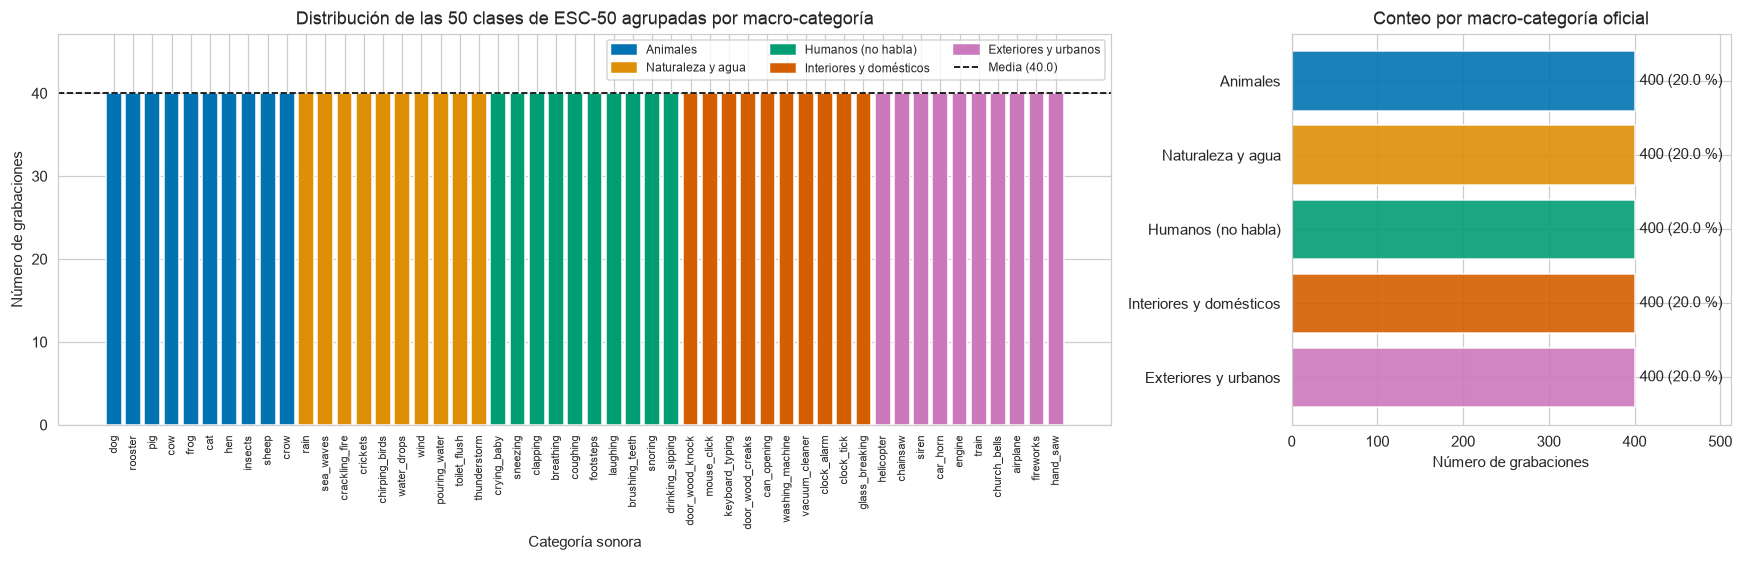

In [5]:
# Distribución de frecuencias por clase (50 clases), por macro-categoría (5 grupos) y por fold
class_counts = df_clean["category"].value_counts().reindex(CLASSES_BY_GROUP, fill_value=0)
group_counts = df_clean["macro_group"].value_counts().reindex(GROUP_ORDER, fill_value=0)

df_group_dist = pd.DataFrame({
    "clases_en_grupo": [df_clean.loc[df_clean["macro_group"] == g, "category"].nunique() for g in GROUP_ORDER],
    "grabaciones": group_counts.values,
    "porcentaje_%": (group_counts.values / len(df_clean) * 100).round(2),
}, index=GROUP_ORDER)
display(df_group_dist)

imbalance_ratio = class_counts.max() / max(1, class_counts.min())
print(
    f"Clases totales: {len(class_counts)} | Mínimo por clase: {class_counts.min()} | "
    f"Máximo por clase: {class_counts.max()} | Razón de desbalance: {imbalance_ratio:.3f}"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [2.4, 1.0]})

bar_colors = [GROUP_COLORS[CLASS_TO_MACRO_GROUP[c]] for c in CLASSES_BY_GROUP]
axes[0].bar(np.arange(len(CLASSES_BY_GROUP)), class_counts.values, color=bar_colors, width=0.82)
axes[0].axhline(class_counts.mean(), color="black", linestyle="--", lw=1.1, label=f"Media ({class_counts.mean():.1f})")
axes[0].set_xticks(np.arange(len(CLASSES_BY_GROUP)))
axes[0].set_xticklabels(CLASSES_BY_GROUP, rotation=90, fontsize=7.5)
axes[0].set(
    title="Distribución de las 50 clases de ESC-50 agrupadas por macro-categoría",
    xlabel="Categoría sonora",
    ylabel="Número de grabaciones",
    ylim=(0, class_counts.max() * 1.18),
)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER]
axes[0].legend(handles + [axes[0].lines[0]], GROUP_ORDER + [f"Media ({class_counts.mean():.1f})"],
               ncol=3, fontsize=8, loc="upper right")

axes[1].barh(GROUP_ORDER, group_counts.values, color=[GROUP_COLORS[g] for g in GROUP_ORDER], alpha=0.9)
axes[1].invert_yaxis()
for i, cnt in enumerate(group_counts.values):
    axes[1].text(cnt + max(group_counts.values) * 0.015, i, f"{cnt} ({cnt / len(df_clean) * 100:.1f} %)", va="center")
axes[1].set_xlim(0, group_counts.max() * 1.28)
axes[1].set(
    title="Conteo por macro-categoría oficial",
    xlabel="Número de grabaciones",
    ylabel="",
)

plt.tight_layout()
plt.show()

#### 1.2.3. Propiedades acústicas: duración, frecuencia de muestreo y energía RMS por macro-categoría
A diferencia de un corpus de texto con longitudes muy variables, las grabaciones de ESC-50 tienen una duración nominal fija de $5.0\,\text{s}$, pero difieren ampliamente en su **nivel de energía promedio (RMS en dBFS)**, **amplitud pico** y **fracción de silencio** (por ejemplo, sonidos impulsivos como `water_drops` o `door_wood_knock` frente a sonidos estacionarios continuos como `rain`, `wind` o `vacuum_cleaner`). Cuantificar estas propiedades orienta la necesidad de preservar variaciones de energía relativa y justifica usar normalización global basada en AudioSet en lugar de normalizar cada clip individualmente a amplitud máxima.

duration_s                 sr_orig                     \
                              mean  std  min  max     mean  std    min    max   
macro_group                                                                     
Animales                       5.0  0.0  5.0  5.0  44100.0  0.0  44100  44100   
Naturaleza y agua              5.0  0.0  5.0  5.0  44100.0  0.0  44100  44100   
Humanos (no habla)             5.0  0.0  5.0  5.0  44100.0  0.0  44100  44100   
Interiores y domésticos        5.0  0.0  5.0  5.0  44100.0  0.0  44100  44100   
Exteriores y urbanos           5.0  0.0  5.0  5.0  44100.0  0.0  44100  44100   

                         rms_db                        peak_amp                \
                           mean     std     min    max     mean    std    min   
macro_group                                                                     
Animales                -21.862   7.147 -48.977 -7.711    0.718  0.301  0.031   
Naturaleza y agua       -26.652   9.432 -49.249 -4.886    0.610  0.321  0.021   
Humanos (no habla)      -27.128   8.528 -49.285 -6.406    0.678  0.340  0.025   
Interiores y domésticos -27.309  10.081 -50.122 -3.174    0.645  0.334  0.064   
Exteriores y urbanos    -19.424   7.083 -41.692 -4.066    0.765  0.267  0.043   

                             silence_ratio                       
                         max          mean    std    min    max  
macro_group                                                      
Animales                 1.0         0.204  0.248  0.003  0.940  
Naturaleza y agua        1.0         0.126  0.204  0.001  0.935  
Humanos (no habla)       1.0         0.297  0.289  0.001  0.939  
Interiores y domésticos  1.0         0.356  0.318  0.000  0.970  
Exteriores y urbanos     1.0         0.079  0.164  0.001  0.871

/var/folders/37/6ftwz7y94y1g924dxgc8wwth0000gn/T/ipykernel_8686/919234056.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels([g.replace(" (", "\n(") for g in GROUP_ORDER], fontsize=9)
/var/folders/37/6ftwz7y94y1g924dxgc8wwth0000gn/T/ipykernel_8686/919234056.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels([g.replace(" (", "\n(") for g in GROUP_ORDER], fontsize=9)


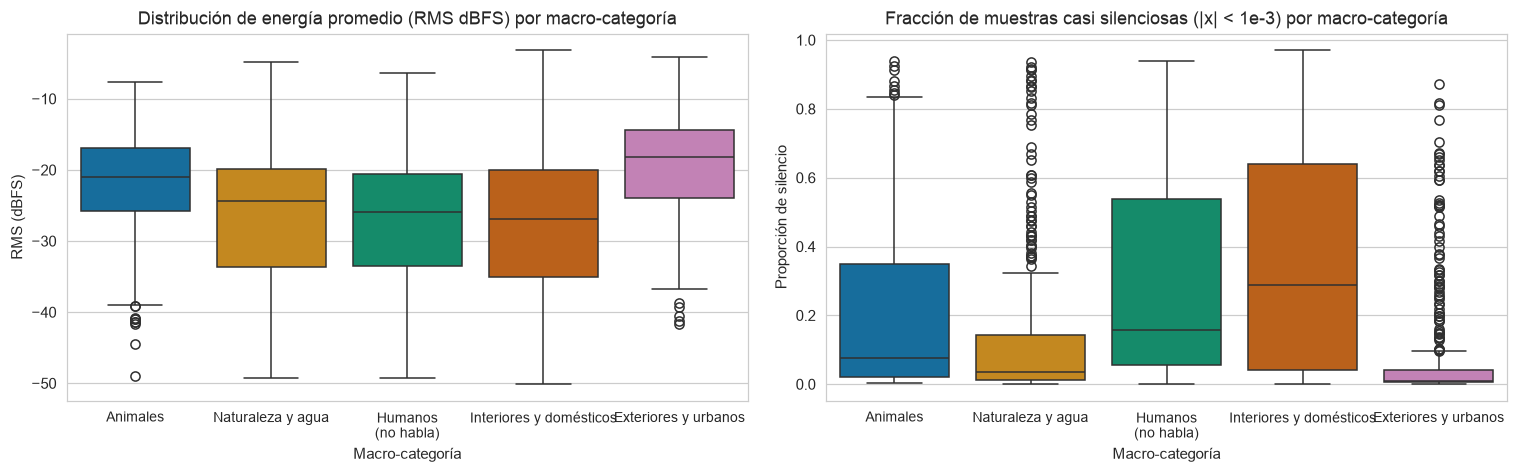

In [6]:
# Estadísticos acústicos por macro-categoría y diagramas de caja de energía RMS y proporción de silencio
acoustic_cols = ["duration_s", "sr_orig", "rms_db", "peak_amp", "silence_ratio"]
df_acoustic_summary = df_clean.groupby("macro_group")[acoustic_cols].agg(["mean", "std", "min", "max"]).reindex(GROUP_ORDER)
display(df_acoustic_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

sns.boxplot(
    data=df_clean, x="macro_group", y="rms_db", order=GROUP_ORDER,
    hue="macro_group", palette=GROUP_COLORS, legend=False, ax=axes[0],
)
axes[0].set_xticklabels([g.replace(" (", "\n(") for g in GROUP_ORDER], fontsize=9)
axes[0].set(
    title="Distribución de energía promedio (RMS dBFS) por macro-categoría",
    xlabel="Macro-categoría",
    ylabel="RMS (dBFS)",
)

sns.boxplot(
    data=df_clean, x="macro_group", y="silence_ratio", order=GROUP_ORDER,
    hue="macro_group", palette=GROUP_COLORS, legend=False, ax=axes[1],
)
axes[1].set_xticklabels([g.replace(" (", "\n(") for g in GROUP_ORDER], fontsize=9)
axes[1].set(
    title="Fracción de muestras casi silenciosas (|x| < 1e-3) por macro-categoría",
    xlabel="Macro-categoría",
    ylabel="Proporción de silencio",
)

plt.tight_layout()
plt.show()

#### 1.2.4. Inspección visual de formas de onda y espectrogramas log-Mel por macro-categoría
Para observar la estructura temporal y espectral que explotará el Audio Spectrogram Transformer [3], se muestra una grabación representativa de cada una de las $5$ macro-categorías (priorizando sonidos naturales y contrastantes: `dog`, `chirping_birds`, `footsteps`, `clock_tick`, `siren` u otros disponibles) comparando su forma de onda en el tiempo y su espectrograma log-Mel de $128$ bandas.

/Users/andresperez/Documents/workspace/TDL_Microproyectos/microproyecto_4/.venv/lib/python3.15/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (201) may be set too low.
  warnings.warn(


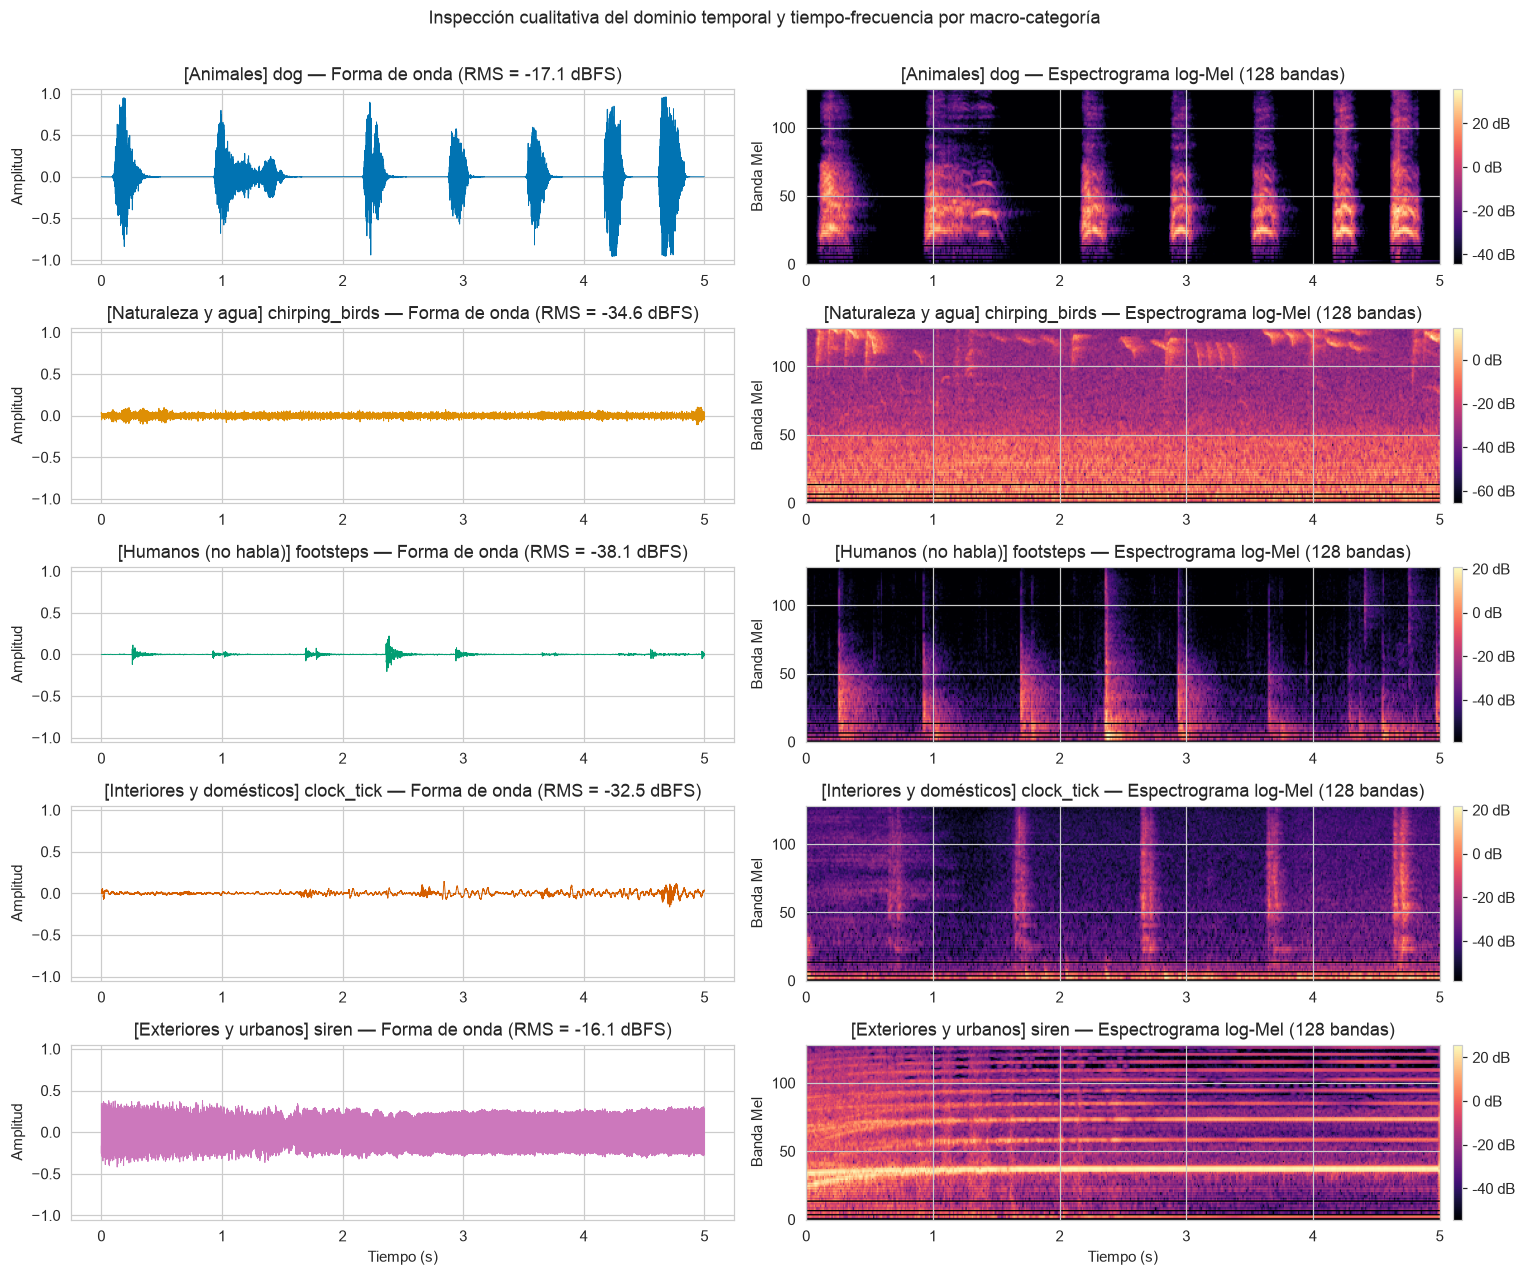

**Síntesis observada del EDA:** El corpus validado contiene **2,000 grabaciones** en **50 clases perfectamente balanceadas** (razón de desbalance = **1.00**, $40$ clips por clase y $400$ por cada una de las $5$ macro-categorías). Todas las grabaciones tienen duración entre **5.00 s y 5.00 s** a **44,100 Hz**. La energía promedio más alta corresponde a **Exteriores y urbanos** (-19.42 dBFS) y la más baja a **Interiores y domésticos** (-27.31 dBFS), mientras que la mayor fracción de intervalos silenciosos aparece en **Interiores y domésticos** (35.6 %).

In [7]:
# Visualización de forma de onda y espectrograma log-Mel (128 bandas) para 1 clip por macro-categoría
PREFERRED_EXAMPLES = {
    "Animales": "dog",
    "Naturaleza y agua": "chirping_birds",
    "Humanos (no habla)": "footsteps",
    "Interiores y domésticos": "clock_tick",
    "Exteriores y urbanos": "siren",
}

mel_viz_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000, n_fft=400, win_length=400, hop_length=160, n_mels=128
)
amp_to_db = torchaudio.transforms.AmplitudeToDB(top_db=80.0)

fig, axes = plt.subplots(len(GROUP_ORDER), 2, figsize=(14, 11.5))

for row_idx, grp in enumerate(GROUP_ORDER):
    sub_grp = df_clean[df_clean["macro_group"] == grp]
    pref_cls = PREFERRED_EXAMPLES[grp]
    sub_pref = sub_grp[sub_grp["category"] == pref_cls]
    sample_row = (sub_pref if len(sub_pref) > 0 else sub_grp).sample(1, random_state=RANDOM_STATE).iloc[0]

    wave = RAW_WAVEFORMS[int(sample_row["audio_idx"])]
    sr = int(sample_row["sr_orig"])
    t_axis = np.linspace(0.0, len(wave) / sr, num=len(wave))

    # Remuestreo rápido a 16 kHz solo para visualización homogénea en 0..8 kHz
    w_t = torch.from_numpy(wave).unsqueeze(0)
    if sr != 16000:
        w_t = torchaudio.functional.resample(w_t, orig_freq=sr, new_freq=16000)
    mel_db = amp_to_db(mel_viz_transform(w_t)).squeeze(0).numpy()

    axes[row_idx, 0].plot(t_axis, wave, color=GROUP_COLORS[grp], lw=0.6)
    axes[row_idx, 0].set_ylim(-1.05, 1.05)
    axes[row_idx, 0].set(
        title=f"[{grp}] {sample_row['category']} — Forma de onda (RMS = {sample_row['rms_db']:.1f} dBFS)",
        ylabel="Amplitud",
        xlabel="Tiempo (s)" if row_idx == len(GROUP_ORDER) - 1 else "",
    )

    im = axes[row_idx, 1].imshow(
        mel_db, origin="lower", aspect="auto", cmap="magma",
        extent=[0.0, len(wave) / sr, 0, 128],
    )
    axes[row_idx, 1].set(
        title=f"[{grp}] {sample_row['category']} — Espectrograma log-Mel (128 bandas)",
        ylabel="Banda Mel",
        xlabel="Tiempo (s)" if row_idx == len(GROUP_ORDER) - 1 else "",
    )
    fig.colorbar(im, ax=axes[row_idx, 1], fraction=0.025, pad=0.02, format="%.0f dB")

fig.suptitle("Inspección cualitativa del dominio temporal y tiempo-frecuencia por macro-categoría", y=1.005)
plt.tight_layout()
plt.show()

# Resumen numérico dinámico del EDA
dur_min, dur_max = df_clean["duration_s"].min(), df_clean["duration_s"].max()
rms_by_grp = df_clean.groupby("macro_group")["rms_db"].mean().round(2)
sil_by_grp = df_clean.groupby("macro_group")["silence_ratio"].mean().mul(100).round(1)
display(Markdown(
    f"**Síntesis observada del EDA:** El corpus validado contiene **{len(df_clean):,} grabaciones** "
    f"en **{NUM_LABELS} clases perfectamente balanceadas** (razón de desbalance = **{imbalance_ratio:.2f}**, "
    f"$40$ clips por clase y $400$ por cada una de las $5$ macro-categorías). Todas las grabaciones tienen "
    f"duración entre **{dur_min:.2f} s y {dur_max:.2f} s** a **{df_clean['sr_orig'].mode().iloc[0]:,} Hz**. "
    f"La energía promedio más alta corresponde a **{rms_by_grp.idxmax()}** ({rms_by_grp.max():.2f} dBFS) "
    f"y la más baja a **{rms_by_grp.idxmin()}** ({rms_by_grp.min():.2f} dBFS), mientras que la mayor fracción "
    f"de intervalos silenciosos aparece en **{sil_by_grp.idxmax()}** ({sil_by_grp.max():.1f} %)."
))

#### 1.2.5. Hallazgos del EDA e implicaciones para el preprocesamiento y modelado
A partir de la inspección cuantitativa de las **$2\,000$ grabaciones validadas** se obtienen cuatro hallazgos clave que guían el preprocesamiento y el modelado:
1. **Integridad total y homogeneidad temporal:** el conjunto no presenta valores nulos, audios vacíos ni clips mudos (`0` casos), ni señales duplicadas (`0` coincidencias `audio_md5`). Todas las grabaciones tienen exactamente **$5.00\,\text{s}$ de duración** (`std = 0.0`) y una frecuencia de muestreo original de **$44\,100\,\text{Hz}$**.
2. **Balance perfecto de clases:** las $50$ categorías contienen exactamente **$40$ grabaciones cada una** ($400$ clips y $20.0\,\%$ por cada una de las $5$ macro-categorías; **razón de desbalance = $1.000$**). Por ello no se requiere ponderación por clase ni sobremuestreo en `CrossEntropyLoss`, aunque el *F1-score* macro y su desviación estándar entre las $50$ clases siguen siendo esenciales para identificar asimetrías de dificultad acústica.
3. **Heterogeneidad marcada en energía RMS y fracción de silencio:**
   - **Exteriores y urbanos** registra la mayor energía promedio (**$-19.42 \pm 7.08\,\text{dBFS}$**, amplitud pico media $0.765$) y la menor proporción de silencio (**$7.9 \pm 16.4\,\%$**), reflejando fuentes continuas e intensas como motores, sirenas o motosierras.
   - **Animales** ($-21.86 \pm 7.15\,\text{dBFS}$, $20.4\,\%$ de silencio) y **Naturaleza y agua** ($-26.65 \pm 9.43\,\text{dBFS}$, $12.6\,\%$ de silencio) combinan vocalizaciones localizadas con texturas fluidas de banda ancha.
   - **Humanos (no habla)** ($-27.13 \pm 8.53\,\text{dBFS}$, $29.7\,\%$ de silencio) e **Interiores y domésticos** (**$-27.31 \pm 10.08\,\text{dBFS}$**, la menor energía media y la mayor proporción de silencio con **$35.6 \pm 31.8\,\%$**, alcanzando hasta $97.0\,\%$ en clips impulsivos) alternan eventos breves con pausas prolongadas.
4. **Implicaciones para el preprocesamiento y AST:** dado que `MIT/ast-finetuned-audioset-10-10-0.4593` fue preentrenado a **$16\,000\,\text{Hz}$** con **espectrogramas log-Mel de $128$ bandas** [3], [5], resulta necesario remuestrear uniformemente desde $44\,100\,\text{Hz}$ a $16\,000\,\text{Hz}$ y conservar la **normalización global de AudioSet** en lugar de normalizar cada clip individualmente a su pico, preservando así las diferencias reales de intensidad entre sonidos tenues y enérgicos. La autoatención 2D de AST permite modelar simultáneamente eventos impulsivos breves y texturas estacionarias.

### 1.3. Partición en Conjuntos de Entrenamiento, Validación y Prueba
El cargador `load_dataset("confit/esc50-demo", "fold1")` entrega dos particiones oficiales:
- **`Test` (`val_dataset`, `split="test"`):** corresponde al **Fold 1 oficial ($400$ grabaciones, $20.0\,\%$ del corpus, $8$ por clase y $80$ por macro-categoría)**, que se mantiene estrictamente aislado como conjunto de prueba independiente para evaluar la generalización una **única vez** en la sección 3.2.
- **`fold1_train` (`dataset`, `split="train"`):** reúne los **Folds 2, 3, 4 y 5 ($1\,600$ grabaciones, $32$ por clase)**. Como `confit/esc50-demo` solo expone las columnas `['audio', 'sound', 'label']` sin los metadatos `fold` ni `src_file` originales dentro de `fold1_train`, se aplicó la estrategia de respaldo diseñada: una **partición estratificada `75 % / 25 %`** (`RANDOM_STATE = 42`) que separa **`Train` ($1\,200$ clips, $60.0\,\%$, $24$/clase, $240$/macro-categoría)** y **`Val` ($400$ clips, $20.0\,\%$, $8$/clase, $80$/macro-categoría)**, verificando $0$ clips compartidos entre las tres particiones.

De este modo:
- **`Train` ($1\,200$ clips)** ajusta los pesos de AST, los parámetros del modelo de referencia MFCC y las verificaciones estadísticas de espectrogramas.
- **`Val` ($400$ clips)** guía la comparación entre configuraciones experimentales y la selección del mejor punto de control (*checkpoint*).
- **`Test` ($400$ clips, Fold 1 oficial)** se utiliza una **única vez** en la sección 3.2 y constituye la estimación rigurosa de generalización sin fuga de grabaciones fuente.

In [8]:
# Partición en Train (Folds 2-4), Val (Fold 5) y Test (Fold 1) con verificación anti-fuga
df_train_pool = df_clean[df_clean["source_split"] == "fold1_train"].copy()
df_test = df_clean[df_clean["source_split"] == "fold1_test"].copy().reset_index(drop=True)

available_train_folds = sorted(df_train_pool["fold"].unique().tolist())
if 5 in available_train_folds and len(available_train_folds) >= 2:
    df_train = df_train_pool[df_train_pool["fold"] != 5].copy().reset_index(drop=True)
    df_val = df_train_pool[df_train_pool["fold"] == 5].copy().reset_index(drop=True)
    SPLIT_STRATEGY = "Por folds oficiales de ESC-50 (Train = Folds 2-4, Val = Fold 5, Test = Fold 1)"
else:
    df_train, df_val = train_test_split(
        df_train_pool, test_size=0.25, stratify=df_train_pool["label"], random_state=RANDOM_STATE
    )
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    SPLIT_STRATEGY = "Estratificada 75%/25% sobre fold1_train (respaldo sin columna fold), Test = Fold 1"

splits = {"Train": df_train, "Val": df_val, "Test": df_test}

# Verificaciones estrictas de disyunción entre particiones
idx_sets = {name: set(df["audio_idx"].tolist()) for name, df in splits.items()}
assert idx_sets["Train"].isdisjoint(idx_sets["Val"])
assert idx_sets["Train"].isdisjoint(idx_sets["Test"])
assert idx_sets["Val"].isdisjoint(idx_sets["Test"])

src_sets = {name: set(df["src_file"].tolist()) for name, df in splits.items()}
src_overlap_tv = len(src_sets["Train"] & src_sets["Val"])
src_overlap_tt = len(src_sets["Train"] & src_sets["Test"])
src_overlap_vt = len(src_sets["Val"] & src_sets["Test"])

split_group_counts = pd.DataFrame({
    name: df["macro_group"].value_counts().reindex(GROUP_ORDER, fill_value=0)
    for name, df in splits.items()
})
split_group_counts["Total"] = split_group_counts.sum(axis=1)

per_class_range = pd.DataFrame({
    name: {
        "Total clips": len(df),
        "% corpus": round(len(df) / len(df_clean) * 100, 1),
        "Clases presentes": df["category"].nunique(),
        "Mín clips/clase": int(df["category"].value_counts().min()),
        "Máx clips/clase": int(df["category"].value_counts().max()),
        "Folds": sorted(df["fold"].unique().tolist()),
    }
    for name, df in splits.items()
}).T

print(f"Estrategia de partición: {SPLIT_STRATEGY}")
print(f"Solapamiento de src_file -> Train∩Val: {src_overlap_tv} | Train∩Test: {src_overlap_tt} | Val∩Test: {src_overlap_vt}")
display(per_class_range)
display(split_group_counts)

Estrategia de partición: Estratificada 75%/25% sobre fold1_train (respaldo sin columna fold), Test = Fold 1
Solapamiento de src_file -> Train∩Val: 0 | Train∩Test: 0 | Val∩Test: 0


,Total clips,% corpus,Clases presentes,Mín clips/clase,Máx clips/clase,Folds
Train,1200,60.0,50,24,24,[-1]
Val,400,20.0,50,8,8,[-1]
Test,400,20.0,50,8,8,[1]


,Train,Val,Test,Total
macro_group,,,,
Animales,240,80,80,400
Naturaleza y agua,240,80,80,400
Humanos (no habla),240,80,80,400
Interiores y domésticos,240,80,80,400
Exteriores y urbanos,240,80,80,400


### 1.4. Pipeline de Preprocesamiento de Audio: Remuestreo, Espectrogramas Log-Mel y Normalización
El modelo preentrenado `MIT/ast-finetuned-audioset-10-10-0.4593` recibe un tensor de espectrogramas log-Mel `input_values` de forma `(batch_size, max_length, num_mel_bins)` [3], [8]. La siguiente tabla resume cada etapa del *pipeline* diseñado y su justificación técnica:

| # | Etapa | Configuración implementada | Justificación |
| :-: | :--- | :--- | :--- |
| **1** | **Conversión mono y formato flotante** | Promedio de canales a `float32` | Garantiza señales unidimensionales homogéneas sin importar si el archivo fuente es mono o estéreo. |
| **2** | **Remuestreo temporal** | $f_s^{\text{orig}} \rightarrow 16\,000\,\text{Hz}$ (`torchaudio.transforms.Resample`) | Coincide exactamente con la frecuencia de muestreo usada en AudioSet y esperada por `ASTFeatureExtractor` ($f_{\text{Nyquist}} = 8\,000\,\text{Hz}$). |
| **3** | **Espectrograma log-Mel (Kaldi)** | $128$ filtros Mel, ventana de $25\,\text{ms}$, desplazamiento (*hop*) de $10\,\text{ms}$ | Genera la representación visual tiempo-frecuencia de alta resolución ($100\,\text{cuadros/s} \times 128\,\text{frecuencias}$) idéntica a la del preentrenamiento [3]. |
| **4** | **Consistencia dimensional** | `MAX_LENGTH = 512` cuadros (vs. $1\,024$ por defecto en AudioSet) | Un clip de $5.0\,\text{s}$ genera $\approx 498$ cuadros útiles. Truncar o rellenar a $512$ conserva el **$100\,\%$ de la señal real**, evita más de $50\,\%$ de relleno vacío y reduce $\sim 4\times$ el cómputo de autoatención $\mathcal{O}(N^2)$. |
| **5** | **Normalización del espectrograma** | $\tilde{X} = \dfrac{X - \mu}{2\sigma}$ con $\mu = -4.2677393$ y $\sigma = 4.5689974$ (AudioSet) | Replica exactamente la estandarización oficial de AST [3], llevando los valores log-Mel a media cercana a $0$ y desviación estándar $\approx 0.5$ sin alterar el balance relativo de energía entre eventos. |
| **6** | **Aumento en entrenamiento (*SpecAugment*)** | `FrequencyMasking(24)` + `TimeMasking(64)` solo sobre `Train` [7] | Regulariza el espectrograma ocultando bloques aleatorios en tiempo y frecuencia para reducir el sobreajuste en $1\,200$ clips. |

#### 1.4.1. Carga de `ASTFeatureExtractor` y verificación del efecto de remuestreo y normalización
Se instancia `ASTFeatureExtractor` desde el *checkpoint* `MIT/ast-finetuned-audioset-10-10-0.4593` fijando `max_length = 512` (`sampling_rate = 16 000 Hz`, `num_mel_bins = 128`, `mean = -4.2677393`, `std = 4.5689974`, `do_normalize = True`) y se verifica paso a paso sobre un clip de `Train` (`water_drops`, `fold1_train_0447.wav`): la onda pasa de `(220 500,)` a $44.1\,\text{kHz}$ a `(80 000,)` a $16\,\text{kHz}$, y el espectrograma `(512, 128)` se transforma de una distribución cruda (`media = -11.773`, `DE = 4.748`, rango `[-15.94, 6.57]`) a una escala normalizada (`media = -0.821`, `DE = 0.520`, rango `[-1.28, 1.19]`) con apenas un borde mínimo de relleno frente a `max_length = 1024`.

ASTFeatureExtractor (MIT/ast-finetuned-audioset-10-10-0.4593):
  sampling_rate = 16000 Hz | num_mel_bins = 128 | max_length = 512
  mean (AudioSet) = -4.2677393 | std (AudioSet) = 4.5689974 | do_normalize = True

Clip de ejemplo: 'water_drops' (fold1_train_0447.wav)
  Onda original (44100 Hz): (220500,) -> Remuestreada (16000 Hz): (80000,)
  Espectrograma sin normalizar: shape=(512, 128), media=-11.773, DE=4.748, rango=[-15.94, 6.57]
  Espectrograma normalizado:    shape=(512, 128), media=-0.821, DE=0.520, rango=[-1.28, 1.19]


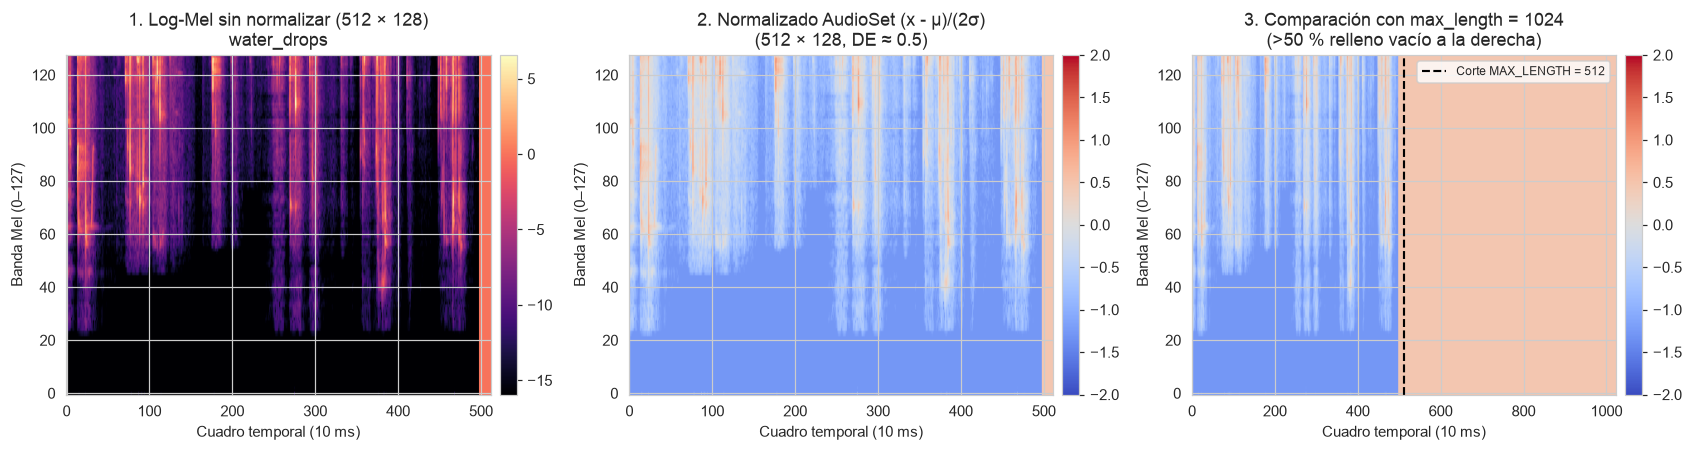

In [9]:
# Carga de ASTFeatureExtractor, función de remuestreo a 16 kHz y comparación visual de normalización y relleno
MODEL_CHECKPOINT = "MIT/ast-finetuned-audioset-10-10-0.4593"
TARGET_SR = 16000
MAX_LENGTH = 512
NUM_MEL_BINS = 128

feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_CHECKPOINT, max_length=MAX_LENGTH)
raw_extractor = ASTFeatureExtractor.from_pretrained(MODEL_CHECKPOINT, max_length=MAX_LENGTH, do_normalize=False)
extractor_1024 = ASTFeatureExtractor.from_pretrained(MODEL_CHECKPOINT, max_length=1024)

print(
    f"ASTFeatureExtractor ({MODEL_CHECKPOINT}):\n"
    f"  sampling_rate = {feature_extractor.sampling_rate} Hz | num_mel_bins = {feature_extractor.num_mel_bins} | "
    f"max_length = {feature_extractor.max_length}\n"
    f"  mean (AudioSet) = {feature_extractor.mean:.7f} | std (AudioSet) = {feature_extractor.std:.7f} | "
    f"do_normalize = {feature_extractor.do_normalize}"
)

_resamplers = {}


def resample_to_16k(waveform: np.ndarray, orig_sr: int, target_sr: int = TARGET_SR) -> np.ndarray:
    """Remuestrea una señal mono float32 a target_sr usando torchaudio con caché de filtros."""
    if orig_sr == target_sr:
        return waveform.astype(np.float32, copy=False)
    if orig_sr not in _resamplers:
        _resamplers[orig_sr] = torchaudio.transforms.Resample(orig_freq=orig_sr, new_freq=target_sr)
    with torch.no_grad():
        res = _resamplers[orig_sr](torch.from_numpy(waveform).unsqueeze(0)).squeeze(0)
    return res.numpy().astype(np.float32)


# Verificación sobre un clip de Train (priorizando un sonido natural si existe)
nat_candidates = df_train[df_train["macro_group"] == "Naturaleza y agua"]
sample_clip_row = (nat_candidates if len(nat_candidates) > 0 else df_train).iloc[0]
raw_wave = RAW_WAVEFORMS[int(sample_clip_row["audio_idx"])]
wave_16k = resample_to_16k(raw_wave, int(sample_clip_row["sr_orig"]))

spec_unnorm = raw_extractor(wave_16k, sampling_rate=TARGET_SR, return_tensors="np")["input_values"][0]
spec_norm = feature_extractor(wave_16k, sampling_rate=TARGET_SR, return_tensors="np")["input_values"][0]
spec_1024 = extractor_1024(wave_16k, sampling_rate=TARGET_SR, return_tensors="np")["input_values"][0]

print(
    f"\nClip de ejemplo: '{sample_clip_row['category']}' ({sample_clip_row['filename']})\n"
    f"  Onda original ({sample_clip_row['sr_orig']} Hz): {raw_wave.shape} -> "
    f"Remuestreada ({TARGET_SR} Hz): {wave_16k.shape}\n"
    f"  Espectrograma sin normalizar: shape={spec_unnorm.shape}, media={spec_unnorm.mean():.3f}, "
    f"DE={spec_unnorm.std():.3f}, rango=[{spec_unnorm.min():.2f}, {spec_unnorm.max():.2f}]\n"
    f"  Espectrograma normalizado:    shape={spec_norm.shape}, media={spec_norm.mean():.3f}, "
    f"DE={spec_norm.std():.3f}, rango=[{spec_norm.min():.2f}, {spec_norm.max():.2f}]"
)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))

im0 = axes[0].imshow(spec_unnorm.T, origin="lower", aspect="auto", cmap="magma")
axes[0].set(title=f"1. Log-Mel sin normalizar (512 × 128)\n{sample_clip_row['category']}",
            xlabel="Cuadro temporal (10 ms)", ylabel="Banda Mel (0–127)")
fig.colorbar(im0, ax=axes[0], fraction=0.04, pad=0.02)

im1 = axes[1].imshow(spec_norm.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-2.0, vmax=2.0)
axes[1].set(title="2. Normalizado AudioSet (x - μ)/(2σ)\n(512 × 128, DE ≈ 0.5)",
            xlabel="Cuadro temporal (10 ms)", ylabel="Banda Mel (0–127)")
fig.colorbar(im1, ax=axes[1], fraction=0.04, pad=0.02)

im2 = axes[2].imshow(spec_1024.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-2.0, vmax=2.0)
axes[2].axvline(512, color="black", linestyle="--", lw=1.4, label="Corte MAX_LENGTH = 512")
axes[2].set(title="3. Comparación con max_length = 1024\n(>50 % relleno vacío a la derecha)",
            xlabel="Cuadro temporal (10 ms)", ylabel="Banda Mel (0–127)")
axes[2].legend(loc="upper right", fontsize=8)
fig.colorbar(im2, ax=axes[2], fraction=0.04, pad=0.02)

plt.tight_layout()
plt.show()

#### 1.4.2. Verificación de estadísticas de normalización en `Train` y análisis de longitud temporal
Con el fin de validar empíricamente sin fuga de información que `MAX_LENGTH = 512` no trunca las grabaciones reales y que las estadísticas de AudioSet normalizan adecuadamente ESC-50, se evalúan sobre **`Train`** las longitudes exactas en cuadros de Kaldi y la distribución log-Mel antes y después de aplicar $\frac{X - \mu_{\text{AudioSet}}}{2\sigma_{\text{AudioSet}}}$:
- **Longitud exacta en `Train`:** el $100\,\%$ de los clips genera exactamente **$498$ cuadros** (`min = mediana = max = 498`). Con `MAX_LENGTH = 256` o `384` se truncaría el $100.0\,\%$ de las grabaciones (conservando solo el $51.41\,\%$ y el $77.11\,\%$ de los cuadros reales). En cambio, **`MAX_LENGTH = 512` ($5.12\,\text{s}$) conserva el $100.00\,\%$ de la señal real ($0.0\,\%$ truncados) con apenas $2.73\,\%$ de relleno vacío**, frente al **$51.37\,\%$ de relleno vacío** que introduciría `1024`.
- **Estadísticas de normalización en `Train`:** los espectrogramas log-Mel sin normalizar presentan `media = -6.8208` y `DE = 5.3665`; tras aplicar la estandarización de AudioSet ($\mu = -4.2677$, $\sigma = 4.5690$), quedan centrados en **`media = -0.2794`** y **`DE = 0.5873`**, muy cerca del régimen esperado por AST ($\approx 0$ y $\approx 0.5$).

In [10]:
# Análisis sin fuga de longitudes reales en cuadros Kaldi y estadísticas de normalización sobre Train
def compute_kaldi_num_frames(n_samples: int, sr: int = TARGET_SR, frame_len_ms: float = 25.0, frame_shift_ms: float = 10.0) -> int:
    """Número exacto de cuadros que produce torchaudio.compliance.kaldi.fbank (snip_edges=True)."""
    win_len = int(sr * frame_len_ms / 1000.0)
    hop_len = int(sr * frame_shift_ms / 1000.0)
    if n_samples < win_len:
        return 0
    return 1 + (n_samples - win_len) // hop_len


train_waves_16k = [
    resample_to_16k(RAW_WAVEFORMS[int(idx)], int(sr))
    for idx, sr in zip(df_train["audio_idx"], df_train["sr_orig"])
]
train_frame_lengths = np.array([compute_kaldi_num_frames(len(w), TARGET_SR) for w in train_waves_16k])

MAX_LEN_CANDIDATES = [256, 384, 512, 1024]
len_rows = []
for cand in MAX_LEN_CANDIDATES:
    truncated_pct = float(np.mean(train_frame_lengths > cand) * 100.0)
    kept_pct = float(np.minimum(train_frame_lengths, cand).sum() / max(1, train_frame_lengths.sum()) * 100.0)
    pad_pct = float(np.maximum(0, cand - train_frame_lengths).sum() / (len(train_frame_lengths) * cand) * 100.0)
    len_rows.append({
        "MAX_LENGTH (cuadros)": cand,
        "Duración cubierta (s)": round(cand * 0.010, 2),
        "Clips truncados (%)": round(truncated_pct, 2),
        "Cuadros reales conservados (%)": round(kept_pct, 2),
        "Relleno vacío promedio (%)": round(pad_pct, 2),
    })
df_len_candidates = pd.DataFrame(len_rows).set_index("MAX_LENGTH (cuadros)")
print(
    f"Longitud en cuadros de Train: min={train_frame_lengths.min()}, mediana={np.median(train_frame_lengths):.0f}, "
    f"max={train_frame_lengths.max()}"
)
display(df_len_candidates)

# Estadísticas log-Mel empíricas de Train (solo parte activa antes del padding) vs AudioSet
raw_mean_sum, raw_sq_sum, total_bins = 0.0, 0.0, 0
norm_mean_sum, norm_sq_sum = 0.0, 0.0

for start in range(0, len(train_waves_16k), 64):
    batch_w = train_waves_16k[start : start + 64]
    batch_lens = train_frame_lengths[start : start + 64]
    raw_batch = raw_extractor(batch_w, sampling_rate=TARGET_SR, return_tensors="np")["input_values"]
    norm_batch = feature_extractor(batch_w, sampling_rate=TARGET_SR, return_tensors="np")["input_values"]
    for i, n_fr in enumerate(batch_lens):
        r_slice = raw_batch[i, :n_fr, :].astype(np.float64)
        n_slice = norm_batch[i, :n_fr, :].astype(np.float64)
        raw_mean_sum += r_slice.sum()
        raw_sq_sum += np.square(r_slice).sum()
        norm_mean_sum += n_slice.sum()
        norm_sq_sum += np.square(n_slice).sum()
        total_bins += r_slice.size

esc_train_mean = raw_mean_sum / total_bins
esc_train_std = np.sqrt(raw_sq_sum / total_bins - esc_train_mean ** 2)
norm_train_mean = norm_mean_sum / total_bins
norm_train_std = np.sqrt(norm_sq_sum / total_bins - norm_train_mean ** 2)

df_norm_stats = pd.DataFrame([
    {"Conjunto / Referencia": "Log-Mel ESC-50 Train (sin normalizar)", "Media": round(esc_train_mean, 4), "Desv. estándar": round(esc_train_std, 4)},
    {"Conjunto / Referencia": "Estadísticas AudioSet (preentrenamiento AST)", "Media": round(float(feature_extractor.mean), 4), "Desv. estándar": round(float(feature_extractor.std), 4)},
    {"Conjunto / Referencia": "ESC-50 Train normalizado con (X - μ_AudioSet)/(2σ_AudioSet)", "Media": round(norm_train_mean, 4), "Desv. estándar": round(norm_train_std, 4)},
]).set_index("Conjunto / Referencia")
display(df_norm_stats)

Longitud en cuadros de Train: min=498, mediana=498, max=498


,Duración cubierta (s),Clips truncados (%),Cuadros reales conservados (%),Relleno vacío promedio (%)
MAX_LENGTH (cuadros),,,,
256,2.56,100.0,51.41,0.00
384,3.84,100.0,77.11,0.00
512,5.12,0.0,100.00,2.73
1024,10.24,0.0,100.00,51.37


,Media,Desv. estándar
Conjunto / Referencia,,
Log-Mel ESC-50 Train (sin normalizar),-6.8208,5.3665
Estadísticas AudioSet (preentrenamiento AST),-4.2677,4.5690
ESC-50 Train normalizado con (X - μ_AudioSet)/(2σ_AudioSet),-0.2794,0.5873


#### 1.4.3. Precomputación en caché de espectrogramas, *SpecAugment*, `Dataset` y `DataLoader`
Para evitar recalcular los filtros log-Mel en cada época de entrenamiento y reducir la carga sobre la CPU durante el *fine-tuning* en GPU o Apple Silicon MPS, se precomputan una sola vez las señales remuestreadas a $16\,\text{kHz}$ (`WAVE_16K_CACHE`) y los espectrogramas normalizados de forma `(N, 512, 128)` almacenados en `float16` en memoria CPU (`SPEC_CACHE`). En la ejecución, la caché completa de los $2\,000$ clips se construyó en **$3.5\,\text{s}$** ocupando exactamente **$250.0\,\text{MB}$** (`Train: 1 200`, `Val: 400`, `Test: 400`), generando **$150$ lotes de `Train`** (`BATCH_SIZE = 8`) y **$25$ lotes tanto en `Val` como en `Test`** (`BATCH_SIZE = 16`), con tensores verificados de forma `(8, 512, 128)` (`float32`) y etiquetas `(8,)` (`int64`).

Además, se implementa la clase `ESCSpectrogramDataset(Dataset)` con soporte opcional para ***SpecAugment*** [7] aplicado **exclusivamente en entrenamiento** (`FrequencyMasking(24)` y `TimeMasking(64)`). Como `ASTFeatureExtractor` produce tensores con ejes `(tiempo, frecuencia)` mientras `torchaudio.transforms` espera `(..., frecuencia, tiempo)`, el método `__getitem__` transpone temporalmente los ejes antes y después del enmascaramiento.

Caché de espectrogramas lista en 3.5s | Memoria total: 250.0 MB | Train: (1200, 512, 128) | Val: (400, 512, 128) | Test: (400, 512, 128)
Train: 1200 clips, 150 lotes | Val: 400 clips, 25 lotes | Test: 400 clips, 25 lotes
Lote de verificación -> input_values: (8, 512, 128) torch.float32 | labels: (8,) torch.int64
Primeras etiquetas del lote: ['pig', 'can_opening', 'snoring', 'mouse_click', 'church_bells', 'door_wood_knock']


/var/folders/37/6ftwz7y94y1g924dxgc8wwth0000gn/T/ipykernel_8686/2178912953.py:65: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  self.labels = torch.as_tensor(labels, dtype=torch.long)


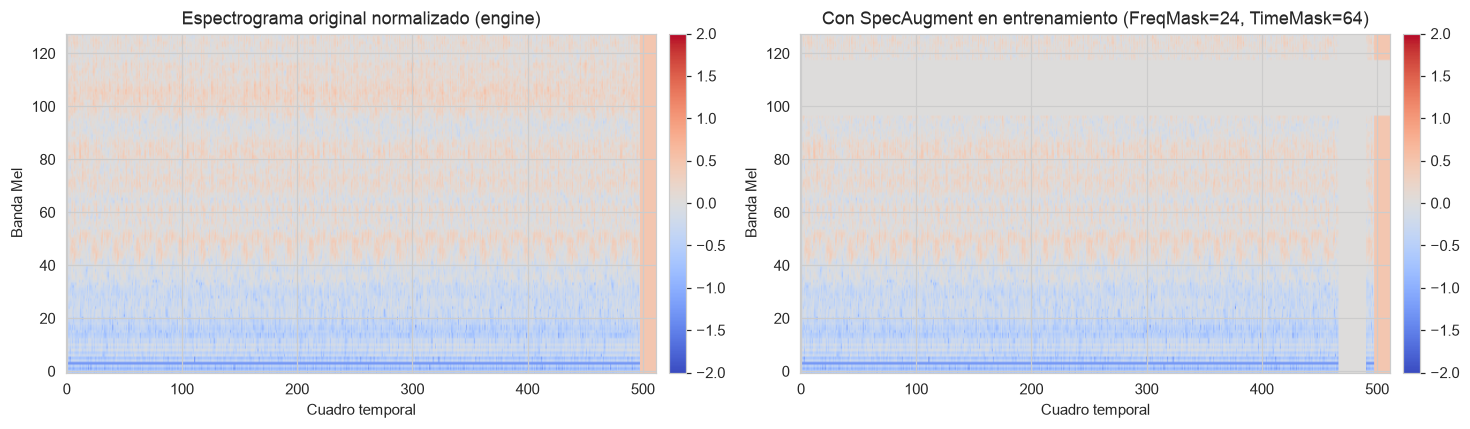

In [11]:
# Precomputación en caché de ondas 16 kHz y espectrogramas normalizados (512 x 128), Dataset y DataLoader
BATCH_SIZE = 8
NUM_WORKERS = 0  # En Jupyter sobre macOS/Windows, num_workers > 0 puede fallar con clases definidas en el notebook


def precompute_split_arrays(df_split: pd.DataFrame, extract_batch_size: int = 64) -> tuple:
    """Remuestrea a 16 kHz y extrae espectrogramas AST (N, MAX_LENGTH, 128) en float16."""
    waves_16k = [
        resample_to_16k(RAW_WAVEFORMS[int(idx)], int(sr))
        for idx, sr in zip(df_split["audio_idx"], df_split["sr_orig"])
    ]
    spec_chunks = []
    for start in range(0, len(waves_16k), extract_batch_size):
        batch_w = waves_16k[start : start + extract_batch_size]
        enc = feature_extractor(batch_w, sampling_rate=TARGET_SR, return_tensors="pt")
        spec_chunks.append(enc["input_values"].to(torch.float16))
    specs = torch.cat(spec_chunks, dim=0)
    return waves_16k, specs


t0_cache = time.time()
WAVE_16K_CACHE = {}
SPEC_CACHE = {}

for split_name, df_sp in splits.items():
    if split_name == "Train" and "train_waves_16k" in globals():
        waves_16k = train_waves_16k
        spec_chunks = [
            feature_extractor(waves_16k[i : i + 64], sampling_rate=TARGET_SR, return_tensors="pt")["input_values"].to(torch.float16)
            for i in range(0, len(waves_16k), 64)
        ]
        specs = torch.cat(spec_chunks, dim=0)
    else:
        waves_16k, specs = precompute_split_arrays(df_sp)
    WAVE_16K_CACHE[split_name] = waves_16k
    SPEC_CACHE[split_name] = specs

del train_waves_16k
gc.collect()

total_ram_mb = sum(t.numel() * t.element_size() for t in SPEC_CACHE.values()) / (1024 ** 2)
print(
    f"Caché de espectrogramas lista en {time.time() - t0_cache:.1f}s | Memoria total: {total_ram_mb:.1f} MB | "
    + " | ".join(f"{k}: {tuple(v.shape)}" for k, v in SPEC_CACHE.items())
)


class ESCSpectrogramDataset(Dataset):
    """Dataset de espectrogramas log-Mel (512, 128) con SpecAugment opcional para entrenamiento."""

    def __init__(
        self,
        specs: torch.Tensor,
        labels: np.ndarray,
        indices: np.ndarray = None,
        spec_augment: bool = False,
        freq_mask_param: int = 24,
        time_mask_param: int = 64,
    ):
        if indices is not None:
            self.specs = specs[indices]
            self.labels = torch.as_tensor(labels[indices], dtype=torch.long)
        else:
            self.specs = specs
            self.labels = torch.as_tensor(labels, dtype=torch.long)
        self.spec_augment = spec_augment
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=freq_mask_param) if spec_augment else None
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=time_mask_param) if spec_augment else None

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> dict:
        x = self.specs[idx].float()  # (time=512, freq=128)
        if self.spec_augment:
            # FrequencyMasking/TimeMasking esperan forma (..., freq, time)
            x_ft = x.transpose(0, 1).unsqueeze(0)
            x_ft = self.freq_mask(x_ft)
            x_ft = self.time_mask(x_ft)
            x = x_ft.squeeze(0).transpose(0, 1)
        return {"input_values": x, "labels": self.labels[idx]}


def get_loaders(
    batch_size: int = BATCH_SIZE,
    spec_augment: bool = False,
    train_indices: np.ndarray = None,
    seed: int = RANDOM_STATE,
) -> dict:
    """Construye los DataLoader de Train, Val y Test sobre SPEC_CACHE."""
    datasets_map = {
        "Train": ESCSpectrogramDataset(
            SPEC_CACHE["Train"], df_train["label"].to_numpy(), indices=train_indices, spec_augment=spec_augment
        ),
        "Val": ESCSpectrogramDataset(SPEC_CACHE["Val"], df_val["label"].to_numpy(), spec_augment=False),
        "Test": ESCSpectrogramDataset(SPEC_CACHE["Test"], df_test["label"].to_numpy(), spec_augment=False),
    }
    return {
        name: DataLoader(
            ds,
            batch_size=batch_size if name == "Train" else 2 * batch_size,
            shuffle=(name == "Train"),
            num_workers=NUM_WORKERS,
            generator=torch.Generator().manual_seed(seed) if name == "Train" else None,
        )
        for name, ds in datasets_map.items()
    }


loaders = get_loaders(batch_size=BATCH_SIZE, spec_augment=False, seed=RANDOM_STATE)
print(" | ".join(f"{k}: {len(ldr.dataset)} clips, {len(ldr)} lotes" for k, ldr in loaders.items()))

batch = next(iter(loaders["Train"]))
print("Lote de verificación -> " + " | ".join(f"{k}: {tuple(v.shape)} {v.dtype}" for k, v in batch.items()))
print(f"Primeras etiquetas del lote: {[ID2LABEL[int(i)] for i in batch['labels'][:6].tolist()]}")

# Visualización del efecto de SpecAugment sobre el primer clip de Train
aug_ds_preview = ESCSpectrogramDataset(SPEC_CACHE["Train"], df_train["label"].to_numpy(), spec_augment=True)
set_seed(RANDOM_STATE)
spec_clean_ex = SPEC_CACHE["Train"][0].float().numpy()
spec_aug_ex = aug_ds_preview[0]["input_values"].numpy()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.0))
im0 = axes[0].imshow(spec_clean_ex.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-2.0, vmax=2.0)
axes[0].set(title=f"Espectrograma original normalizado ({df_train['category'].iloc[0]})",
            xlabel="Cuadro temporal", ylabel="Banda Mel")
fig.colorbar(im0, ax=axes[0], fraction=0.035, pad=0.02)

im1 = axes[1].imshow(spec_aug_ex.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-2.0, vmax=2.0)
axes[1].set(title="Con SpecAugment en entrenamiento (FreqMask=24, TimeMask=64)",
            xlabel="Cuadro temporal", ylabel="Banda Mel")
fig.colorbar(im1, ax=axes[1], fraction=0.035, pad=0.02)

plt.tight_layout()
plt.show()

---
## 2. Implementación del Audio Spectrogram Transformer (AST)
En esta sección se adapta el modelo preentrenado **`MIT/ast-finetuned-audioset-10-10-0.4593`** [3], [5] a la clasificación multi-clase de los $50$ sonidos ambientales de ESC-50 [4].

### 2.1. Definición de la Arquitectura y Adaptación de Embeddings Posicionales 2D
El Audio Spectrogram Transformer transforma el espectrograma de entrada $X \in \mathbb{R}^{512 \times 128}$ en probabilidades sobre las $50$ clases en cinco etapas:

| Etapa | Configuración implementada | Función y justificación |
| :--- | :--- | :--- |
| **1. Parcheo 2D (*Patch Embeddings*)** | Convolución `Conv2d(1, 768, kernel=(16, 16), stride=(10, 10))` sobre el espectrograma transpuesto | Divide el espectrograma $128 \times 512$ en parches de $16 \times 16$ con solapamiento de $6$ unidades (`stride = 10` en tiempo y frecuencia), produciendo $12 \times 50 = 600$ vectores de $768$ dimensiones [3]. |
| **2. *Tokens* especiales y *Positional Embeddings* 2D** | `[CLS]` + `[DIST]` + recorte exacto de `position_embeddings` de `(1, 1214, 768)` a `(1, 602, 768)` | El modelo original de AudioSet (`max_length = 1024`) posee $12 \times 101 + 2 = 1\,214$ posiciones aprendidas. Para conservar intacto este conocimiento posicional al usar `MAX_LENGTH = 512` (sin reiniciar los pesos al azar), se remodelan los parches espaciales a `(1, 12, 101, 768)` y se conservan los primeros $50$ pasos temporales (`(1, 12, 50, 768)`) junto con `[CLS]` y `[DIST]` (`602` *tokens*) [3]. |
| **3. Codificador *Transformer* (ViT-Base)** | $12$ capas, $12$ cabezas de autoatención ($d_k = 64$), MLP $768 \rightarrow 3\,072 \rightarrow 768$ (GELU), `LayerNorm` | Modela interacciones globales entre cualquier banda de frecuencia y cualquier instante temporal del clip en paralelo [1], [2]. |
| **4. *Pooling* dual (`pooler_output`)** | $\mathbf{h}_{\text{pool}} = \dfrac{1}{2}\left(\mathbf{h}_{[\text{CLS}]} + \mathbf{h}_{[\text{DIST}]}\right) \in \mathbb{R}^{768}$ | Promedia los dos *tokens* globales de resumen heredados del entrenamiento con destilación de ViT/DeiT [2], [3]. |
| **5. Cabeza de clasificación (`ASTMLPHead`)** | `LayerNorm(768)` $\rightarrow$ `Linear(768, 50)` $\rightarrow$ ***softmax*** | Proyecta la representación acústica hacia las $50$ categorías de ESC-50 mediante una nueva capa lineal inicializada para `num_labels = 50` y convierte los *logits* en probabilidades normalizadas. |

La arquitectura instanciada suma **$85\,757\,234$ parámetros totales** (todos entrenables en *fine-tuning*, frente a solo **$39\,986$ parámetros** —$0.047\,\%$— cuando el codificador se congela y solo se ajusta `ASTMLPHead`), verificando en un lote de `Train` el paso `(8, 512, 128)` $\rightarrow$ *logits* `(8, 50)` con suma *softmax* exactamente igual a `1.0`.

**Consideraciones de memoria (Apple Silicon MPS / GPU Colab):** se emplea `attn_implementation="sdpa"` (con `attention_probs_dropout_prob = 0.0` en MPS cuando la aceleración Metal lo requiere), `gradient_checkpointing` en el *fine-tuning* completo para evitar picos de memoria en equipos de $8\,\text{GB}$ unificados, y precisión mixta automática (`float16` en MPS/CUDA).

In [12]:
# Constructores de ASTForAudioClassification con preservación de positional embeddings 2D y verificación de arquitectura
def release_device_memory(device: torch.device = DEVICE) -> None:
    """Libera referencias de Python y vacía la caché del acelerador (MPS/CUDA)."""
    gc.collect()
    if device.type == "mps":
        torch.mps.synchronize()
        torch.mps.empty_cache()
    elif device.type == "cuda":
        torch.cuda.empty_cache()


def get_autocast_ctx(device: torch.device = DEVICE):
    """Activa precisión mixta automática (float16) en MPS o CUDA."""
    if device.type in ("mps", "cuda"):
        return torch.autocast(device_type=device.type, dtype=torch.float16)
    return contextlib.nullcontext()


def use_grad_scaler(device: torch.device = DEVICE) -> bool:
    """Usa GradScaler únicamente en CUDA con float16."""
    return device.type == "cuda"


def freeze_ast_backbone(model: nn.Module) -> None:
    """Congela el codificador AST preentrenado dejando entrenable solo la cabeza de clasificación."""
    for param in model.audio_spectrogram_transformer.parameters():
        param.requires_grad = False


def adapt_ast_position_embeddings(model: nn.Module, target_max_length: int = MAX_LENGTH) -> None:
    """Recorta de forma exacta los embeddings posicionales 2D (1024 -> target_max_length) sin perder pesos preentrenados."""
    emb = model.audio_spectrogram_transformer.embeddings
    old_cfg = emb.config
    if int(old_cfg.max_length) == int(target_max_length):
        return

    f_dim, t_old = emb.get_shape(old_cfg)
    pos_emb = emb.position_embeddings.data
    cls_dist = pos_emb[:, :2, :]
    patch_pos = pos_emb[:, 2:, :].reshape(1, f_dim, t_old, old_cfg.hidden_size)

    model.config.max_length = int(target_max_length)
    emb.config.max_length = int(target_max_length)
    f_new, t_new = emb.get_shape(emb.config)
    assert f_new == f_dim and t_new <= t_old, f"Forma incompatible: ({f_new}, {t_new}) vs ({f_dim}, {t_old})"

    patch_pos_cropped = patch_pos[:, :, :t_new, :].reshape(1, f_new * t_new, old_cfg.hidden_size)
    new_pos_emb = torch.cat([cls_dist, patch_pos_cropped], dim=1).contiguous()
    emb.position_embeddings = nn.Parameter(new_pos_emb)


def build_ast_model(
    checkpoint: str = MODEL_CHECKPOINT,
    freeze_backbone: bool = False,
    max_length: int = MAX_LENGTH,
) -> nn.Module:
    """Carga ASTForAudioClassification adaptado a 50 clases preservando positional embeddings 2D."""
    config = AutoConfig.from_pretrained(
        checkpoint,
        num_labels=NUM_LABELS,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    if DEVICE.type == "mps" and hasattr(config, "attention_probs_dropout_prob"):
        config.attention_probs_dropout_prob = 0.0

    # Cargar primero con max_length original (1024) para evitar reinicializar position_embeddings al azar
    model = ASTForAudioClassification.from_pretrained(
        checkpoint,
        config=config,
        ignore_mismatched_sizes=True,
        attn_implementation="sdpa",
        low_cpu_mem_usage=True,
    )
    adapt_ast_position_embeddings(model, target_max_length=max_length)

    if freeze_backbone:
        freeze_ast_backbone(model)
    elif DEVICE.type == "mps" and getattr(model, "supports_gradient_checkpointing", False):
        if hasattr(model, "activation_checkpointing_enable"):
            model.activation_checkpointing_enable(activation_checkpointing_kwargs={"use_reentrant": False})
        else:
            model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    return model.to(DEVICE)


# Verificación de arquitectura y forward sobre un lote real de Train
sample_ast = build_ast_model(MODEL_CHECKPOINT, freeze_backbone=False, max_length=MAX_LENGTH)
print(f"Clase instanciada: {sample_ast.__class__.__name__} ({MODEL_CHECKPOINT}) | max_length = {sample_ast.config.max_length}")
print(f"  Shape position_embeddings: {tuple(sample_ast.audio_spectrogram_transformer.embeddings.position_embeddings.shape)}")
print(f"  Proyección de parches:     {sample_ast.audio_spectrogram_transformer.embeddings.patch_embeddings.projection}")
print(f"  Cabeza clasificadora:      {sample_ast.classifier}")

sample_ast.eval()
with torch.no_grad(), get_autocast_ctx(DEVICE):
    x_dev = batch["input_values"].to(DEVICE)
    sample_logits = sample_ast(input_values=x_dev).logits.float()
    sample_probs = torch.softmax(sample_logits, dim=-1)

assert sample_logits.shape == (BATCH_SIZE, NUM_LABELS)
assert torch.allclose(sample_probs.sum(dim=-1), torch.ones(BATCH_SIZE, device=DEVICE), atol=1e-4)

total_params = sum(p.numel() for p in sample_ast.parameters())
trainable_params_ft = sum(p.numel() for p in sample_ast.parameters() if p.requires_grad)
head_params = sum(p.numel() for p in sample_ast.classifier.parameters())
print(
    f"\nVerificación en lote de Train -> input_values: {tuple(batch['input_values'].shape)} | "
    f"logits: {tuple(sample_logits.shape)} | suma softmax[:4]: {sample_probs.sum(dim=-1)[:4].cpu().numpy().round(4)}\n"
    f"Parámetros totales: {total_params:,} | Entrenables (fine-tuning): {trainable_params_ft:,} "
    f"vs. cabeza sola (congelado): {head_params:,}"
)

del sample_ast, x_dev, sample_logits, sample_probs
release_device_memory(DEVICE)

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

Clase instanciada: ASTForAudioClassification (MIT/ast-finetuned-audioset-10-10-0.4593) | max_length = 512
  Shape position_embeddings: (1, 602, 768)
  Proyección de parches:     Conv2d(1, 768, kernel_size=(16, 16), stride=(10, 10))
  Cabeza clasificadora:      ASTMLPHead(
  (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (dense): Linear(in_features=768, out_features=50, bias=True)
)

Verificación en lote de Train -> input_values: (8, 512, 128) | logits: (8, 50) | suma softmax[:4]: [1. 1. 1. 1.]
Parámetros totales: 85,757,234 | Entrenables (fine-tuning): 85,757,234 vs. cabeza sola (congelado): 39,986


### 2.2. Función de Pérdida, Optimizador, Ciclo de Entrenamiento y Modelos de Referencia
Para ajustar los parámetros sin degradar las representaciones preentrenadas de AudioSet, se definen:
1. **Función de pérdida (`nn.CrossEntropyLoss`) y activación *softmax*:** Para cada espectrograma con etiqueta real $y \in \{0,\dots,49\}$ y *logits* $\mathbf{z} \in \mathbb{R}^{50}$, la entropía cruzada categórica optimiza $-\log\operatorname{softmax}(\mathbf{z})_y$. Durante la evaluación se aplica explícitamente `torch.softmax(logits, dim=-1)` para calcular probabilidades calibradas, exactitud *Top-1*, exactitud *Top-3* y métricas *macro* (*precision*, *recall*, *F1-score* y su desviación estándar entre las $50$ clases).
2. **Optimizador `AdamW`, *warmup* y recorte de gradiente:** Siguiendo las prácticas estándar de *fine-tuning* en *transformers* [3], [6], se emplea **`AdamW`** (`weight_decay = 0.01`, excluyendo términos `bias` y pesos de `LayerNorm`), calentamiento lineal durante el primer $10\,\%$ de los pasos (`get_linear_schedule_with_warmup`) y recorte de norma del gradiente (`max_grad_norm = 1.0`).
3. **Micro-lotes y evaluación intermedia en $2$ épocas:** Cada lote de `BATCH_SIZE = 8` se acumula en micro-lotes (`micro_bs = 4` en MPS para proteger memoria unificada de $8\,\text{GB}$; `8` en CUDA/CPU), soportando `GradScaler` en CUDA FP16. En el reentrenamiento final de $2$ épocas se evalúa cada media época (`0.5, 1.0, 1.5, 2.0`) para inspeccionar la dinámica de convergencia y restaurar el mejor *checkpoint* de validación.
4. **Modelos de referencia para contraste:**
   - **Baseline acústico clásico (`MFCC + Regresión Logística`):** extrae $40$ coeficientes MFCC, sus primeras ($\Delta$) y segundas ($\Delta\Delta$) derivadas, energía RMS, tasa de cruces por cero (ZCR) y centroide espectral agregados mediante media y desviación estándar temporal ($246$ atributos), estandarizados exclusivamente con `Train` (`StandardScaler`) y clasificados con regresión logística multinomial.
   - **AST congelado (`pooler_output + cabeza lineal`):** extrae una sola vez la representación $\mathbf{h}_{\text{pool}} \in \mathbb{R}^{768}$ del codificador sin actualizar y entrena únicamente `ASTMLPHead` durante $2$ épocas con $\eta = 10^{-3}$.

In [13]:
# Optimizador AdamW + warmup, ciclo de entrenamiento de 2 épocas, caché congelada y baseline clásico MFCC
def build_optimizer_and_scheduler(
    model: nn.Module,
    total_steps: int,
    lr: float = 5e-5,
    weight_decay: float = 0.01,
    warmup_ratio: float = 0.10,
) -> tuple:
    """Configura AdamW (excluyendo bias y LayerNorm de weight_decay) y scheduler lineal con warmup."""
    no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight")
    trainable_named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    decay_params = [p for n, p in trainable_named if not any(nd in n for nd in no_decay)]
    nodecay_params = [p for n, p in trainable_named if any(nd in n for nd in no_decay)]

    param_groups = []
    if decay_params:
        param_groups.append({"params": decay_params, "weight_decay": weight_decay})
    if nodecay_params:
        param_groups.append({"params": nodecay_params, "weight_decay": 0.0})

    optimizer = torch.optim.AdamW(param_groups, lr=lr)
    warmup_steps = int(total_steps * warmup_ratio)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps, num_training_steps=max(1, total_steps)
    )
    return optimizer, scheduler


def compute_multiclass_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    loss: float,
    y_prob: np.ndarray = None,
) -> dict:
    """Calcula pérdida, exactitud (Top-1 y Top-3) y precision/recall/F1 macro, weighted y DE entre clases."""
    f1_per_class = f1_score(y_true, y_pred, labels=np.arange(NUM_LABELS), average=None, zero_division=0)
    top3_acc = np.nan
    if y_prob is not None and y_prob.shape[1] >= 3:
        top3_preds = np.argsort(y_prob, axis=1)[:, -3:]
        top3_acc = float(np.mean([yt in row for yt, row in zip(y_true, top3_preds)]))
    return {
        "loss": float(loss),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "top3_accuracy": top3_acc,
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(np.mean(f1_per_class)),
        "f1_std_classes": float(np.std(f1_per_class)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device = DEVICE,
    return_outputs: bool = False,
) -> dict:
    """Evalúa el modelo aplicando explícitamente softmax sobre los logits de salida."""
    model.eval()
    total_loss_t = torch.zeros(1, dtype=torch.float32, device=device)
    total_samples = 0
    all_probs, all_labels = [], []
    micro_bs = 8 if device.type == "mps" else 2 * BATCH_SIZE

    for batch_data in loader:
        x_all = batch_data["input_values"]
        y_all = batch_data["labels"]
        bs = y_all.size(0)
        total_samples += bs

        for start in range(0, bs, micro_bs):
            end = min(start + micro_bs, bs)
            mb_size = end - start
            mb_x = x_all[start:end].to(device, non_blocking=True)
            mb_y = y_all[start:end].to(device, non_blocking=True)
            with get_autocast_ctx(device):
                mb_logits = model(input_values=mb_x).logits
                mb_loss = criterion(mb_logits.float(), mb_y)
            probs = torch.softmax(mb_logits.float(), dim=-1)
            total_loss_t += mb_loss.detach().float() * mb_size
            all_probs.append(probs.cpu())
            all_labels.append(mb_y.cpu())
            del mb_x, mb_y, mb_logits, mb_loss, probs

    y_prob = torch.cat(all_probs).numpy()
    y_true = torch.cat(all_labels).numpy()
    y_pred = y_prob.argmax(axis=-1)
    avg_loss = total_loss_t.item() / max(1, total_samples)
    metrics = compute_multiclass_metrics(y_true, y_pred, avg_loss, y_prob=y_prob)
    if return_outputs:
        metrics["y_true"] = y_true
        metrics["y_prob"] = y_prob
        metrics["y_pred"] = y_pred
    return metrics


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    scheduler,
    scaler=None,
    device: torch.device = DEVICE,
    max_grad_norm: float = 1.0,
    mid_epoch_callback=None,
) -> dict:
    """Ejecuta una época con acumulación en micro-lotes, precisión mixta y evaluación intermedia opcional."""
    model.train()
    total_loss_t = torch.zeros(1, dtype=torch.float32, device=device)
    total_samples = 0
    all_probs, all_labels = [], []
    micro_bs = 4 if device.type == "mps" else BATCH_SIZE
    mid_step = len(loader) // 2
    mid_done = False

    for step_idx, batch_data in enumerate(loader, start=1):
        x_all = batch_data["input_values"]
        y_all = batch_data["labels"]
        bs = y_all.size(0)
        total_samples += bs

        optimizer.zero_grad(set_to_none=True)
        for start in range(0, bs, micro_bs):
            end = min(start + micro_bs, bs)
            mb_size = end - start
            mb_x = x_all[start:end].to(device, non_blocking=True)
            mb_y = y_all[start:end].to(device, non_blocking=True)

            with get_autocast_ctx(device):
                mb_logits = model(input_values=mb_x).logits
                mb_loss = criterion(mb_logits.float(), mb_y)
            scaled_loss = mb_loss * (mb_size / bs)
            if scaler is not None:
                scaler.scale(scaled_loss).backward()
            else:
                scaled_loss.backward()

            with torch.no_grad():
                total_loss_t += mb_loss.detach().float() * mb_size
                all_probs.append(torch.softmax(mb_logits.detach().float(), dim=-1).cpu())
                all_labels.append(mb_y.cpu())
            del mb_x, mb_y, mb_logits, mb_loss, scaled_loss

        if scaler is not None:
            if max_grad_norm is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(optimizer)
            scaler.update()
        else:
            if max_grad_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        if mid_epoch_callback is not None and not mid_done and step_idx == mid_step:
            mid_done = True
            running_prob = torch.cat(all_probs).numpy()
            running_true = torch.cat(all_labels).numpy()
            running_loss = total_loss_t.item() / max(1, total_samples)
            mid_train_m = compute_multiclass_metrics(
                running_true, running_prob.argmax(axis=-1), running_loss, y_prob=running_prob
            )
            mid_epoch_callback(mid_train_m)
            model.train()

    y_prob = torch.cat(all_probs).numpy()
    y_true = torch.cat(all_labels).numpy()
    avg_loss = total_loss_t.item() / max(1, total_samples)
    return compute_multiclass_metrics(y_true, y_prob.argmax(axis=-1), avg_loss, y_prob=y_prob)


def fit_ast_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int = 2,
    lr: float = 5e-5,
    weight_decay: float = 0.01,
    warmup_ratio: float = 0.10,
    max_grad_norm: float = 1.0,
    device: torch.device = DEVICE,
    verbose: bool = True,
    restore_best: bool = True,
    eval_every_half_epoch: bool = False,
) -> tuple:
    """Realiza fine-tuning de AST por el presupuesto de épocas dado y conserva el mejor checkpoint en Val."""
    criterion = nn.CrossEntropyLoss()
    total_steps = len(train_loader) * epochs
    optimizer, scheduler = build_optimizer_and_scheduler(
        model, total_steps=total_steps, lr=lr, weight_decay=weight_decay, warmup_ratio=warmup_ratio
    )
    scaler = torch.amp.GradScaler("cuda") if use_grad_scaler(device) else None

    history = []
    best_val_f1 = -1.0
    best_epoch_step = 0.0
    best_state = None
    t_start = time.time()

    def record_eval(epoch_step: float, train_m: dict, elapsed_s: float) -> None:
        nonlocal best_val_f1, best_epoch_step, best_state
        val_m = evaluate(model, val_loader, criterion, device=device)
        improved = val_m["f1_macro"] > best_val_f1
        if improved:
            best_val_f1 = val_m["f1_macro"]
            best_epoch_step = epoch_step
            if restore_best:
                with torch.no_grad():
                    if best_state is None:
                        best_state = {
                            k: v.detach().to(device="cpu", dtype=torch.float16 if v.is_floating_point() else v.dtype).clone()
                            for k, v in model.state_dict().items()
                        }
                    else:
                        for k, v in model.state_dict().items():
                            best_state[k].copy_(v.detach())
        history.append({
            "epoch": float(epoch_step),
            "train_loss": train_m["loss"],
            "train_acc": train_m["accuracy"],
            "train_f1_macro": train_m["f1_macro"],
            "val_loss": val_m["loss"],
            "val_acc": val_m["accuracy"],
            "val_top3_acc": val_m["top3_accuracy"],
            "val_precision_macro": val_m["precision_macro"],
            "val_recall_macro": val_m["recall_macro"],
            "val_f1_macro": val_m["f1_macro"],
            "val_f1_std_classes": val_m["f1_std_classes"],
            "val_f1_weighted": val_m["f1_weighted"],
            "time_s": elapsed_s,
        })
        if verbose:
            print(
                f"Época {epoch_step:4.1f}/{epochs:4.1f} ({elapsed_s:5.1f}s acum.) | "
                f"Train Loss: {train_m['loss']:.4f}, F1-macro: {train_m['f1_macro']*100:5.2f} % | "
                f"Val Loss: {val_m['loss']:.4f}, Acc: {val_m['accuracy']*100:5.2f} %, "
                f"F1-macro: {val_m['f1_macro']*100:5.2f} %{' *' if improved else ''}"
            )

    for ep in range(1, epochs + 1):
        mid_cb = (lambda tm: record_eval(ep - 0.5, tm, time.time() - t_start)) if eval_every_half_epoch else None
        train_metrics = train_one_epoch(
            model, train_loader, criterion, optimizer, scheduler,
            scaler=scaler, device=device, max_grad_norm=max_grad_norm, mid_epoch_callback=mid_cb,
        )
        record_eval(float(ep), train_metrics, time.time() - t_start)

    total_time = time.time() - t_start
    optimizer.zero_grad(set_to_none=True)
    del optimizer, scheduler, criterion, scaler
    if restore_best and best_state is not None:
        with torch.no_grad():
            for k, p in model.state_dict().items():
                p.copy_(best_state[k].to(device=p.device, dtype=p.dtype))
    del best_state
    release_device_memory(device)
    if verbose:
        print(
            f"Entrenamiento completado en {total_time:.1f}s | Mejor checkpoint: época {best_epoch_step:.1f} "
            f"(Val F1-macro = {best_val_f1 * 100:.2f} %)"
        )
    return model, pd.DataFrame(history), best_epoch_step, total_time


_frozen_ast_cache = {}


@torch.no_grad()
def get_cached_frozen_ast_features(device: torch.device = DEVICE) -> dict:
    """Extrae una sola vez los vectores pooler_output (768-d) de AST congelado sobre Train y Val."""
    if "feats" not in _frozen_ast_cache:
        temp_model = build_ast_model(MODEL_CHECKPOINT, freeze_backbone=True, max_length=MAX_LENGTH)
        temp_model.eval()
        backbone = temp_model.audio_spectrogram_transformer
        temp_loaders = get_loaders(batch_size=BATCH_SIZE, spec_augment=False)

        feats = {}
        for split_name in ("Train", "Val"):
            vecs, lbls = [], []
            for b in temp_loaders[split_name]:
                x_dev = b["input_values"].to(device, non_blocking=True)
                with get_autocast_ctx(device):
                    pooled = backbone(input_values=x_dev).pooler_output
                vecs.append(pooled.float().cpu())
                lbls.append(b["labels"])
                del x_dev, pooled
            feats[split_name] = (torch.cat(vecs, dim=0), torch.cat(lbls, dim=0))

        del temp_model, backbone, temp_loaders
        release_device_memory(device)
        _frozen_ast_cache["feats"] = feats
    return _frozen_ast_cache["feats"]


def fit_frozen_ast_head(
    sub_idx: np.ndarray,
    seed: int,
    epochs: int = 2,
    lr: float = 1e-3,
    weight_decay: float = 0.01,
    warmup_ratio: float = 0.10,
) -> tuple:
    """Entrena únicamente la cabeza ASTMLPHead (LayerNorm + Linear) sobre los vectores congelados."""
    t0 = time.time()
    feats = get_cached_frozen_ast_features(device=DEVICE)
    X_tr, y_tr = feats["Train"][0][sub_idx], feats["Train"][1][sub_idx]
    X_vl, y_vl = feats["Val"][0], feats["Val"][1]

    set_seed(seed)
    head = nn.Sequential(nn.LayerNorm(X_tr.size(1)), nn.Linear(X_tr.size(1), NUM_LABELS)).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    tr_loader = DataLoader(
        torch.utils.data.TensorDataset(X_tr, y_tr),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    optimizer, scheduler = build_optimizer_and_scheduler(
        head, total_steps=len(tr_loader) * epochs, lr=lr, weight_decay=weight_decay, warmup_ratio=warmup_ratio
    )

    history = []
    best_f1, best_ep = -1.0, 1.0
    X_vl_dev, y_vl_dev = X_vl.to(DEVICE), y_vl.to(DEVICE)

    for ep in range(1, epochs + 1):
        head.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(head(xb), yb)
            loss.backward()
            optimizer.step()
            scheduler.step()

        head.eval()
        with torch.no_grad():
            vl_logits = head(X_vl_dev)
            vl_loss = criterion(vl_logits, y_vl_dev).item()
            vl_probs = torch.softmax(vl_logits, dim=-1).cpu().numpy()
        val_m = compute_multiclass_metrics(y_vl.numpy(), vl_probs.argmax(axis=-1), vl_loss, y_prob=vl_probs)
        history.append({
            "epoch": float(ep),
            "val_loss": val_m["loss"],
            "val_acc": val_m["accuracy"],
            "val_top3_acc": val_m["top3_accuracy"],
            "val_precision_macro": val_m["precision_macro"],
            "val_recall_macro": val_m["recall_macro"],
            "val_f1_macro": val_m["f1_macro"],
            "val_f1_std_classes": val_m["f1_std_classes"],
        })
        if val_m["f1_macro"] > best_f1:
            best_f1, best_ep = val_m["f1_macro"], float(ep)

    elapsed = time.time() - t0
    del head, optimizer, scheduler, X_vl_dev, y_vl_dev
    return pd.DataFrame(history), best_ep, elapsed


_mfcc_extractor = torchaudio.transforms.MFCC(
    sample_rate=TARGET_SR,
    n_mfcc=40,
    melkwargs={"n_fft": 400, "win_length": 400, "hop_length": 160, "n_mels": 64},
)
_spec_centroid_extractor = torchaudio.transforms.SpectralCentroid(
    sample_rate=TARGET_SR, n_fft=400, win_length=400, hop_length=160
)


@torch.no_grad()
def extract_classical_audio_features(waves_16k: list) -> np.ndarray:
    """Extrae MFCC (40) + Delta + Delta2 + RMS + ZCR + Centroide espectral (media y DE -> 246 atributos)."""
    feats = []
    for w in waves_16k:
        wt = torch.from_numpy(w).unsqueeze(0)
        mfcc = torch.nan_to_num(_mfcc_extractor(wt).squeeze(0), nan=0.0, posinf=0.0, neginf=0.0)  # (40, T)
        d1 = torch.nan_to_num(torchaudio.functional.compute_deltas(mfcc), nan=0.0, posinf=0.0, neginf=0.0)
        d2 = torch.nan_to_num(torchaudio.functional.compute_deltas(d1), nan=0.0, posinf=0.0, neginf=0.0)
        # Reemplazar NaN en cuadros de silencio absoluto (denominador 0/0 en SpectralCentroid)
        cent = torch.nan_to_num(_spec_centroid_extractor(wt).squeeze(0), nan=0.0, posinf=0.0, neginf=0.0)

        # Energía por cuadros y tasa de cruces por cero (ZCR) alineadas en ventanas de 400/160
        frames = wt.unfold(dimension=1, size=400, step=160).squeeze(0)  # (T_f, 400)
        rms_f = torch.sqrt(torch.mean(frames ** 2, dim=-1) + 1e-8)
        zcr_f = (frames[:, 1:] * frames[:, :-1] < 0).float().mean(dim=-1)

        vec = np.concatenate([
            mfcc.mean(dim=-1).numpy(), mfcc.std(dim=-1).numpy(),
            d1.mean(dim=-1).numpy(), d1.std(dim=-1).numpy(),
            d2.mean(dim=-1).numpy(), d2.std(dim=-1).numpy(),
            np.array([
                float(rms_f.mean()), float(rms_f.std()),
                float(zcr_f.mean()), float(zcr_f.std()),
                float(cent.mean()), float(cent.std()),
            ], dtype=np.float32),
        ])
        vec = np.nan_to_num(vec, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
        feats.append(vec)
    return np.vstack(feats)


def evaluate_mfcc_logreg(
    X_tr: np.ndarray,
    y_tr: np.ndarray,
    X_ev: np.ndarray,
    y_ev: np.ndarray,
    seed: int = RANDOM_STATE,
    return_outputs: bool = False,
) -> tuple:
    """Ajusta StandardScaler + Regresión Logística multinomial sobre rasgos acústicos clásicos."""
    t0 = time.time()
    X_tr_clean = np.nan_to_num(X_tr, nan=0.0, posinf=0.0, neginf=0.0)
    X_ev_clean = np.nan_to_num(X_ev, nan=0.0, posinf=0.0, neginf=0.0)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1500, random_state=seed))
    pipe.fit(X_tr_clean, y_tr)
    y_prob = pipe.predict_proba(X_ev_clean)
    y_pred = y_prob.argmax(axis=-1)
    elapsed = time.time() - t0

    nll_loss = float(-np.log(np.clip(y_prob[np.arange(len(y_ev)), y_ev], 1e-12, 1.0)).mean())
    metrics = compute_multiclass_metrics(y_ev, y_pred, nll_loss, y_prob=y_prob)
    if return_outputs:
        metrics["y_true"] = y_ev
        metrics["y_prob"] = y_prob
        metrics["y_pred"] = y_pred
    return pipe, metrics, elapsed


print("Funciones de entrenamiento (AdamW, FP16, micro-lotes, caché AST congelado y baseline MFCC) listas.")

Funciones de entrenamiento (AdamW, FP16, micro-lotes, caché AST congelado y baseline MFCC) listas.


### 2.3. Protocolo Experimental (`Train` / `Val` / `Test`)
Para garantizar que la evaluación final refleje la generalización real sobre grabaciones inéditas, las particiones definidas en la sección 1.3 cumplen roles estrictamente separados:

| Partición | Tamaño | Clases / Origen | Función en el flujo experimental |
| :--- | :-: | :--- | :--- |
| **`Train`** | $1\,200$ clips ($60\,\%$) | $24$/clase · $75\,\%$ estratificado de `fold1_train` (Folds 2–5) | Ajusta los pesos del modelo, la estandarización del baseline MFCC y la verificación de normalización |
| **`Val`** | $400$ clips ($20\,\%$) | $8$/clase · $25\,\%$ estratificado de `fold1_train` (Folds 2–5) | Compara configuraciones candidatas y selecciona el mejor *checkpoint* de entrenamiento |
| **`Test`** | $400$ clips ($20\,\%$) | $8$/clase · Fold 1 oficial (`fold1_test`) | Evaluación final **única** del modelo seleccionado (cero decisiones de diseño sobre él) |

El protocolo se desarrolla en cuatro etapas:
1. **Torneo exploratorio en `Val` (sección 2.4):** se comparan cinco configuraciones con semilla fija (`RANDOM_STATE = 42`) durante **$2$ épocas** sobre un subconjunto estratificado de `Train` (`EXP_TRAIN_FRAC = 0.50`, $600$ clips = $12$/clase) evaluando todas sobre el **$100\,\%$ de `Val`** ($400$ clips).
2. **Selección de configuración ganadora (sección 2.5):** se escoge la variante AST con mayor ***F1-score* macro** en `Val`.
3. **Reentrenamiento completo durante $2$ épocas (sección 2.6):** la configuración ganadora se entrena desde cero con el **$100\,\%$ de `Train` ($1\,200$ clips)** durante exactamente **$2$ épocas** (evaluando en `0.5, 1.0, 1.5, 2.0` épocas) y restaurando el mejor *checkpoint* en `Val`.
4. **Evaluación única en `Test` (sección 3.2):** se mide el desempeño final sobre los $400$ clips de `Fold 1` junto con el baseline clásico `MFCC + Regresión Logística` entrenado con el $100\,\%$ de `Train`.

### 2.4. Experimentos Comparativos (Selección con `Val`)
Se comparan cinco configuraciones bajo exactamente las mismas particiones y métrica objetivo (`F1-score macro` y `DE entre las 50 clases` en `Val`):
1. **`MFCC + Regresión Logística` (modelo clásico de referencia):** $246$ descriptores acústicos agregados por grabación sin utilizar autoatención ni preentrenamiento.
2. **`AST congelado (pooler + cabeza lineal, 2 épocas)`:** mantiene congeladas las $12$ capas de atención preentrenadas en AudioSet y entrena únicamente la cabeza `LayerNorm + Linear(768, 50)` ($\eta = 10^{-3}$).
3. **`AST fine-tuning (lr = 3e-5, 2 épocas)`:** ajuste fino completo de las $12$ capas con tasa de aprendizaje conservadora ($\eta = 3 \times 10^{-5}$).
4. **`AST fine-tuning (lr = 5e-5, 2 épocas)`:** ajuste fino completo con tasa estándar recomendada para ESC-50 en $2$ épocas ($\eta = 5 \times 10^{-5}$).
5. **`AST fine-tuning + SpecAugment (lr = 5e-5, 2 épocas)`:** ajuste fino completo con $\eta = 5 \times 10^{-5}$ y enmascaramiento estocástico en tiempo y frecuencia [7] sobre `Train`.

Los resultados de cada corrida se guardan en `/tmp/mp4_experiment_runs.json` para reanudar sin repetir experimentos ya completados si el *kernel* se reinicia.

In [14]:
# Torneo experimental en Val: 5 configuraciones durante 2 épocas sobre el 50 % estratificado de Train
EXP_TRAIN_FRAC = 0.50
EPOCHS_EXP = 2
LR_FROZEN_HEAD = 1e-3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
MAX_GRAD_NORM = 1.0

EXPERIMENT_CONFIGS = [
    {
        "nombre": "MFCC + Regresión Logística",
        "tipo": "mfcc",
        "freeze_backbone": True,
        "spec_augment": False,
        "lr": None,
    },
    {
        "nombre": "AST congelado (pooler + cabeza lineal)",
        "tipo": "ast",
        "freeze_backbone": True,
        "spec_augment": False,
        "lr": LR_FROZEN_HEAD,
    },
    {
        "nombre": "AST fine-tuning (lr=3e-5)",
        "tipo": "ast",
        "freeze_backbone": False,
        "spec_augment": False,
        "lr": 3e-5,
    },
    {
        "nombre": "AST fine-tuning (lr=5e-5)",
        "tipo": "ast",
        "freeze_backbone": False,
        "spec_augment": False,
        "lr": 5e-5,
    },
    {
        "nombre": "AST fine-tuning + SpecAugment (lr=5e-5)",
        "tipo": "ast",
        "freeze_backbone": False,
        "spec_augment": True,
        "lr": 5e-5,
    },
]


def get_stratified_subset_indices(labels: np.ndarray, frac: float, seed: int) -> np.ndarray:
    all_idx = np.arange(len(labels))
    if frac >= 1.0:
        return all_idx
    sub_idx, _ = train_test_split(all_idx, train_size=frac, stratify=labels, random_state=seed)
    return np.sort(np.asarray(sub_idx))


# Preextracción única de rasgos MFCC clásicos para Train, Val y Test
MFCC_FEATURES = {
    split_name: extract_classical_audio_features(WAVE_16K_CACHE[split_name])
    for split_name in ("Train", "Val", "Test")
}

EXP_CACHE_PATH = Path("/tmp/mp4_experiment_runs.json")
FORCE_RERUN = False

cached_by_name = {}
if not FORCE_RERUN and EXP_CACHE_PATH.exists():
    try:
        for row in json.loads(EXP_CACHE_PATH.read_text()):
            cached_by_name[row["configuración"]] = row
    except Exception:
        pass

sub_idx_exp = get_stratified_subset_indices(df_train["label"].to_numpy(), EXP_TRAIN_FRAC, RANDOM_STATE)
print(
    f"Subconjunto estratificado de exploración: {len(sub_idx_exp)} de {len(df_train)} clips de Train "
    f"({EXP_TRAIN_FRAC * 100:.0f} %, {len(sub_idx_exp) // NUM_LABELS} por clase, semilla = {RANDOM_STATE}) | "
    f"Evaluación: 100 % de Val ({len(df_val)} clips)\n"
)

experiment_runs = []
for cfg in EXPERIMENT_CONFIGS:
    print(f"Entrenando: {cfg['nombre']}")
    if not FORCE_RERUN and cfg["nombre"] in cached_by_name:
        row = cached_by_name[cfg["nombre"]]
        experiment_runs.append(row)
        print(
            f"  [Caché] F1-macro Val = {row['val_f1']:.2f} ± {row['val_f1_std_classes']:.2f} % "
            f"(Acc = {row['val_acc']:.2f} %, Top-3 = {row['val_top3_acc']:.2f} %) | {row['time_s']:.1f}s"
        )
        continue

    set_seed(RANDOM_STATE)
    if cfg["tipo"] == "mfcc":
        _, val_m, elapsed_s = evaluate_mfcc_logreg(
            MFCC_FEATURES["Train"][sub_idx_exp],
            df_train["label"].to_numpy()[sub_idx_exp],
            MFCC_FEATURES["Val"],
            df_val["label"].to_numpy(),
            seed=RANDOM_STATE,
        )
        row = {
            "configuración": cfg["nombre"],
            "seed": RANDOM_STATE,
            "best_epoch": 1.0,
            "epochs_run": 1,
            "time_s": float(elapsed_s),
            "val_loss": float(val_m["loss"]),
            "val_acc": float(val_m["accuracy"] * 100),
            "val_top3_acc": float(val_m["top3_accuracy"] * 100),
            "val_precision": float(val_m["precision_macro"] * 100),
            "val_recall": float(val_m["recall_macro"] * 100),
            "val_f1": float(val_m["f1_macro"] * 100),
            "val_f1_std_classes": float(val_m["f1_std_classes"] * 100),
        }
    elif cfg["freeze_backbone"]:
        history_exp, best_ep, elapsed_s = fit_frozen_ast_head(
            sub_idx=sub_idx_exp,
            seed=RANDOM_STATE,
            epochs=EPOCHS_EXP,
            lr=cfg["lr"],
            weight_decay=WEIGHT_DECAY,
            warmup_ratio=WARMUP_RATIO,
        )
        best_row = history_exp.loc[history_exp["epoch"] == best_ep].iloc[0]
        row = {
            "configuración": cfg["nombre"],
            "seed": RANDOM_STATE,
            "best_epoch": float(best_ep),
            "epochs_run": int(len(history_exp)),
            "time_s": float(elapsed_s),
            "val_loss": float(best_row["val_loss"]),
            "val_acc": float(best_row["val_acc"] * 100),
            "val_top3_acc": float(best_row["val_top3_acc"] * 100),
            "val_precision": float(best_row["val_precision_macro"] * 100),
            "val_recall": float(best_row["val_recall_macro"] * 100),
            "val_f1": float(best_row["val_f1_macro"] * 100),
            "val_f1_std_classes": float(best_row["val_f1_std_classes"] * 100),
        }
        _frozen_ast_cache.clear()
        release_device_memory(DEVICE)
    else:
        release_device_memory(DEVICE)
        exp_loaders = get_loaders(
            batch_size=BATCH_SIZE,
            spec_augment=cfg["spec_augment"],
            train_indices=sub_idx_exp,
            seed=RANDOM_STATE,
        )
        model_exp = build_ast_model(MODEL_CHECKPOINT, freeze_backbone=False, max_length=MAX_LENGTH)
        model_exp, history_exp, best_ep, elapsed_s = fit_ast_model(
            model_exp,
            exp_loaders["Train"],
            exp_loaders["Val"],
            epochs=EPOCHS_EXP,
            lr=cfg["lr"],
            weight_decay=WEIGHT_DECAY,
            warmup_ratio=WARMUP_RATIO,
            max_grad_norm=MAX_GRAD_NORM,
            device=DEVICE,
            verbose=False,
            restore_best=False,
            eval_every_half_epoch=False,
        )
        best_row = history_exp.loc[history_exp["epoch"] == best_ep].iloc[0]
        row = {
            "configuración": cfg["nombre"],
            "seed": RANDOM_STATE,
            "best_epoch": float(best_ep),
            "epochs_run": int(len(history_exp)),
            "time_s": float(elapsed_s),
            "val_loss": float(best_row["val_loss"]),
            "val_acc": float(best_row["val_acc"] * 100),
            "val_top3_acc": float(best_row["val_top3_acc"] * 100),
            "val_precision": float(best_row["val_precision_macro"] * 100),
            "val_recall": float(best_row["val_recall_macro"] * 100),
            "val_f1": float(best_row["val_f1_macro"] * 100),
            "val_f1_std_classes": float(best_row["val_f1_std_classes"] * 100),
        }
        del model_exp, exp_loaders, history_exp
        release_device_memory(DEVICE)

    experiment_runs.append(row)
    cached_by_name[cfg["nombre"]] = row
    EXP_CACHE_PATH.write_text(json.dumps(list(cached_by_name.values()), indent=2))
    print(
        f"  F1-macro Val = {row['val_f1']:.2f} ± {row['val_f1_std_classes']:.2f} % "
        f"(Acc = {row['val_acc']:.2f} %, Top-3 = {row['val_top3_acc']:.2f} %) | "
        f"mejor época {row['best_epoch']:.1f}/{row['epochs_run']} | {row['time_s']:.1f}s"
    )

df_experiments = pd.DataFrame(experiment_runs)


def summarize_experiments(df: pd.DataFrame) -> pd.DataFrame:
    summary = pd.DataFrame(index=df["configuración"])
    summary["LOSS"] = [f"{v:.4f}" for v in df["val_loss"]]
    summary["ACC (%)"] = [f"{v:.2f}" for v in df["val_acc"]]
    summary["TOP-3 ACC (%)"] = [f"{v:.2f}" for v in df["val_top3_acc"]]
    summary["PRECISION_MACRO (%)"] = [f"{v:.2f}" for v in df["val_precision"]]
    summary["RECALL_MACRO (%)"] = [f"{v:.2f}" for v in df["val_recall"]]
    summary["F1_MACRO ± DE_CLASES (%)"] = [
        f"{mu:.2f} ± {sd:.2f}" for mu, sd in zip(df["val_f1"], df["val_f1_std_classes"])
    ]
    summary["Mejor época"] = [f"{b:.1f}/{int(tot)}" for b, tot in zip(df["best_epoch"], df["epochs_run"])]
    summary["Tiempo (s)"] = [f"{t:.1f}" for t in df["time_s"]]
    return summary


print(f"\nDesempeño comparativo en Val (semilla = {RANDOM_STATE}, DE calculada entre las {NUM_LABELS} clases):")
display(summarize_experiments(df_experiments))

Subconjunto estratificado de exploración: 600 de 1200 clips de Train (50 %, 12 por clase, semilla = 42) | Evaluación: 100 % de Val (400 clips)

Entrenando: MFCC + Regresión Logística
  F1-macro Val = 43.62 ± 21.23 % (Acc = 44.50 %, Top-3 = 61.75 %) | mejor época 1.0/1 | 0.3s
Entrenando: AST congelado (pooler + cabeza lineal)


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  F1-macro Val = 90.59 ± 12.80 % (Acc = 90.75 %, Top-3 = 98.25 %) | mejor época 2.0/2 | 121.3s
Entrenando: AST fine-tuning (lr=3e-5)


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  F1-macro Val = 92.82 ± 8.88 % (Acc = 93.00 %, Top-3 = 99.25 %) | mejor época 2.0/2 | 556.3s
Entrenando: AST fine-tuning (lr=5e-5)


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  F1-macro Val = 94.43 ± 8.50 % (Acc = 94.50 %, Top-3 = 99.25 %) | mejor época 2.0/2 | 548.3s
Entrenando: AST fine-tuning + SpecAugment (lr=5e-5)


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

  F1-macro Val = 94.80 ± 7.52 % (Acc = 95.00 %, Top-3 = 99.50 %) | mejor época 2.0/2 | 550.8s

Desempeño comparativo en Val (semilla = 42, DE calculada entre las 50 clases):


,LOSS,ACC (%),TOP-3 ACC (%),PRECISION_MACRO (%),RECALL_MACRO (%),F1_MACRO ± DE_CLASES (%),Mejor época,Tiempo (s)
configuración,,,,,,,,
MFCC + Regresión Logística,2.3368,44.50,61.75,47.52,44.50,43.62 ± 21.23,1.0/1,0.3
AST congelado (pooler + cabeza lineal),0.5199,90.75,98.25,92.47,90.75,90.59 ± 12.80,2.0/2,121.3
AST fine-tuning (lr=3e-5),0.4158,93.00,99.25,94.19,93.00,92.82 ± 8.88,2.0/2,556.3
AST fine-tuning (lr=5e-5),0.2546,94.50,99.25,95.08,94.50,94.43 ± 8.50,2.0/2,548.3
AST fine-tuning + SpecAugment (lr=5e-5),0.2632,95.00,99.50,95.81,95.00,94.80 ± 7.52,2.0/2,550.8


### 2.5. Selección del Modelo Final con el Conjunto de Validación
A partir de los resultados obtenidos en `Val` durante la etapa exploratoria (sección 2.4), se ordenan las cinco configuraciones por su ***F1-score* macro** (desempatando por exactitud) y se selecciona la variante AST ganadora para reentrenarla desde cero sobre el $100\,\%$ de `Train`.

La comparación experimental sobre el $50\,\%$ estratificado de `Train` ($600$ clips) evaluada en los $400$ clips de `Val` arroja cuatro conclusiones directas:
1. **Configuración ganadora — `AST fine-tuning + SpecAugment (lr=5e-5)`:** ocupa el primer lugar con **`Val F1-macro = 94.80 ± 7.52 %`**, **`Val Acc = 95.00 %`**, **`Val Top-3 = 99.50 %`** (`Precision Macro = 95.81 %`, `Recall Macro = 95.00 %`, `Val Loss = 0.2632`) en **$550.8\,\text{s}$** (mejor época `2.0/2`), logrando además la **menor dispersión entre las $50$ clases** (`±7.52 pp`).
2. **Efecto positivo de *SpecAugment* y de la tasa de aprendizaje $\eta = 5 \times 10^{-5}$:** añadir *SpecAugment* [7] supera en **`+0.37 pp`** a `AST fine-tuning (lr=5e-5)` sin aumento (`94.43 ± 8.50 %`, `Acc = 94.50 %`, `Top-3 = 99.25 %`, `Loss = 0.2546`, `548.3 s`), reduciendo la desviación estándar entre clases en `0.98 pp` sin costo adicional de tiempo. Asimismo, $\eta = 5 \times 10^{-5}$ aventaja por **`+1.98 pp`** a `AST fine-tuning (lr=3e-5)` (`92.82 ± 8.88 %`, `Acc = 93.00 %`, `Loss = 0.4158`, `556.3 s`), mostrando que en solo $2$ épocas la tasa conservadora sub-adapta las capas de atención.
3. **Valor del *fine-tuning* completo frente al codificador congelado:** **`AST congelado (pooler + cabeza lineal)`** ya alcanza un notable **`90.59 ± 12.80 %`** (`Acc = 90.75 %`, `Top-3 = 98.25 %`, `Loss = 0.5199`) en apenas **$121.3\,\text{s}$**, confirmando la riqueza de las representaciones de AudioSet [5]; no obstante, descongelar y ajustar las $12$ capas añade **`+4.21 pp`** en *F1-macro* y recorta casi a la mitad la dispersión entre clases (`12.80 %` $\rightarrow$ `7.52 %`).
4. **Salto masivo frente al baseline clásico:** `MFCC + Regresión Logística` obtiene **`43.62 ± 21.23 %`** (`Acc = 44.50 %`, `Top-3 = 61.75 %`, `Loss = 2.3368`, `0.3 s`), quedando **`51.18 pp`** por debajo de la configuración AST seleccionada.

Configuración AST seleccionada: AST fine-tuning + SpecAugment (lr=5e-5)
  Val F1-macro = 94.80 ± 7.52 % | Val Acc = 95.00 % | Val Top-3 = 99.50 %
  Ventaja vs. segundo mejor AST (AST fine-tuning (lr=5e-5)): +0.37 pp
  Ventaja vs. baseline clásico MFCC: +51.18 pp


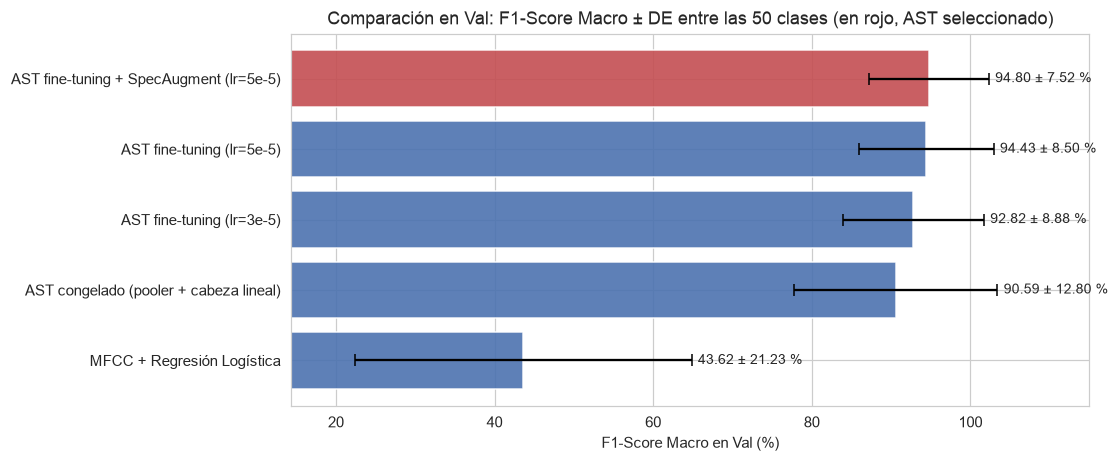

In [15]:
# Selección automática de la configuración AST ganadora según F1-macro en Val
val_ranking = (
    df_experiments.set_index("configuración")
    .sort_values(["val_f1", "val_acc"], ascending=False)
)

ast_names = [cfg["nombre"] for cfg in EXPERIMENT_CONFIGS if cfg["tipo"] == "ast"]
val_ranking_ast = val_ranking.loc[[n for n in val_ranking.index if n in ast_names]]

SELECTED_CONFIG_NAME = val_ranking_ast.index[0]
FINAL_CONFIG = next(cfg for cfg in EXPERIMENT_CONFIGS if cfg["nombre"] == SELECTED_CONFIG_NAME)
winner_row = val_ranking_ast.iloc[0]
runner_up_name = val_ranking_ast.index[1]
runner_up_row = val_ranking_ast.iloc[1]
gap_ast = winner_row["val_f1"] - runner_up_row["val_f1"]

mfcc_row = val_ranking.loc["MFCC + Regresión Logística"]
gap_mfcc = winner_row["val_f1"] - mfcc_row["val_f1"]

print(
    f"Configuración AST seleccionada: {SELECTED_CONFIG_NAME}\n"
    f"  Val F1-macro = {winner_row['val_f1']:.2f} ± {winner_row['val_f1_std_classes']:.2f} % | "
    f"Val Acc = {winner_row['val_acc']:.2f} % | Val Top-3 = {winner_row['val_top3_acc']:.2f} %\n"
    f"  Ventaja vs. segundo mejor AST ({runner_up_name}): {gap_ast:+.2f} pp\n"
    f"  Ventaja vs. baseline clásico MFCC: {gap_mfcc:+.2f} pp"
)

fig, ax = plt.subplots(figsize=(10.2, 4.3))
y_pos = np.arange(len(val_ranking))
bar_colors = ["#C44E52" if name == SELECTED_CONFIG_NAME else "#4C72B0" for name in val_ranking.index]
ax.barh(y_pos, val_ranking["val_f1"], xerr=val_ranking["val_f1_std_classes"], capsize=4, color=bar_colors, alpha=0.9)
ax.set_yticks(y_pos)
ax.set_yticklabels(val_ranking.index)
ax.invert_yaxis()
x_min = max(0.0, float((val_ranking["val_f1"] - val_ranking["val_f1_std_classes"]).min()) - 8.0)
x_max = min(115.0, float((val_ranking["val_f1"] + val_ranking["val_f1_std_classes"]).max()) + 16.0)
ax.set_xlim(x_min, x_max)
for i, (m, s) in enumerate(zip(val_ranking["val_f1"], val_ranking["val_f1_std_classes"])):
    ax.text(m + s + 0.8, i, f"{m:.2f} ± {s:.2f} %", va="center", fontsize=9)
ax.set(
    title="Comparación en Val: F1-Score Macro ± DE entre las 50 clases (en rojo, AST seleccionado)",
    xlabel="F1-Score Macro en Val (%)",
)
plt.tight_layout()
plt.show()

### 2.6. Reentrenamiento del Modelo Seleccionado (`100 %` de `Train`, `2` Épocas)
Cumpliendo el requisito explícito del enunciado (*"Hacer fine tuning de un modelo de AST durante 2 épocas para adaptarlo a la tarea específica"*), se instancia desde cero **`AST fine-tuning + SpecAugment (lr=5e-5)`** (`85 757 234` parámetros entrenables, `AdamW` con `weight_decay = 0.01`, *warmup* lineal del $10\,\%$, `gradient_clip = 1.0`, precisión mixta `float16` en Apple MPS) y se entrena con el **$100\,\%$ del conjunto `Train` ($1\,200$ grabaciones, $150$ lotes/época)** durante exactamente **`EPOCHS_FINAL = 2`** épocas ($1\,090.7\,\text{s}$ totales), registrando métricas cada media época (`0.5, 1.0, 1.5, 2.0`).

Al duplicar los datos de entrenamiento respecto a la exploración, el modelo mejora en **`+2.18 pp`** de *F1-macro* en validación y alcanza su **mejor *checkpoint* en la época `2.0`** con **`Val F1-macro = 96.98 ± 5.72 %`**, **`Val Acc = 97.00 %`**, **`Val Top-3 = 100.00 %`**, `Val Precision Macro = 97.42 %` y **`Val Loss = 0.1213`** (reduciendo la dispersión entre las $50$ clases de `7.52 pp` a `5.72 pp`). En paralelo, el baseline clásico `MFCC + Regresión Logística` reentrenado sobre el $100\,\%$ de `Train` ($0.2\,\text{s}$) alcanza **`Val F1-macro = 50.70 ± 22.72 %`** (`Val Acc = 51.50 %`, `Val Top-3 = 70.50 %`, `Val Loss = 1.9777`), quedando `46.28 pp` por debajo de AST.

In [16]:
# Reentrenamiento final del modelo AST seleccionado con el 100 % de Train durante exactamente 2 épocas
EPOCHS_FINAL = 2

set_seed(RANDOM_STATE)
release_device_memory(DEVICE)

final_loaders = get_loaders(
    batch_size=BATCH_SIZE,
    spec_augment=FINAL_CONFIG["spec_augment"],
    train_indices=None,
    seed=RANDOM_STATE,
)
final_model = build_ast_model(
    MODEL_CHECKPOINT,
    freeze_backbone=FINAL_CONFIG["freeze_backbone"],
    max_length=MAX_LENGTH,
)

print(
    f"Reentrenando '{FINAL_CONFIG['nombre']}' ({MODEL_CHECKPOINT}, MAX_LENGTH = {MAX_LENGTH}) "
    f"sobre el 100 % de Train ({len(df_train):,} clips, {len(final_loaders['Train'])} lotes/época, "
    f"{EPOCHS_FINAL} épocas):\n"
)

final_model, df_history_final, best_epoch_final, train_time_final = fit_ast_model(
    final_model,
    final_loaders["Train"],
    final_loaders["Val"],
    epochs=EPOCHS_FINAL,
    lr=FINAL_CONFIG["lr"],
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    max_grad_norm=MAX_GRAD_NORM,
    device=DEVICE,
    verbose=True,
    restore_best=True,
    eval_every_half_epoch=True,
)

# Reentrenamiento del baseline clásico MFCC + Regresión Logística sobre el 100 % de Train
baseline_artifacts_full, baseline_val_full, baseline_train_time = evaluate_mfcc_logreg(
    MFCC_FEATURES["Train"],
    df_train["label"].to_numpy(),
    MFCC_FEATURES["Val"],
    df_val["label"].to_numpy(),
    seed=RANDOM_STATE,
)

best_val_row = df_history_final.loc[df_history_final["epoch"] == best_epoch_final].iloc[0]
total_params_final = sum(p.numel() for p in final_model.parameters())
trainable_params_final = sum(p.numel() for p in final_model.parameters() if p.requires_grad)

display(pd.Series({
    "Configuración AST seleccionada": FINAL_CONFIG["nombre"],
    "Checkpoint preentrenado": MODEL_CHECKPOINT,
    "Clase de Hugging Face": final_model.__class__.__name__,
    "Conjunto de entrenamiento": f"100 % de Train ({len(df_train):,} grabaciones)",
    "Dimensión de espectrograma": f"{MAX_LENGTH} cuadros × {NUM_MEL_BINS} bandas Mel (16 kHz)",
    "SpecAugment en entrenamiento": bool(FINAL_CONFIG["spec_augment"]),
    "Precisión de cómputo en acelerador": "Mixta automática (float16 autocast)" if DEVICE.type in ("mps", "cuda") else "float32 (CPU)",
    "Activación de salida / pérdida": "Softmax / CrossEntropyLoss",
    "Optimizador": f"AdamW (lr = {FINAL_CONFIG['lr']:.1e}, weight_decay = {WEIGHT_DECAY})",
    "Planificador (scheduler)": f"Warmup lineal ({int(WARMUP_RATIO * 100)} % de los pasos)",
    "Tamaño de lote (Train / Val-Test)": f"{BATCH_SIZE} / {2 * BATCH_SIZE}",
    "Gradient clipping (norma máx.)": MAX_GRAD_NORM,
    "Épocas entrenadas": EPOCHS_FINAL,
    "Mejor checkpoint (F1-macro Val)": f"época {best_epoch_final:.1f}",
    "F1-macro en Val (mejor checkpoint)": f"{best_val_row['val_f1_macro'] * 100:.2f} ± {best_val_row['val_f1_std_classes'] * 100:.2f} %",
    "Exactitud en Val (mejor checkpoint)": f"{best_val_row['val_acc'] * 100:.2f} % (Top-3: {best_val_row['val_top3_acc'] * 100:.2f} %)",
    "F1-macro en Val baseline MFCC (100 % Train)": f"{baseline_val_full['f1_macro'] * 100:.2f} %",
    "Tiempo total entrenamiento AST (s)": round(train_time_final, 1),
    "Parámetros totales / entrenables": f"{total_params_final:,} / {trainable_params_final:,}",
}, name="valor").to_frame())

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

Reentrenando 'AST fine-tuning + SpecAugment (lr=5e-5)' (MIT/ast-finetuned-audioset-10-10-0.4593, MAX_LENGTH = 512) sobre el 100 % de Train (1,200 clips, 150 lotes/época, 2 épocas):

Época  0.5/ 2.0 (243.8s acum.) | Train Loss: 2.2609, F1-macro: 51.74 % | Val Loss: 0.6267, Acc: 86.75 %, F1-macro: 85.79 % *
Época  1.0/ 2.0 (516.9s acum.) | Train Loss: 1.3520, F1-macro: 71.65 % | Val Loss: 0.3276, Acc: 90.75 %, F1-macro: 90.78 % *
Época  1.5/ 2.0 (787.9s acum.) | Train Loss: 0.1249, F1-macro: 96.12 % | Val Loss: 0.1758, Acc: 94.25 %, F1-macro: 94.18 % *
Época  2.0/ 2.0 (1061.0s acum.) | Train Loss: 0.1045, F1-macro: 96.82 % | Val Loss: 0.1213, Acc: 97.00 %, F1-macro: 96.98 % *
Entrenamiento completado en 1090.7s | Mejor checkpoint: época 2.0 (Val F1-macro = 96.98 %)


,valor
Configuración AST seleccionada,AST fine-tuning + SpecAugment (lr=5e-5)
Checkpoint preentrenado,MIT/ast-finetuned-audioset-10-10-0.4593
Clase de Hugging Face,ASTForAudioClassification
Conjunto de entrenamiento,"100 % de Train (1,200 grabaciones)"
Dimensión de espectrograma,512 cuadros × 128 bandas Mel (16 kHz)
SpecAugment en entrenamiento,True
Precisión de cómputo en acelerador,Mixta automática (float16 autocast)
Activación de salida / pérdida,Softmax / CrossEntropyLoss
Optimizador,"AdamW (lr = 5.0e-05, weight_decay = 0.01)"
Planificador (scheduler),Warmup lineal (10 % de los pasos)


---
## 3. Evaluación del Modelo y Análisis de Resultados
En esta sección se analiza la trayectoria de aprendizaje durante las $2$ épocas de *fine-tuning*, se ejecuta la **evaluación única sobre el conjunto de prueba independiente (`Test`, Fold 1, $400$ grabaciones)** aplicando *softmax*, se identifican las categorías con mejor y peor desempeño (tanto a nivel de las $50$ clases como de las $5$ macro-categorías), se estudian los patrones de confusión, se inspeccionan ejemplos cualitativos y mapas de oclusión tiempo-frecuencia, se comparan las representaciones internas antes y después del ajuste fino mediante t-SNE [9] y se evalúa la robustez frente a perturbaciones acústicas.

### 3.1. Curvas de Aprendizaje (`2` Épocas)
La evolución registrada en `0.5, 1.0, 1.5` y `2.0` épocas muestra una convergencia monótona, estable y sin indicios de sobreajuste en `Val`:
- **Época `0.5` ($243.8\,\text{s}$ acum.):** tras el calentamiento inicial (*warmup*), la pérdida es `Train Loss = 2.2609` (`Train F1 = 51.74 %`, `Acc = 52.00 %`) mientras que en validación ya desciende a `Val Loss = 0.6267` (`Val F1 = 85.79 ± 17.10 %`, `Acc = 86.75 %`, `Top-3 = 97.50 %`). Que `Val` supere ampliamente a `Train` en la primera época es consistente con dos factores: las representaciones preentrenadas de AudioSet ya son fuertemente discriminativas y *SpecAugment* regulariza exclusivamente los lotes de entrenamiento.
- **Época `1.0` ($516.9\,\text{s}$ acum.):** `Train Loss` baja a `1.3520` (`Train F1 = 71.65 %`, `Acc = 71.08 %`) y `Val Loss` se reduce casi a la mitad hasta `0.3276` (`Val F1 = 90.78 ± 9.85 %`, `Acc = 90.75 %`, `Top-3 = 99.25 %`), recortando la DE entre clases en `7.25 pp`.
- **Época `1.5` ($787.9\,\text{s}$ acum.):** se produce el mayor salto de ajuste en entrenamiento (`Train Loss = 0.1249`, `Train F1 = 96.12 %`, `Acc = 96.33 %`) acompañado por una nueva mejora en validación (`Val Loss = 0.1758`, `Val F1 = 94.18 ± 8.06 %`, `Acc = 94.25 %`, `Top-3 = 99.75 %`).
- **Época `2.0` ($1\,061.0\,\text{s}$ acum. — mejor *checkpoint*):** las curvas se alinean en **`Train Loss = 0.1045`** (`Train F1 = 96.82 %`, `Acc = 96.83 %`) y **`Val Loss = 0.1213`** (**`Val F1 = 96.98 ± 5.72 %`**, **`Val Acc = 97.00 %`**, **`Val Top-3 = 100.00 %`**), confirmando que el modelo seguía mejorando al cierre de la segunda época.

,Train Loss,Val Loss,Train Acc (%),Val Acc (%),Val Top-3 Acc (%),Train F1-Macro (%),Val F1-Macro (%),Val DE entre clases (%),Tiempo acum. (s)
Época,,,,,,,,,
0.5,2.2609,0.6267,52.00,86.75,97.50,51.74,85.79,17.10,243.8
1.0,1.3520,0.3276,71.08,90.75,99.25,71.65,90.78,9.85,516.9
1.5,0.1249,0.1758,96.33,94.25,99.75,96.12,94.18,8.06,787.9
2.0,0.1045,0.1213,96.83,97.00,100.00,96.82,96.98,5.72,1061.0


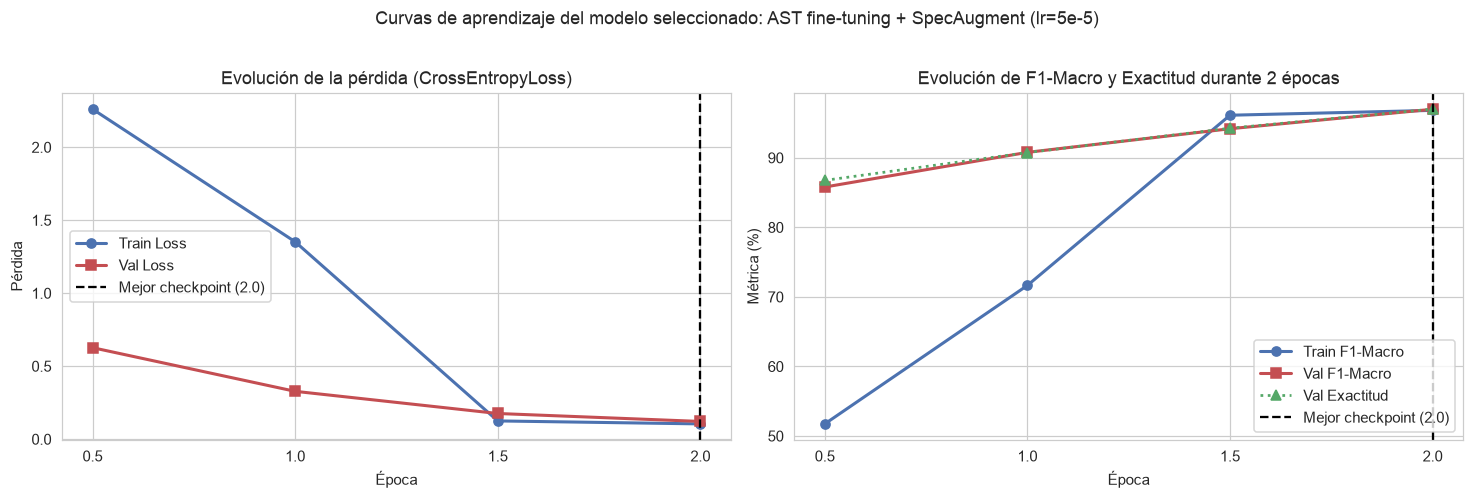

In [17]:
# Tabla de evolución y curvas de aprendizaje del modelo AST final (0.5, 1.0, 1.5 y 2.0 épocas)
df_hist_view = pd.DataFrame({
    "Época": df_history_final["epoch"],
    "Train Loss": df_history_final["train_loss"].round(4),
    "Val Loss": df_history_final["val_loss"].round(4),
    "Train Acc (%)": (df_history_final["train_acc"] * 100).round(2),
    "Val Acc (%)": (df_history_final["val_acc"] * 100).round(2),
    "Val Top-3 Acc (%)": (df_history_final["val_top3_acc"] * 100).round(2),
    "Train F1-Macro (%)": (df_history_final["train_f1_macro"] * 100).round(2),
    "Val F1-Macro (%)": (df_history_final["val_f1_macro"] * 100).round(2),
    "Val DE entre clases (%)": (df_history_final["val_f1_std_classes"] * 100).round(2),
    "Tiempo acum. (s)": df_history_final["time_s"].round(1),
}).set_index("Época")
display(df_hist_view)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
ep_x = df_history_final["epoch"].to_numpy()

axes[0].plot(ep_x, df_history_final["train_loss"], marker="o", lw=2, color="#4C72B0", label="Train Loss")
axes[0].plot(ep_x, df_history_final["val_loss"], marker="s", lw=2, color="#C44E52", label="Val Loss")
axes[0].axvline(best_epoch_final, color="black", linestyle="--", label=f"Mejor checkpoint ({best_epoch_final:.1f})")
axes[0].set(title="Evolución de la pérdida (CrossEntropyLoss)", xlabel="Época", ylabel="Pérdida", xticks=ep_x)
axes[0].legend()

axes[1].plot(ep_x, df_history_final["train_f1_macro"] * 100, marker="o", lw=2, color="#4C72B0", label="Train F1-Macro")
axes[1].plot(ep_x, df_history_final["val_f1_macro"] * 100, marker="s", lw=2, color="#C44E52", label="Val F1-Macro")
axes[1].plot(ep_x, df_history_final["val_acc"] * 100, marker="^", lw=1.8, linestyle=":", color="#55A868", label="Val Exactitud")
axes[1].axvline(best_epoch_final, color="black", linestyle="--", label=f"Mejor checkpoint ({best_epoch_final:.1f})")
axes[1].set(title="Evolución de F1-Macro y Exactitud durante 2 épocas", xlabel="Época", ylabel="Métrica (%)", xticks=ep_x)
axes[1].legend(loc="lower right")

fig.suptitle(f"Curvas de aprendizaje del modelo seleccionado: {FINAL_CONFIG['nombre']}", y=1.02)
plt.tight_layout()
plt.show()

### 3.2. Desempeño Cuantitativo Global y por Macro-Categoría en `Test` (Fold 1)
Se evalúa **una sola vez** el modelo final (`AST fine-tuning + SpecAugment (lr=5e-5)`, restaurado en la época `2.0`) sobre las $400$ grabaciones independientes de **`Test` (`Fold 1`)**, aplicando explícitamente *softmax* sobre los *logits* $\mathbf{z} \in \mathbb{R}^{50}$:
$$
\hat{\mathbf{p}}(x) = \operatorname{softmax}(\mathbf{z})_c = \frac{e^{z_c}}{\sum_{j=1}^{50} e^{z_j}}, \qquad \hat{y} = \arg\max_{c \in \{0,\dots,49\}} \hat{p}_c(x).
$$
Los resultados principales en `Test` son:
- **Desempeño global de AST en `Test` (`Fold 1`):** **Exactitud Top-1 = $93.00\,\%$** (`372/400` aciertos, solo $28$ errores), **Top-3 Accuracy = $98.75\,\%$**, **Precision Macro = $93.58\,\%$**, **Recall Macro = $93.00\,\%$**, **F1-Macro = $92.75 \pm 9.55\,\%$**, **F1-Weighted = $92.75\,\%$** y **`Test Loss = 0.2608`**.
- **Brecha `Test − Val` y ventaja frente a MFCC:** respecto a la mejor época en `Val` (`96.98 %` F1-macro), se observa una diferencia de **$-4.22\,\text{pp}$ en F1-macro** ($-4.00\,\text{pp}$ en exactitud y $+0.139$ en pérdida), acorde con el salto hacia un *fold* completamente aislado (`Fold 1`). Frente al baseline clásico `MFCC + Regresión Logística` en `Test` (`Acc = 42.25 %`, `Top-3 = 62.50 %`, `F1-Macro = 41.79 ± 23.07 %`, `Loss = 2.5674`), AST logra una ventaja de **`+50.75 pp` en exactitud**, **`+50.96 pp` en F1-macro**, **`+36.25 pp` en Top-3**, reduce la dispersión entre clases en **`-13.52 pp`** y recorta la pérdida en casi diez veces (`0.261` vs. `2.567`).
- **Desempeño por las $5$ macro-categorías oficiales ($80$ clips cada una):** **Animales** lidera con **`98.42 %` de F1 medio** (`100.00 %` de exactitud y *recall*, `97.27 %` de *precision*, `+52.62 pp` vs. MFCC), seguido por **Interiores y domésticos** (`91.87 %` F1 medio, `91.25 %` Acc), **Naturaleza y agua** (`91.55 %` F1 medio, `92.50 %` Acc), **Humanos (no habla)** (`91.34 %` F1 medio, `90.00 %` Acc) y **Exteriores y urbanos** (`90.59 %` F1 medio, `91.25 %` Acc, donde se observa la mayor ganancia sobre MFCC: **`+63.48 pp`**). Al agrupar las predicciones en $5 \times 5$ macro-categorías, todos los bloques superan el **$96.2\,\%$ de F1** (entre `96.20 %` y `98.16 %`).

Desempeño global en Test / Fold 1 (AST fine-tuning + SpecAugment (lr=5e-5)):
  Exactitud (Top-1): 93.00 % (372/400 aciertos) | Top-3 Accuracy: 98.75 % | Loss: 0.2608
  Precision Macro: 93.58 % | Recall Macro: 93.00 % | F1-Macro ± DE_clases: 92.75 ± 9.55 % | F1-Weighted: 92.75 %

Comparación Val vs. Test y ventaja frente al baseline clásico MFCC:


,"Val (AST, época 2.0)",Test (AST final),Test (Baseline MFCC),Diferencia (Test − Val),Ventaja vs. MFCC en Test
Loss (CrossEntropy),0.121,0.261,2.567,0.139,-2.307
Exactitud / Accuracy (%),97.000,93.000,42.250,-4.000,50.750
Exactitud Top-3 (%),100.000,98.750,62.500,-1.250,36.250
Precision Macro (%),97.416,93.583,44.432,-3.833,49.151
Recall Macro (%),97.000,93.000,42.250,-4.000,50.750
F1-Score Macro (%),96.977,92.754,41.793,-4.222,50.961
DE F1 entre las 50 clases (%),5.718,9.546,23.069,3.827,-13.523
F1-Score Weighted (%),96.977,92.754,41.793,-4.222,50.961



Desempeño en Test (Fold 1) agrupado por las 5 macro-categorías oficiales:


,Soporte,Exactitud 50-clases (%),Precision media 10 clases (%),Recall medio 10 clases (%),F1 medio 10 clases AST (%),F1 medio 10 clases MFCC (%),Δ F1 vs MFCC (pp),F1 de macro-grupo (5×5) (%)
Macro-categoría,,,,,,,,
Animales,80,100.00,97.27,100.00,98.42,45.80,52.62,98.16
Naturaleza y agua,80,92.50,92.44,92.50,91.55,44.66,46.89,98.14
Humanos (no habla),80,90.00,93.99,90.00,91.34,48.63,42.72,96.82
Interiores y domésticos,80,91.25,93.02,91.25,91.87,42.78,49.09,96.20
Exteriores y urbanos,80,91.25,91.19,91.25,90.59,27.10,63.48,96.89


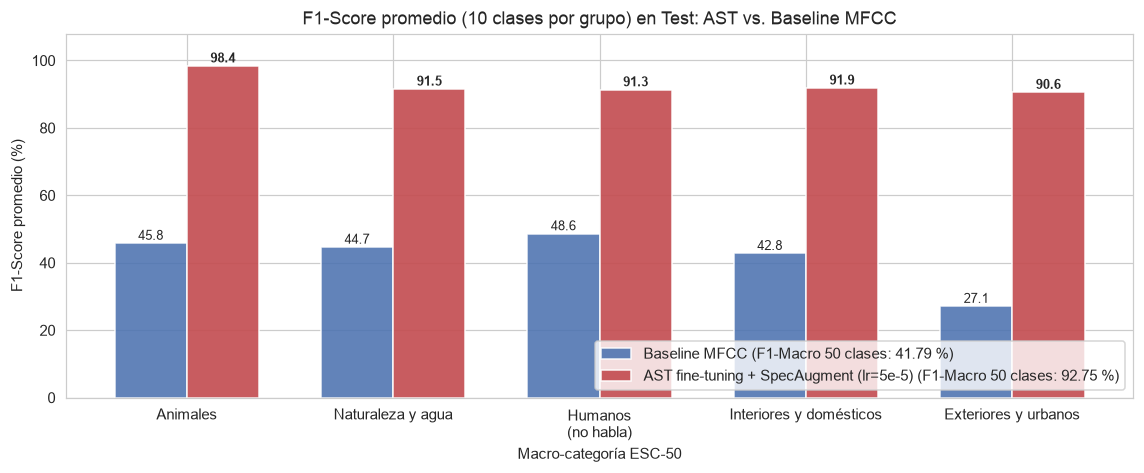

In [18]:
# Evaluación única del modelo AST final en Test (Fold 1), comparación con Val/MFCC y desempeño por macro-categoría
criterion_eval = nn.CrossEntropyLoss()
test_results = evaluate(final_model, final_loaders["Test"], criterion_eval, device=DEVICE, return_outputs=True)

y_true_test = test_results["y_true"]
y_pred_test = test_results["y_pred"]
y_prob_test = test_results["y_prob"]

# Evaluación en Test del baseline clásico MFCC + Regresión Logística (100 % Train)
y_prob_mfcc_test = baseline_artifacts_full.predict_proba(MFCC_FEATURES["Test"])
y_pred_mfcc_test = y_prob_mfcc_test.argmax(axis=-1)
nll_mfcc_test = float(-np.log(np.clip(y_prob_mfcc_test[np.arange(len(y_true_test)), y_true_test], 1e-12, 1.0)).mean())
baseline_test_results = compute_multiclass_metrics(y_true_test, y_pred_mfcc_test, nll_mfcc_test, y_prob=y_prob_mfcc_test)

n_hits_test = int((y_true_test == y_pred_test).sum())
print(
    f"Desempeño global en Test / Fold 1 ({FINAL_CONFIG['nombre']}):\n"
    f"  Exactitud (Top-1): {test_results['accuracy'] * 100:.2f} % ({n_hits_test}/{len(y_true_test)} aciertos) | "
    f"Top-3 Accuracy: {test_results['top3_accuracy'] * 100:.2f} % | Loss: {test_results['loss']:.4f}\n"
    f"  Precision Macro: {test_results['precision_macro'] * 100:.2f} % | "
    f"Recall Macro: {test_results['recall_macro'] * 100:.2f} % | "
    f"F1-Macro ± DE_clases: {test_results['f1_macro'] * 100:.2f} ± {test_results['f1_std_classes'] * 100:.2f} % | "
    f"F1-Weighted: {test_results['f1_weighted'] * 100:.2f} %"
)

val_best_metrics = {
    "loss": float(best_val_row["val_loss"]),
    "accuracy": float(best_val_row["val_acc"]),
    "top3_accuracy": float(best_val_row["val_top3_acc"]),
    "precision_macro": float(best_val_row["val_precision_macro"]),
    "recall_macro": float(best_val_row["val_recall_macro"]),
    "f1_macro": float(best_val_row["val_f1_macro"]),
    "f1_std_classes": float(best_val_row["val_f1_std_classes"]),
    "f1_weighted": float(best_val_row["val_f1_weighted"]),
}

metric_rows = [
    ("Loss (CrossEntropy)", "loss", 1.0),
    ("Exactitud / Accuracy (%)", "accuracy", 100.0),
    ("Exactitud Top-3 (%)", "top3_accuracy", 100.0),
    ("Precision Macro (%)", "precision_macro", 100.0),
    ("Recall Macro (%)", "recall_macro", 100.0),
    ("F1-Score Macro (%)", "f1_macro", 100.0),
    ("DE F1 entre las 50 clases (%)", "f1_std_classes", 100.0),
    ("F1-Score Weighted (%)", "f1_weighted", 100.0),
]

df_val_vs_test = pd.DataFrame({
    col_name: {label: src[key] * scale for label, key, scale in metric_rows}
    for col_name, src in [
        (f"Val (AST, época {best_epoch_final:.1f})", val_best_metrics),
        ("Test (AST final)", test_results),
        ("Test (Baseline MFCC)", baseline_test_results),
    ]
})
df_val_vs_test["Diferencia (Test − Val)"] = df_val_vs_test["Test (AST final)"] - df_val_vs_test[f"Val (AST, época {best_epoch_final:.1f})"]
df_val_vs_test["Ventaja vs. MFCC en Test"] = df_val_vs_test["Test (AST final)"] - df_val_vs_test["Test (Baseline MFCC)"]
print("\nComparación Val vs. Test y ventaja frente al baseline clásico MFCC:")
display(df_val_vs_test.round(3))

# Desempeño agrupado por las 5 macro-categorías oficiales (tanto a nivel de 50 clases promediadas como a nivel de grupo 5x5)
report_dict_50 = classification_report(
    y_true_test, y_pred_test, labels=np.arange(NUM_LABELS), target_names=CLASSES,
    digits=4, output_dict=True, zero_division=0,
)
df_report_50 = pd.DataFrame(report_dict_50).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]
df_report_50[["precision", "recall", "f1-score"]] *= 100.0
df_report_50["support"] = df_report_50["support"].astype(int)
df_report_50["macro_group"] = [CLASS_TO_MACRO_GROUP[c] for c in CLASSES]

f1_mfcc_per_class = f1_score(y_true_test, y_pred_mfcc_test, labels=np.arange(NUM_LABELS), average=None, zero_division=0) * 100.0
df_report_50["f1_mfcc"] = f1_mfcc_per_class

group_true = np.array([GROUP_ORDER.index(CLASS_TO_MACRO_GROUP[ID2LABEL[int(y)]]) for y in y_true_test])
group_pred_ast = np.array([GROUP_ORDER.index(CLASS_TO_MACRO_GROUP[ID2LABEL[int(y)]]) for y in y_pred_test])
group_pred_mfcc = np.array([GROUP_ORDER.index(CLASS_TO_MACRO_GROUP[ID2LABEL[int(y)]]) for y in y_pred_mfcc_test])

macro_rep_ast = classification_report(
    group_true, group_pred_ast, labels=np.arange(len(GROUP_ORDER)), target_names=GROUP_ORDER,
    digits=4, output_dict=True, zero_division=0,
)

macro_rows = []
for grp in GROUP_ORDER:
    sub_50 = df_report_50[df_report_50["macro_group"] == grp]
    mask_g = np.array([CLASS_TO_MACRO_GROUP[ID2LABEL[int(y)]] == grp for y in y_true_test])
    exact_50_acc = float(np.mean(y_pred_test[mask_g] == y_true_test[mask_g]) * 100.0)
    macro_rows.append({
        "Macro-categoría": grp,
        "Soporte": int(sub_50["support"].sum()),
        "Exactitud 50-clases (%)": exact_50_acc,
        "Precision media 10 clases (%)": float(sub_50["precision"].mean()),
        "Recall medio 10 clases (%)": float(sub_50["recall"].mean()),
        "F1 medio 10 clases AST (%)": float(sub_50["f1-score"].mean()),
        "F1 medio 10 clases MFCC (%)": float(sub_50["f1_mfcc"].mean()),
        "Δ F1 vs MFCC (pp)": float(sub_50["f1-score"].mean() - sub_50["f1_mfcc"].mean()),
        "F1 de macro-grupo (5×5) (%)": float(macro_rep_ast[grp]["f1-score"] * 100.0),
    })
df_macro_eval = pd.DataFrame(macro_rows).set_index("Macro-categoría")
print("\nDesempeño en Test (Fold 1) agrupado por las 5 macro-categorías oficiales:")
display(df_macro_eval.round(2))

fig, ax = plt.subplots(figsize=(10.5, 4.4))
x_g = np.arange(len(GROUP_ORDER))
bw = 0.35
ax.bar(x_g - bw / 2, df_macro_eval["F1 medio 10 clases MFCC (%)"], width=bw, color="#4C72B0", alpha=0.88,
       label=f"Baseline MFCC (F1-Macro 50 clases: {baseline_test_results['f1_macro']*100:.2f} %)")
ax.bar(x_g + bw / 2, df_macro_eval["F1 medio 10 clases AST (%)"], width=bw, color="#C44E52", alpha=0.92,
       label=f"{FINAL_CONFIG['nombre']} (F1-Macro 50 clases: {test_results['f1_macro']*100:.2f} %)")
for i, (vm, va) in enumerate(zip(df_macro_eval["F1 medio 10 clases MFCC (%)"], df_macro_eval["F1 medio 10 clases AST (%)"])):
    ax.text(i - bw / 2, vm + 1.0, f"{vm:.1f}", ha="center", fontsize=8.5)
    ax.text(i + bw / 2, va + 1.0, f"{va:.1f}", ha="center", fontsize=8.5, fontweight="bold")
ax.set_xticks(x_g)
ax.set_xticklabels([g.replace(" (", "\n(") for g in GROUP_ORDER])
ax.set_ylim(0.0, 108.0)
ax.set(title="F1-Score promedio (10 clases por grupo) en Test: AST vs. Baseline MFCC",
       xlabel="Macro-categoría ESC-50", ylabel="F1-Score promedio (%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 3.3. Análisis Detallado de Categorías (Mejor y Peor Rendimiento) y Matriz de Confusión
Con $50$ clases sonoras, el análisis se presenta en tres niveles complementarios cuyos hallazgos cuantitativos en `Test` (`Fold 1`) se resumen a continuación:
1. **Ranking completo y extremos (Top-10 mejores y Top-10 más retadoras):**
   - **$22$ de las $50$ categorías ($44\,\%$) alcanzaron un desempeño perfecto (`F1 = 100.00 %`, $8/8$ aciertos, $0$ FN y $0$ FP)**, entre ellas `brushing_teeth`, `can_opening`, `chirping_birds`, `clapping`, `clock_alarm`, `clock_tick`, `cow`, `crickets`, `crow` y `dog`.
   - Las categorías más retadoras fueron **`washing_machine`** (`F1 = 57.14 %`, `P = 66.67 %`, `R = 50.00 %`, `TP=4, FN=4, FP=2`), **`wind`** (`F1 = 61.54 %`, `P = 80.00 %`, `R = 50.00 %`, `TP=4, FN=4, FP=1`) y **`crying_baby`** (`F1 = 76.92 %`, `P = 100.00 %`, `R = 62.50 %`, `TP=5, FN=3, FP=0`), seguidas por `footsteps` (`80.00 %`), `vacuum_cleaner` (`80.00 %`) y `sea_waves` (`80.00 %`, con `R = 100.00 %` pero `P = 66.67 %` por $4$ falsos positivos provenientes de `wind`). Incluso en estas clases difíciles, AST supera ampliamente a MFCC (por ejemplo, `+61.54 pp` en `wind` y `+82.35 pp` en `engine`, donde MFCC obtuvo `0.00 %`).
2. **Matriz de confusión $50 \times 50$ ordenada por macro-categorías y matriz agregada $5 \times 5$:** al ordenar los ejes según los cinco bloques de $10$ clases, se observa que la gran mayoría de la masa se concentra sobre la diagonal principal y que los errores cercanos a cada bloque reflejan confusiones de granularidad fina dentro del mismo dominio acústico.
3. **Descomposición de los $28$ errores en `Test` ($7.00\,\%$ de los $400$ clips):** **`17` errores ($60.7\,\%$) ocurren dentro de la misma macro-categoría (intra-grupo)** y **`11` ($39.3\,\%$) entre macro-categorías distintas (inter-grupo)**. Los cuatro pares más frecuentes concentran más de un tercio de todos los desaciertos: **`wind → sea_waves`** ($4$ clips, $14.3\,\%$, intra-grupo), **`crying_baby → cat`** ($2$ clips, $7.1\,\%$, inter-grupo), **`vacuum_cleaner → washing_machine`** ($2$ clips, $7.1\,\%$, intra-grupo) y **`washing_machine → engine`** ($2$ clips, $7.1\,\%$, inter-grupo).

Categorías con F1 = 100.0 % en Test: 22 de 50
Mejor categoría: 'brushing_teeth' (Humanos (no habla)) -> F1 = 100.00 % | P = 100.00 % | R = 100.00 %
Categoría más retadora: 'washing_machine' (Interiores y domésticos) -> F1 = 57.14 % | P = 66.67 % | R = 50.00 %

Top-10 categorías con MEJOR desempeño en Test:


,macro_grupo,soporte,TP,FN,FP,errores (FN+FP),precision_%,recall_%,f1_%,f1_mfcc_%,mejora_vs_mfcc_pp
categoría,,,,,,,,,,,
brushing_teeth,Humanos (no habla),8,8,0,0,0,100.0,100.0,100.0,62.50,37.50
can_opening,Interiores y domésticos,8,8,0,0,0,100.0,100.0,100.0,77.78,22.22
chirping_birds,Naturaleza y agua,8,8,0,0,0,100.0,100.0,100.0,37.50,62.50
clapping,Humanos (no habla),8,8,0,0,0,100.0,100.0,100.0,53.33,46.67
clock_alarm,Interiores y domésticos,8,8,0,0,0,100.0,100.0,100.0,62.50,37.50
clock_tick,Interiores y domésticos,8,8,0,0,0,100.0,100.0,100.0,25.00,75.00
cow,Animales,8,8,0,0,0,100.0,100.0,100.0,53.33,46.67
crickets,Naturaleza y agua,8,8,0,0,0,100.0,100.0,100.0,50.00,50.00
crow,Animales,8,8,0,0,0,100.0,100.0,100.0,46.15,53.85


Top-10 categorías con MENOR desempeño en Test:


,macro_grupo,soporte,TP,FN,FP,errores (FN+FP),precision_%,recall_%,f1_%,f1_mfcc_%,mejora_vs_mfcc_pp
categoría,,,,,,,,,,,
washing_machine,Interiores y domésticos,8,4,4,2,6,66.67,50.0,57.14,28.57,28.57
wind,Naturaleza y agua,8,4,4,1,5,80.00,50.0,61.54,0.00,61.54
crying_baby,Humanos (no habla),8,5,3,0,3,100.00,62.5,76.92,73.68,3.24
footsteps,Humanos (no habla),8,6,2,1,3,85.71,75.0,80.00,9.09,70.91
vacuum_cleaner,Interiores y domésticos,8,6,2,1,3,85.71,75.0,80.00,15.38,64.62
sea_waves,Naturaleza y agua,8,8,0,4,4,66.67,100.0,80.00,35.29,44.71
engine,Exteriores y urbanos,8,7,1,2,3,77.78,87.5,82.35,0.00,82.35
cat,Animales,8,8,0,3,3,72.73,100.0,84.21,50.00,34.21
car_horn,Exteriores y urbanos,8,6,2,0,2,100.00,75.0,85.71,62.50,23.21


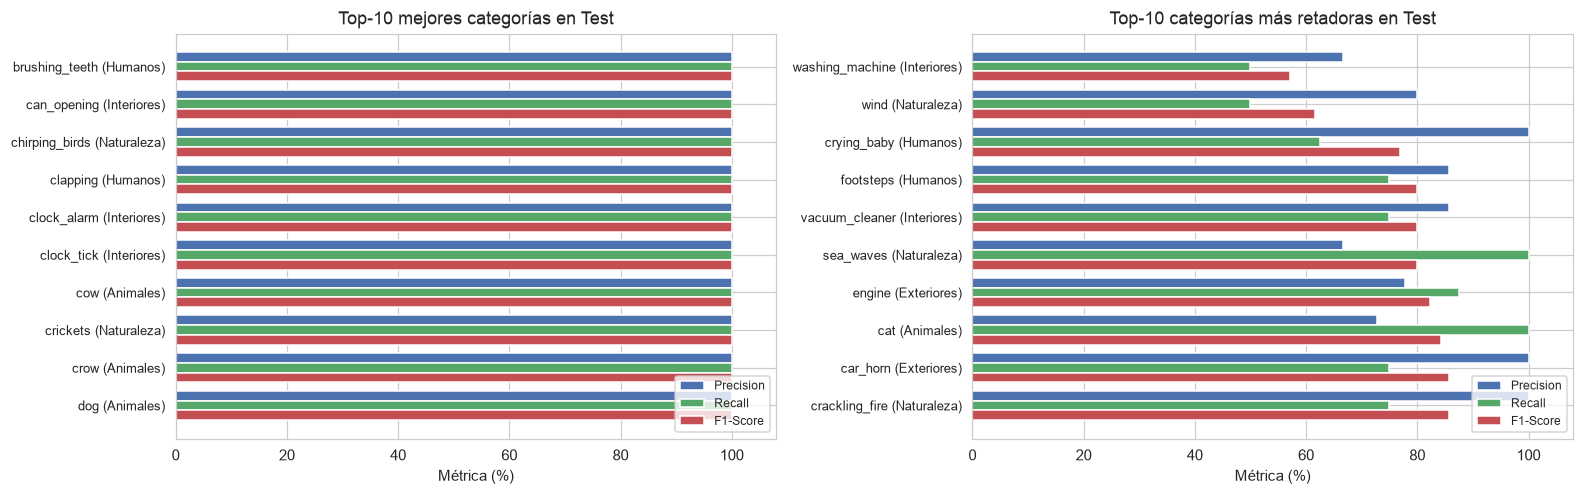

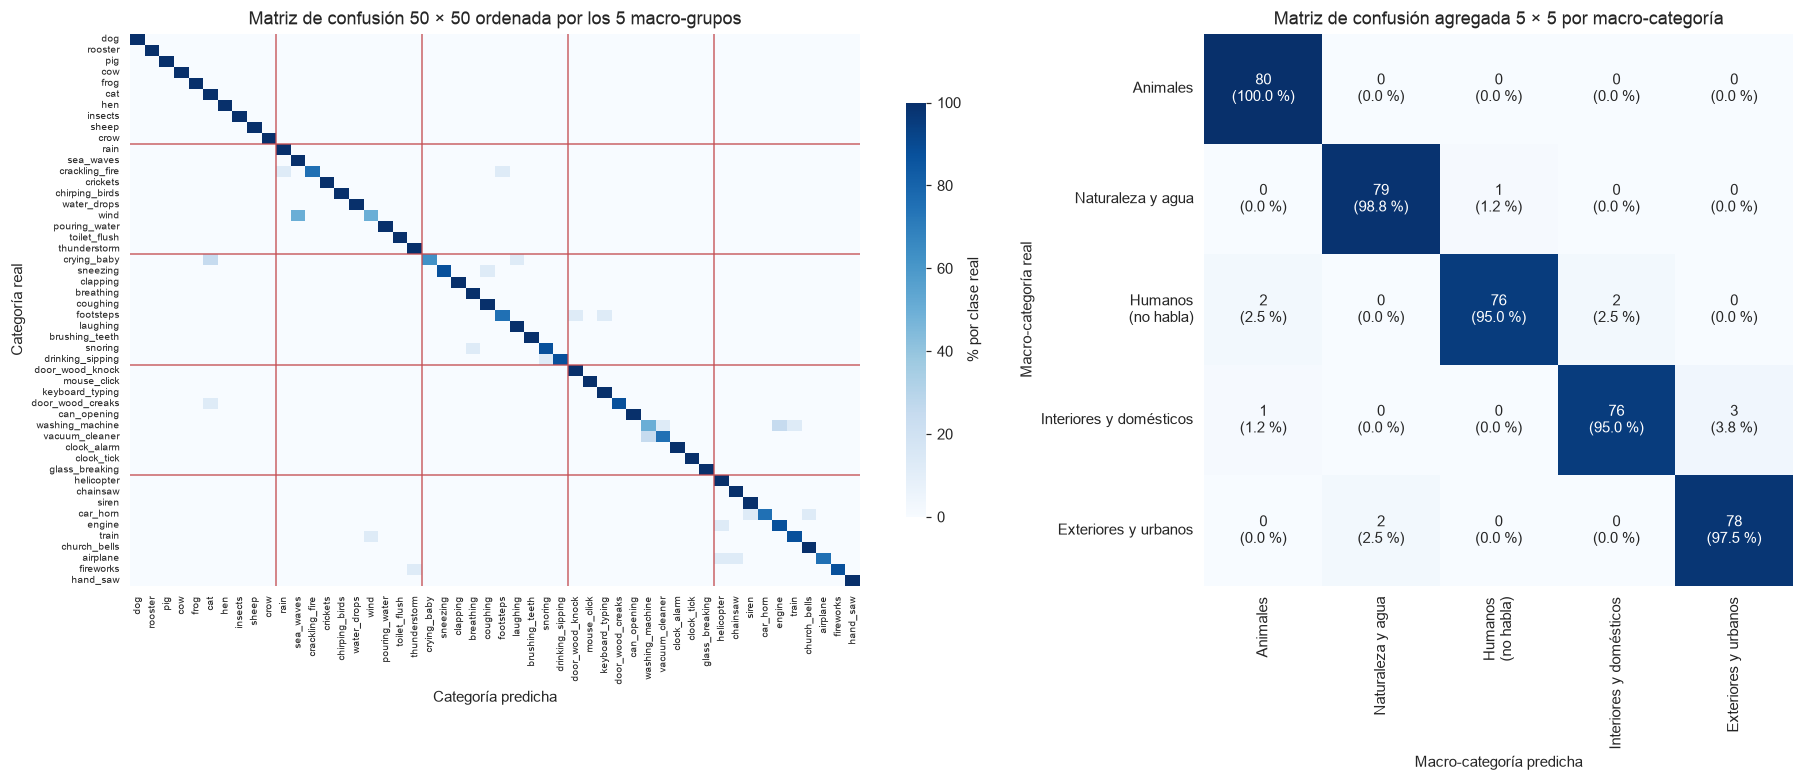

In [19]:
# Desglose completo por las 50 clases, Top-10 mejores/peores y matrices de confusión (50x50 y 5x5)
cm_alpha = confusion_matrix(y_true_test, y_pred_test, labels=np.arange(NUM_LABELS))

per_class_rows = []
for idx, cls_name in enumerate(CLASSES):
    tp = int(cm_alpha[idx, idx])
    fn = int(cm_alpha[idx, :].sum() - tp)
    fp = int(cm_alpha[:, idx].sum() - tp)
    support = int(cm_alpha[idx, :].sum())
    f1_ast = float(df_report_50.loc[cls_name, "f1-score"])
    f1_mf = float(df_report_50.loc[cls_name, "f1_mfcc"])
    per_class_rows.append({
        "categoría": cls_name,
        "macro_grupo": CLASS_TO_MACRO_GROUP[cls_name],
        "soporte": support,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "errores (FN+FP)": fn + fp,
        "precision_%": float(df_report_50.loc[cls_name, "precision"]),
        "recall_%": float(df_report_50.loc[cls_name, "recall"]),
        "f1_%": f1_ast,
        "f1_mfcc_%": f1_mf,
        "mejora_vs_mfcc_pp": f1_ast - f1_mf,
    })

df_class_analysis = (
    pd.DataFrame(per_class_rows)
    .sort_values(["f1_%", "recall_%", "precision_%"], ascending=[False, False, False])
    .set_index("categoría")
)

top10_best = df_class_analysis.head(10)
top10_worst = df_class_analysis.tail(10).sort_values(["f1_%", "recall_%", "precision_%"], ascending=True)
best_cat = top10_best.index[0]
worst_cat = top10_worst.index[0]
n_perfect_classes = int((df_class_analysis["f1_%"] >= 99.99).sum())

print(
    f"Categorías con F1 = 100.0 % en Test: {n_perfect_classes} de {NUM_LABELS}\n"
    f"Mejor categoría: '{best_cat}' ({df_class_analysis.loc[best_cat, 'macro_grupo']}) -> "
    f"F1 = {df_class_analysis.loc[best_cat, 'f1_%']:.2f} % | P = {df_class_analysis.loc[best_cat, 'precision_%']:.2f} % | "
    f"R = {df_class_analysis.loc[best_cat, 'recall_%']:.2f} %\n"
    f"Categoría más retadora: '{worst_cat}' ({df_class_analysis.loc[worst_cat, 'macro_grupo']}) -> "
    f"F1 = {df_class_analysis.loc[worst_cat, 'f1_%']:.2f} % | P = {df_class_analysis.loc[worst_cat, 'precision_%']:.2f} % | "
    f"R = {df_class_analysis.loc[worst_cat, 'recall_%']:.2f} %"
)

print("\nTop-10 categorías con MEJOR desempeño en Test:")
display(top10_best.round(2))
print("Top-10 categorías con MENOR desempeño en Test:")
display(top10_worst.round(2))

# Gráfica comparativa Top-10 mejores vs Top-10 más retadoras
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
for ax, sub_df, title_s in [
    (axes[0], top10_best, "Top-10 mejores categorías en Test"),
    (axes[1], top10_worst, "Top-10 categorías más retadoras en Test"),
]:
    y_i = np.arange(len(sub_df))
    h = 0.26
    ax.barh(y_i - h, sub_df["precision_%"], height=h, color="#4C72B0", label="Precision")
    ax.barh(y_i, sub_df["recall_%"], height=h, color="#55A868", label="Recall")
    ax.barh(y_i + h, sub_df["f1_%"], height=h, color="#C44E52", label="F1-Score")
    ax.set_yticks(y_i)
    ax.set_yticklabels([f"{c} ({g.split()[0]})" for c, g in zip(sub_df.index, sub_df["macro_grupo"])], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlim(0.0, 108.0)
    ax.set(title=title_s, xlabel="Métrica (%)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# Matriz de confusión 50x50 ordenada por los 5 macro-grupos y matriz agregada 5x5
order_idx = [LABEL2ID[c] for c in CLASSES_BY_GROUP]
cm_grouped = cm_alpha[np.ix_(order_idx, order_idx)]
cm_grouped_pct = cm_grouped / np.maximum(1, cm_grouped.sum(axis=1, keepdims=True)) * 100.0

cm_macro = confusion_matrix(group_true, group_pred_ast, labels=np.arange(len(GROUP_ORDER)))
cm_macro_pct = cm_macro / np.maximum(1, cm_macro.sum(axis=1, keepdims=True)) * 100.0
annot_macro = np.array([
    [f"{cnt}\n({pct:.1f} %)" for cnt, pct in zip(rc, rp)]
    for rc, rp in zip(cm_macro, cm_macro_pct)
])

fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.2), gridspec_kw={"width_ratios": [1.55, 1.0]})

sns.heatmap(
    cm_grouped_pct, cmap="Blues", xticklabels=CLASSES_BY_GROUP, yticklabels=CLASSES_BY_GROUP,
    cbar_kws={"label": "% por clase real", "shrink": 0.75}, vmin=0, vmax=100, ax=axes[0],
)
for b in range(10, NUM_LABELS, 10):
    axes[0].axhline(b, color="#C44E52", lw=1.1, alpha=0.8)
    axes[0].axvline(b, color="#C44E52", lw=1.1, alpha=0.8)
axes[0].tick_params(axis="x", labelrotation=90, labelsize=6.5)
axes[0].tick_params(axis="y", labelrotation=0, labelsize=6.5)
axes[0].set(
    title="Matriz de confusión 50 × 50 ordenada por los 5 macro-grupos",
    xlabel="Categoría predicha",
    ylabel="Categoría real",
)

sns.heatmap(
    cm_macro_pct, annot=annot_macro, fmt="", cmap="Blues",
    xticklabels=[g.replace(" (", "\n(") for g in GROUP_ORDER],
    yticklabels=[g.replace(" (", "\n(") for g in GROUP_ORDER],
    cbar=False, vmin=0, vmax=100, ax=axes[1],
)
axes[1].set(
    title="Matriz de confusión agregada 5 × 5 por macro-categoría",
    xlabel="Macro-categoría predicha",
    ylabel="Macro-categoría real",
)

plt.tight_layout()
plt.show()

Total de errores en Test: 28 de 400 clips (7.00 %)
  Errores dentro de la misma macro-categoría (intra-grupo): 17 (60.7 %)
  Errores entre macro-categorías distintas (inter-grupo):    11 (39.3 %)


,Par de confusión (Real → Predicción),macro_real,macro_pred,mismo_grupo,clips_confundidos,% sobre errores de Test
0,wind → sea_waves,Naturaleza y agua,Naturaleza y agua,True,4,14.3
1,crying_baby → cat,Humanos (no habla),Animales,False,2,7.1
2,vacuum_cleaner → washing_machine,Interiores y domésticos,Interiores y domésticos,True,2,7.1
3,washing_machine → engine,Interiores y domésticos,Exteriores y urbanos,False,2,7.1
4,airplane → chainsaw,Exteriores y urbanos,Exteriores y urbanos,True,1,3.6
5,airplane → helicopter,Exteriores y urbanos,Exteriores y urbanos,True,1,3.6
6,car_horn → church_bells,Exteriores y urbanos,Exteriores y urbanos,True,1,3.6
7,car_horn → siren,Exteriores y urbanos,Exteriores y urbanos,True,1,3.6
8,crackling_fire → footsteps,Naturaleza y agua,Humanos (no habla),False,1,3.6
9,crackling_fire → rain,Naturaleza y agua,Naturaleza y agua,True,1,3.6


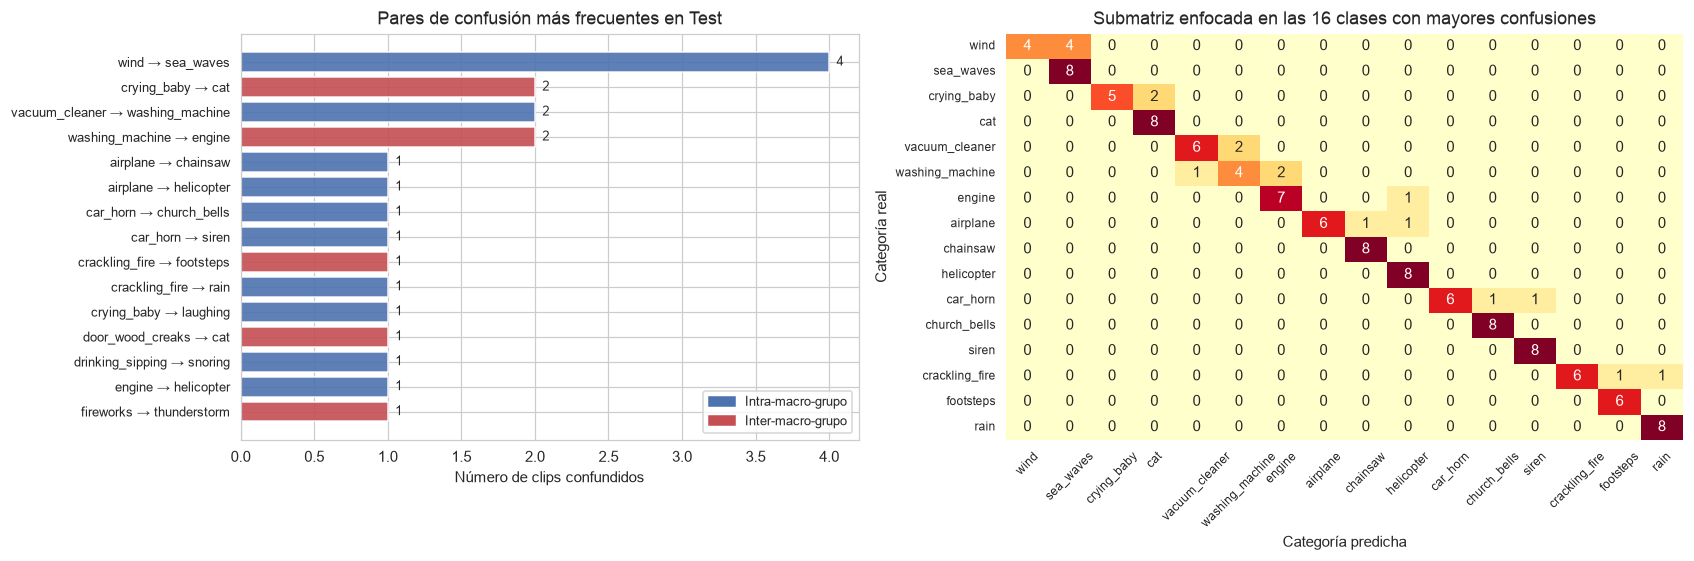

In [20]:
# Descomposición de errores (intra-grupo vs inter-grupo), pares más confundidos y submatriz enfocada
total_errors = int((y_true_test != y_pred_test).sum())
confusion_pairs = []

for i, real_c in enumerate(CLASSES):
    for j, pred_c in enumerate(CLASSES):
        if i != j and cm_alpha[i, j] > 0:
            g_real = CLASS_TO_MACRO_GROUP[real_c]
            g_pred = CLASS_TO_MACRO_GROUP[pred_c]
            confusion_pairs.append({
                "Par de confusión (Real → Predicción)": f"{real_c} → {pred_c}",
                "real": real_c,
                "pred": pred_c,
                "macro_real": g_real,
                "macro_pred": g_pred,
                "mismo_grupo": g_real == g_pred,
                "clips_confundidos": int(cm_alpha[i, j]),
                "% sobre errores de Test": round(float(cm_alpha[i, j]) / max(1, total_errors) * 100.0, 1),
            })

if confusion_pairs:
    df_conf_pairs = (
        pd.DataFrame(confusion_pairs)
        .sort_values(["clips_confundidos", "Par de confusión (Real → Predicción)"], ascending=[False, True])
        .reset_index(drop=True)
    )
    intra_err = int(df_conf_pairs.loc[df_conf_pairs["mismo_grupo"], "clips_confundidos"].sum())
    inter_err = int(df_conf_pairs.loc[~df_conf_pairs["mismo_grupo"], "clips_confundidos"].sum())
    print(
        f"Total de errores en Test: {total_errors} de {len(y_true_test)} clips ({total_errors / len(y_true_test) * 100:.2f} %)\n"
        f"  Errores dentro de la misma macro-categoría (intra-grupo): {intra_err} ({intra_err / total_errors * 100:.1f} %)\n"
        f"  Errores entre macro-categorías distintas (inter-grupo):    {inter_err} ({inter_err / total_errors * 100:.1f} %)"
    )
    display(
        df_conf_pairs[
            ["Par de confusión (Real → Predicción)", "macro_real", "macro_pred", "mismo_grupo", "clips_confundidos", "% sobre errores de Test"]
        ].head(15)
    )

    top_pairs = df_conf_pairs.head(15)
    focus_classes = []
    for _, r in top_pairs.iterrows():
        for cname in (r["real"], r["pred"]):
            if cname not in focus_classes and len(focus_classes) < 16:
                focus_classes.append(cname)

    focus_idx = [LABEL2ID[c] for c in focus_classes]
    cm_focus = cm_alpha[np.ix_(focus_idx, focus_idx)]

    fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), gridspec_kw={"width_ratios": [1.05, 1.15]})

    y_p = np.arange(len(top_pairs))
    pair_colors = ["#4C72B0" if mg else "#C44E52" for mg in top_pairs["mismo_grupo"]]
    axes[0].barh(y_p, top_pairs["clips_confundidos"], color=pair_colors, alpha=0.9)
    axes[0].set_yticks(y_p)
    axes[0].set_yticklabels(top_pairs["Par de confusión (Real → Predicción)"], fontsize=8.5)
    axes[0].invert_yaxis()
    for i, cnt in enumerate(top_pairs["clips_confundidos"]):
        axes[0].text(cnt + 0.05, i, str(cnt), va="center", fontsize=8.5)
    p_handles = [
        plt.Rectangle((0, 0), 1, 1, color="#4C72B0", label="Intra-macro-grupo"),
        plt.Rectangle((0, 0), 1, 1, color="#C44E52", label="Inter-macro-grupo"),
    ]
    axes[0].legend(handles=p_handles, loc="lower right", fontsize=8.5)
    axes[0].set(title="Pares de confusión más frecuentes en Test", xlabel="Número de clips confundidos")

    sns.heatmap(
        cm_focus, annot=True, fmt="d", cmap="YlOrRd",
        xticklabels=focus_classes, yticklabels=focus_classes,
        cbar=False, ax=axes[1],
    )
    axes[1].tick_params(axis="x", labelrotation=45, labelsize=8)
    axes[1].tick_params(axis="y", labelrotation=0, labelsize=8)
    axes[1].set(
        title=f"Submatriz enfocada en las {len(focus_classes)} clases con mayores confusiones",
        xlabel="Categoría predicha",
        ylabel="Categoría real",
    )
    plt.tight_layout()
    plt.show()
else:
    df_conf_pairs = pd.DataFrame(
        columns=["Par de confusión (Real → Predicción)", "real", "pred", "macro_real", "macro_pred", "mismo_grupo", "clips_confundidos", "% sobre errores de Test"]
    )
    intra_err, inter_err = 0, 0
    print("No se registraron errores en Test (exactitud del 100 %).")

### 3.4. Análisis Cualitativo de Predicciones e Interpretabilidad Tiempo-Frecuencia
Más allá de las métricas agregadas, se inspeccionan ejemplos concretos de **`Test`** junto con su distribución *softmax* y su estructura espectral:
1. **Aciertos prototípicos y errores más relevantes:** los cinco aciertos de máxima confianza (uno por macro-categoría) superan el **$99.6\,\%$ de probabilidad *softmax***: `pouring_water` ($99.85\,\%$, *Naturaleza y agua*), `door_wood_creaks` ($99.82\,\%$, *Interiores y domésticos*), `insects` ($99.78\,\%$, *Animales*), `chainsaw` ($99.70\,\%$, *Exteriores y urbanos*) y `brushing_teeth` ($99.63\,\%$, *Humanos*). Por su parte, los errores con mayor confianza corresponden a firmas espectrales físicamente ambiguas —como impulsos secos en `footsteps → keyboard_typing` ($98.79\,\%$) y `footsteps → door_wood_knock` ($98.62\,\%$), zumbidos rotativos en `washing_machine → train` ($98.21\,\%$) y `washing_machine → engine` ($97.15\,\%$, $94.98\,\%$), o turbulencia de banda ancha en `wind → sea_waves` ($96.69\,\%$, $96.66\,\%$)—. En numerosos errores (`vacuum_cleaner → washing_machine`, `drinking_sipping → snoring`, `sneezing → coughing`, `crying_baby → cat`), la clase real aparece como **segunda opción *softmax***, explicando por qué el *Top-3 Accuracy* alcanza el **$98.75\,\%$**.
2. **Grilla visual de espectrogramas de `Test` (`2 × 4`):** contrasta en la fila superior $4$ aciertos claros (`pouring_water`, `insects`, `dog`) frente a $4$ errores de alta confianza (`footsteps`, `washing_machine`), evidenciando similitudes visuales directas en los patrones verticales de impulsos y en las bandas continuas de ruido estacionario.
3. **Calibración de confianza y mapa de saliencia por oclusión tiempo-frecuencia:** la mediana de probabilidad máxima *softmax* separa con claridad los **$372$ aciertos (mediana = $98.8\,\%$)** de los **$28$ errores (mediana = $73.1\,\%$)**, aunque existe una cola de desaciertos sobreconfiados. En el mapa de oclusión sobre `pouring_water` (`P base = 99.9 %`), la mayor caída de probabilidad ($\Delta P$ hasta $\approx 0.35\,\text{pp}$) se localiza en las **bandas Mel medias (`~16–64`) durante el intervalo activo de vertido (`~2.2–4.5 s`)**, mientras que el relleno final (`> 4.98 s`) y las regiones inactivas muestran impacto prácticamente nulo ($\Delta P \approx 0$).

Resumen cualitativo en Test (5 aciertos prototípicos por macro-grupo + 15 de 28 errores):


,tipo,archivo,macro_real,real,predicción,P(pred),P(real),2da_opción (P),RMS (dBFS)
id_test,,,,,,,,,
304,Acierto (máx. confianza),fold1_test_0304.wav,Naturaleza y agua,pouring_water,pouring_water,0.9985,0.9985,water_drops (0.0002),-39.6
91,Acierto (máx. confianza),fold1_test_0091.wav,Interiores y domésticos,door_wood_creaks,door_wood_creaks,0.9982,0.9982,cat (0.0002),-32.3
215,Acierto (máx. confianza),fold1_test_0215.wav,Animales,insects,insects,0.9978,0.9978,hand_saw (0.0002),-33.1
43,Acierto (máx. confianza),fold1_test_0043.wav,Exteriores y urbanos,chainsaw,chainsaw,0.9970,0.9970,engine (0.0003),-18.5
301,Acierto (máx. confianza),fold1_test_0301.wav,Humanos (no habla),brushing_teeth,brushing_teeth,0.9963,0.9963,pouring_water (0.0006),-40.6
307,Error en Test,fold1_test_0307.wav,Humanos (no habla),footsteps,keyboard_typing,0.9879,0.0002,clapping (0.0023),-32.5
152,Error en Test,fold1_test_0152.wav,Humanos (no habla),footsteps,door_wood_knock,0.9862,0.0004,drinking_sipping (0.0015),-31.0
272,Error en Test,fold1_test_0272.wav,Interiores y domésticos,washing_machine,train,0.9821,0.0010,thunderstorm (0.0022),-18.9
165,Error en Test,fold1_test_0165.wav,Interiores y domésticos,washing_machine,engine,0.9715,0.0051,washing_machine (0.0051),-14.3


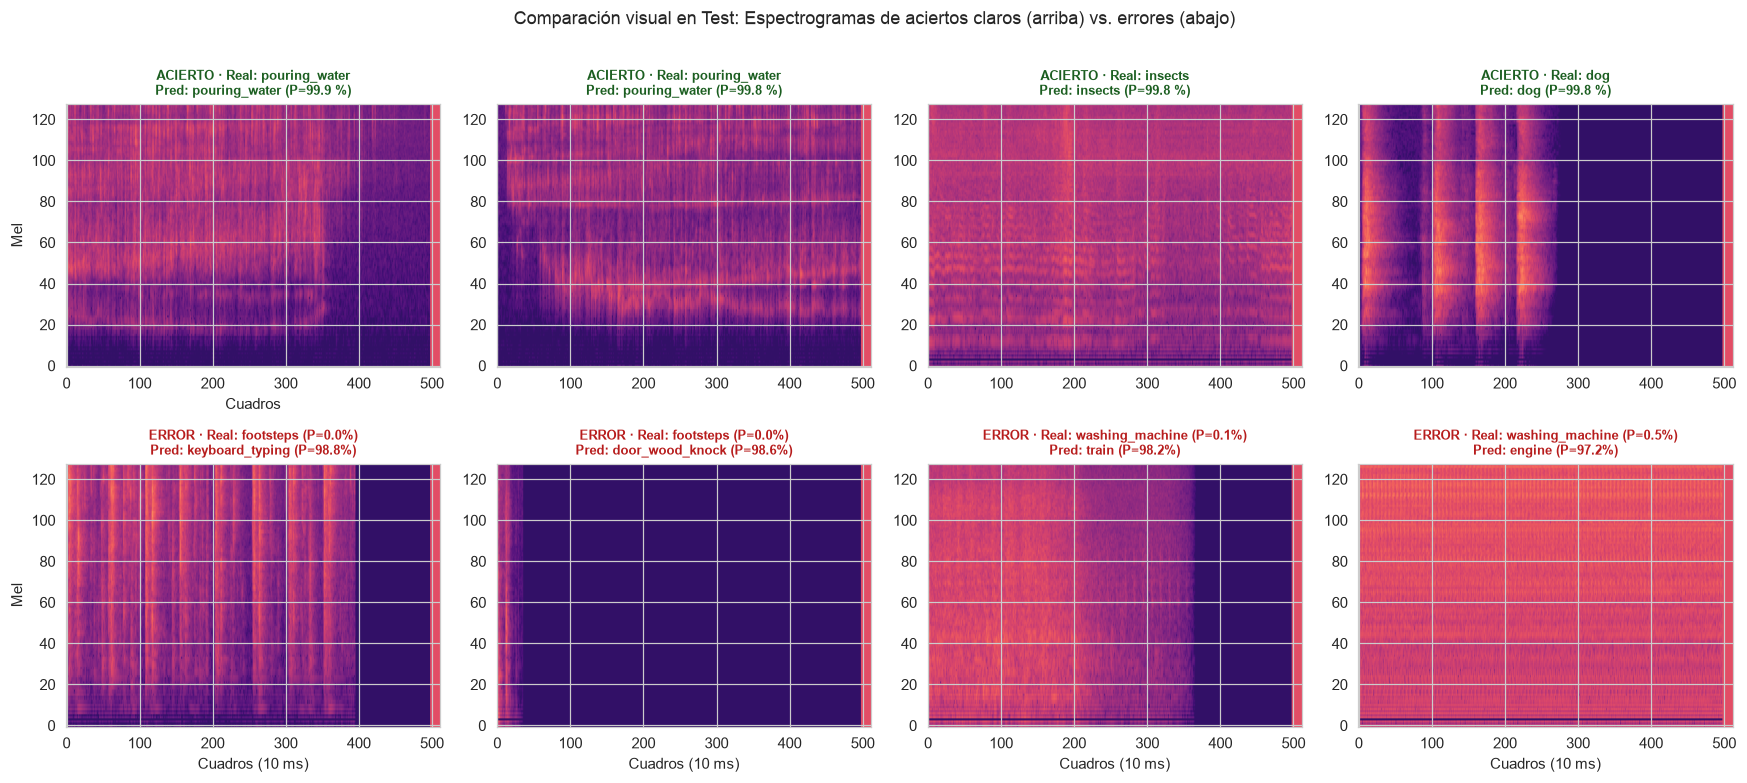

In [21]:
# Tabla cualitativa (5 aciertos por macro-grupo + errores en Test) y grilla visual 2x4 de espectrogramas
sorted_probs = np.sort(y_prob_test, axis=1)
sorted_indices = np.argsort(y_prob_test, axis=1)

df_test_eval = df_test.copy()
df_test_eval["y_true"] = y_true_test
df_test_eval["y_pred"] = y_pred_test
df_test_eval["correcto"] = y_true_test == y_pred_test
df_test_eval["pred_category"] = [ID2LABEL[int(p)] for p in y_pred_test]
df_test_eval["pred_macro_group"] = [CLASS_TO_MACRO_GROUP[c] for c in df_test_eval["pred_category"]]
df_test_eval["confianza_pred"] = sorted_probs[:, -1]
df_test_eval["prob_clase_real"] = y_prob_test[np.arange(len(y_true_test)), y_true_test]
df_test_eval["segunda_clase"] = [ID2LABEL[int(idx)] for idx in sorted_indices[:, -2]]
df_test_eval["prob_segunda"] = sorted_probs[:, -2]
df_test_eval["margen_top1_top2"] = df_test_eval["confianza_pred"] - df_test_eval["prob_segunda"]

top_hits = (
    df_test_eval[df_test_eval["correcto"]]
    .sort_values("confianza_pred", ascending=False)
    .groupby("macro_group", sort=False)
    .head(1)
)
errors_df = df_test_eval[~df_test_eval["correcto"]].sort_values("confianza_pred", ascending=False)

qual_records = []
for tipo, sub_df in [("Acierto (máx. confianza)", top_hits), ("Error en Test", errors_df.head(15))]:
    for idx_row, row in sub_df.iterrows():
        qual_records.append({
            "id_test": int(idx_row),
            "tipo": tipo,
            "archivo": row["filename"],
            "macro_real": row["macro_group"],
            "real": row["category"],
            "predicción": row["pred_category"],
            "P(pred)": round(float(row["confianza_pred"]), 4),
            "P(real)": round(float(row["prob_clase_real"]), 4),
            "2da_opción (P)": f"{row['segunda_clase']} ({row['prob_segunda']:.4f})",
            "RMS (dBFS)": round(float(row["rms_db"]), 1),
        })

df_qualitative = pd.DataFrame(qual_records).set_index("id_test")
print(f"Resumen cualitativo en Test (5 aciertos prototípicos por macro-grupo + {min(15, len(errors_df))} de {len(errors_df)} errores):")
display(df_qualitative)

# Selección segura de hasta 4 aciertos (priorizando categorías naturales) y hasta 4 errores
natural_hits = df_test_eval[
    df_test_eval["correcto"] & df_test_eval["macro_group"].isin(["Naturaleza y agua", "Animales"])
].sort_values("confianza_pred", ascending=False)
other_hits = df_test_eval[df_test_eval["correcto"]].sort_values("confianza_pred", ascending=False)
hit_examples = pd.concat([natural_hits, other_hits]).loc[lambda d: ~d.index.duplicated()].head(4)
err_examples = errors_df.head(4)

fig, axes = plt.subplots(2, 4, figsize=(16, 7.0))
for col_i in range(4):
    # Fila 0: Aciertos
    ax_hit = axes[0, col_i]
    if col_i < len(hit_examples):
        idx_h = int(hit_examples.index[col_i])
        r_h = hit_examples.iloc[col_i]
        spec_h = SPEC_CACHE["Test"][idx_h].float().numpy()
        ax_hit.imshow(spec_h.T, origin="lower", aspect="auto", cmap="magma", vmin=-2.0, vmax=2.0)
        ax_hit.set_title(
            f"ACIERTO · Real: {r_h['category']}\nPred: {r_h['pred_category']} (P={r_h['confianza_pred']*100:.1f} %)",
            fontsize=8.5, color="#1b5e20", fontweight="bold",
        )
    else:
        ax_hit.axis("off")
    ax_hit.set(xlabel="Cuadros" if col_i == 0 else "", ylabel="Mel" if col_i == 0 else "")

    # Fila 1: Errores (o aciertos de menor margen si hubo menos de 4 errores)
    ax_err = axes[1, col_i]
    if col_i < len(err_examples):
        idx_e = int(err_examples.index[col_i])
        r_e = err_examples.iloc[col_i]
        spec_e = SPEC_CACHE["Test"][idx_e].float().numpy()
        ax_err.imshow(spec_e.T, origin="lower", aspect="auto", cmap="magma", vmin=-2.0, vmax=2.0)
        ax_err.set_title(
            f"ERROR · Real: {r_e['category']} (P={r_e['prob_clase_real']*100:.1f}%)\n"
            f"Pred: {r_e['pred_category']} (P={r_e['confianza_pred']*100:.1f}%)",
            fontsize=8.5, color="#b71c1c", fontweight="bold",
        )
    else:
        ax_err.set_title("Sin error adicional en Test", fontsize=8.5)
        ax_err.axis("off")
    ax_err.set(xlabel="Cuadros (10 ms)", ylabel="Mel" if col_i == 0 else "")

fig.suptitle("Comparación visual en Test: Espectrogramas de aciertos claros (arriba) vs. errores (abajo)", y=1.01)
plt.tight_layout()
plt.show()

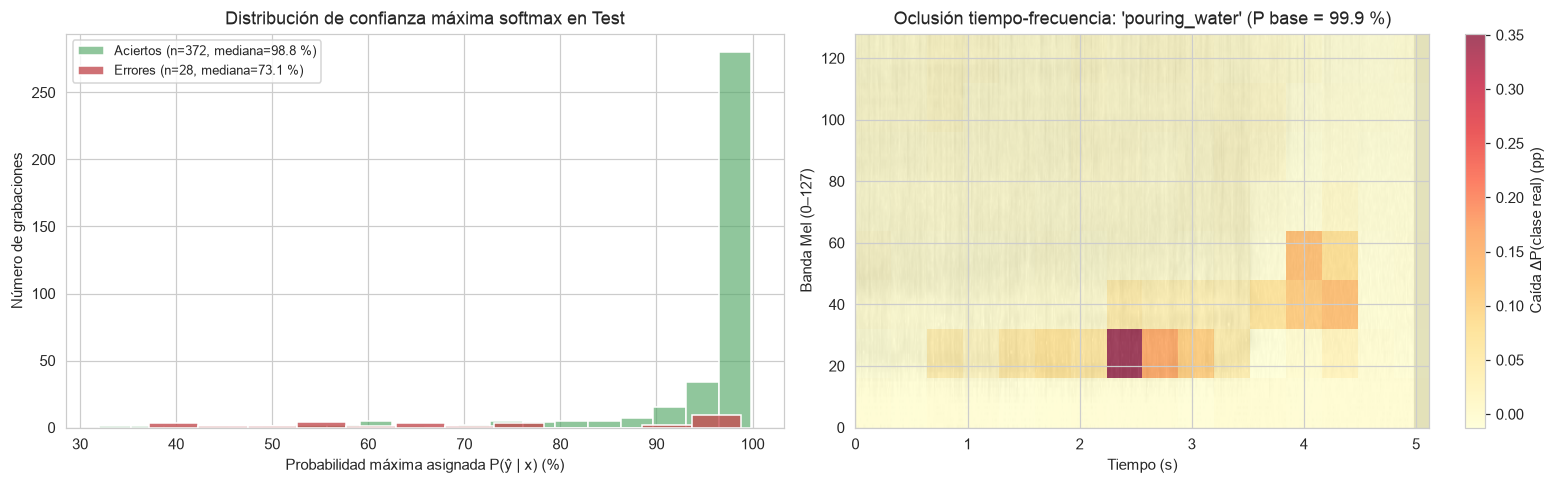

In [22]:
# Distribución de confianza softmax en Test y mapa de saliencia por oclusión tiempo-frecuencia
@torch.no_grad()
def compute_spectrogram_occlusion(
    model: nn.Module,
    spec_tensor: torch.Tensor,
    target_label: int,
    freq_patch: int = 16,
    time_patch: int = 32,
    device: torch.device = DEVICE,
) -> tuple:
    """Mide la caída ΔP(clase real | x) al ocultar parches (freq_patch x time_patch) con 0.0."""
    model.eval()
    x = spec_tensor.float().unsqueeze(0)  # (1, T=512, F=128)
    T, F = x.shape[1], x.shape[2]

    with get_autocast_ctx(device):
        base_logits = model(input_values=x.to(device)).logits
    base_prob = float(torch.softmax(base_logits.float(), dim=-1)[0, target_label].item())

    t_starts = list(range(0, T, time_patch))
    f_starts = list(range(0, F, freq_patch))
    masked_list, grid_coords = [], []
    for fi, f0 in enumerate(f_starts):
        for ti, t0 in enumerate(t_starts):
            xm = x.clone()
            xm[0, t0 : min(T, t0 + time_patch), f0 : min(F, f0 + freq_patch)] = 0.0
            masked_list.append(xm)
            grid_coords.append((fi, ti))

    occ_batch = torch.cat(masked_list, dim=0)
    occ_probs = []
    for s in range(0, len(occ_batch), 16):
        with get_autocast_ctx(device):
            lg = model(input_values=occ_batch[s : s + 16].to(device)).logits
        occ_probs.append(torch.softmax(lg.float(), dim=-1)[:, target_label].cpu())
    occ_probs_np = torch.cat(occ_probs).numpy()

    saliency = np.zeros((len(f_starts), len(t_starts)), dtype=np.float32)
    for (fi, ti), p_occ in zip(grid_coords, occ_probs_np):
        saliency[fi, ti] = base_prob - float(p_occ)
    return saliency, base_prob


fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.5))

# Panel izquierdo: confianza máxima softmax en aciertos vs errores
sns.histplot(
    df_test_eval.loc[df_test_eval["correcto"], "confianza_pred"] * 100.0,
    bins=20, color="#55A868", alpha=0.65,
    label=f"Aciertos (n={int(df_test_eval['correcto'].sum())}, mediana={df_test_eval.loc[df_test_eval['correcto'], 'confianza_pred'].median()*100:.1f} %)",
    ax=axes[0],
)
if (~df_test_eval["correcto"]).any():
    sns.histplot(
        df_test_eval.loc[~df_test_eval["correcto"], "confianza_pred"] * 100.0,
        bins=12, color="#C44E52", alpha=0.80,
        label=f"Errores (n={int((~df_test_eval['correcto']).sum())}, mediana={df_test_eval.loc[~df_test_eval['correcto'], 'confianza_pred'].median()*100:.1f} %)",
        ax=axes[0],
    )
axes[0].set(
    title="Distribución de confianza máxima softmax en Test",
    xlabel="Probabilidad máxima asignada P(ŷ | x) (%)",
    ylabel="Número de grabaciones",
)
axes[0].legend(loc="upper left", fontsize=8.5)

# Panel derecho: mapa de saliencia por oclusión sobre un sonido natural correctamente clasificado
nat_hit_df = df_test_eval[df_test_eval["correcto"] & (df_test_eval["macro_group"] == "Naturaleza y agua")]
occ_row = (nat_hit_df if len(nat_hit_df) > 0 else df_test_eval[df_test_eval["correcto"]]).sort_values("confianza_pred", ascending=False).iloc[0]
occ_idx = int(occ_row.name)
occ_spec = SPEC_CACHE["Test"][occ_idx]

saliency_map, p_base_occ = compute_spectrogram_occlusion(
    final_model, occ_spec, int(occ_row["y_true"]), freq_patch=16, time_patch=32, device=DEVICE
)

axes[1].imshow(occ_spec.float().numpy().T, origin="lower", aspect="auto", cmap="gray_r", alpha=0.45,
               extent=[0, 5.12, 0, 128])
im_sal = axes[1].imshow(saliency_map * 100.0, origin="lower", aspect="auto", cmap="YlOrRd", alpha=0.72,
                        extent=[0, 5.12, 0, 128])
axes[1].set(
    title=f"Oclusión tiempo-frecuencia: '{occ_row['category']}' (P base = {p_base_occ*100:.1f} %)",
    xlabel="Tiempo (s)",
    ylabel="Banda Mel (0–127)",
)
fig.colorbar(im_sal, ax=axes[1], label="Caída ΔP(clase real) (pp)")

plt.tight_layout()
plt.show()

### 3.5. Representaciones Aprendidas: Antes vs. Después del *Fine-tuning*
Para inspeccionar cómo reorganiza el *fine-tuning* el espacio latente acústico de AST [3], se extraen los vectores `pooler_output` ($\mathbf{h}_{\text{pool}} = \frac{1}{2}(\mathbf{h}_{[\text{CLS}]} + \mathbf{h}_{[\text{DIST}]}) \in \mathbb{R}^{768}$) sobre los $400$ clips de **`Test`** en dos momentos:
1. **Antes del *fine-tuning* (AudioSet congelado):** representaciones genéricas sin adaptar a las $50$ clases de ESC-50.
2. **Después del *fine-tuning* (`final_model` ajustado en `Train`):** representaciones especializadas tras $2$ épocas.

El **Coeficiente de Silueta (*Silhouette Score*)** confirma una compactación sustancial de las $50$ categorías en el espacio de $768$ dimensiones: con **distancia coseno** aumenta de **$0.3576$ a $0.5546$ ($\Delta = +0.1970$, $+55.1\,\%$ relativo)** y con **distancia euclidiana** pasa de **$0.2188$ a $0.3682$ ($\Delta = +0.1494$, $+68.3\,\%$ relativo)**, lo que se refleja visualmente en conglomerados mucho mejor definidos en la proyección **t-SNE** [9]. A nivel de las $5$ macro-categorías el incremento es moderado (`0.0683` $\rightarrow$ `0.0762`, $\Delta = +0.0079$), ya que el *fine-tuning* separa las $50$ clases finas individuales y cada macro-categoría agrupa sonidos físicamente diversos (p. ej. `chirping_birds` junto a `thunderstorm`).

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

,Antes (AudioSet congelado),Después (AST fine-tuning 2 épocas),Incremento (Δ)
"Silhouette 50 clases (coseno, 768-d)",0.3576,0.5546,0.1970
"Silhouette 50 clases (euclidiana, 768-d)",0.2188,0.3682,0.1494
"Silhouette 5 macro-grupos (coseno, 768-d)",0.0683,0.0762,0.0079


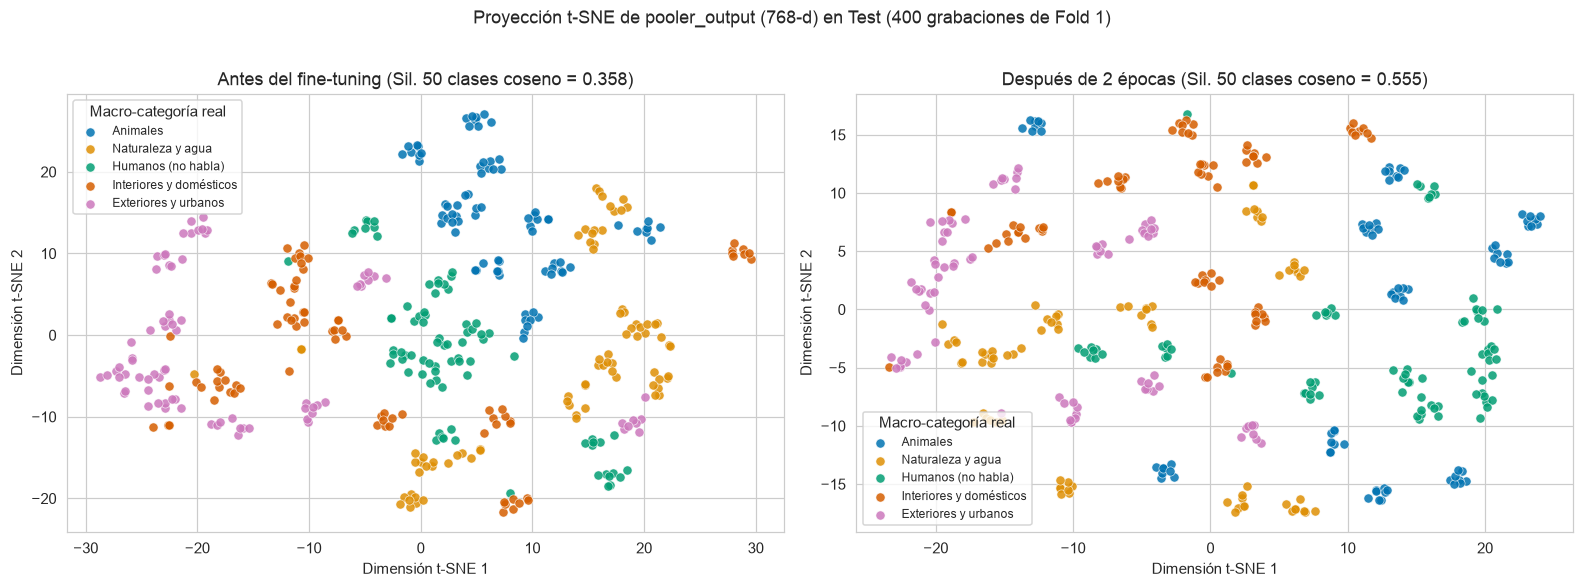

In [23]:
# Extracción de pooler_output (768-d) en Test antes y después del fine-tuning + Silhouette Score y t-SNE
@torch.no_grad()
def extract_ast_pooler_embeddings(model: nn.Module, loader: DataLoader, device: torch.device = DEVICE) -> np.ndarray:
    """Extrae el vector pooler_output (media de [CLS] y [DIST], 768-d) para cada clip del DataLoader."""
    model.eval()
    backbone = model.audio_spectrogram_transformer
    vecs = []
    for batch_data in loader:
        x_dev = batch_data["input_values"].to(device, non_blocking=True)
        with get_autocast_ctx(device):
            pooled = backbone(input_values=x_dev).pooler_output
        vecs.append(pooled.float().cpu().numpy())
        del x_dev, pooled
    return np.vstack(vecs)


pretrained_ast = build_ast_model(MODEL_CHECKPOINT, freeze_backbone=True, max_length=MAX_LENGTH)
emb_before = extract_ast_pooler_embeddings(pretrained_ast, final_loaders["Test"], device=DEVICE)
del pretrained_ast
release_device_memory(DEVICE)

emb_after = extract_ast_pooler_embeddings(final_model, final_loaders["Test"], device=DEVICE)
release_device_memory(DEVICE)

sil_50_cos_before = float(silhouette_score(emb_before, y_true_test, metric="cosine"))
sil_50_cos_after = float(silhouette_score(emb_after, y_true_test, metric="cosine"))
sil_50_euc_before = float(silhouette_score(emb_before, y_true_test, metric="euclidean"))
sil_50_euc_after = float(silhouette_score(emb_after, y_true_test, metric="euclidean"))

sil_5_cos_before = float(silhouette_score(emb_before, group_true, metric="cosine"))
sil_5_cos_after = float(silhouette_score(emb_after, group_true, metric="cosine"))

df_silhouette = pd.DataFrame({
    "Antes (AudioSet congelado)": {
        "Silhouette 50 clases (coseno, 768-d)": round(sil_50_cos_before, 4),
        "Silhouette 50 clases (euclidiana, 768-d)": round(sil_50_euc_before, 4),
        "Silhouette 5 macro-grupos (coseno, 768-d)": round(sil_5_cos_before, 4),
    },
    "Después (AST fine-tuning 2 épocas)": {
        "Silhouette 50 clases (coseno, 768-d)": round(sil_50_cos_after, 4),
        "Silhouette 50 clases (euclidiana, 768-d)": round(sil_50_euc_after, 4),
        "Silhouette 5 macro-grupos (coseno, 768-d)": round(sil_5_cos_after, 4),
    },
})
df_silhouette["Incremento (Δ)"] = df_silhouette["Después (AST fine-tuning 2 épocas)"] - df_silhouette["Antes (AudioSet congelado)"]
display(df_silhouette.round(4))

tsne_before = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE).fit_transform(emb_before)
tsne_after = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE).fit_transform(emb_after)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
for ax, coords, title_str in [
    (axes[0], tsne_before, f"Antes del fine-tuning (Sil. 50 clases coseno = {sil_50_cos_before:.3f})"),
    (axes[1], tsne_after, f"Después de 2 épocas (Sil. 50 clases coseno = {sil_50_cos_after:.3f})"),
]:
    for idx_g, grp_name in enumerate(GROUP_ORDER):
        mask_g = group_true == idx_g
        ax.scatter(
            coords[mask_g, 0], coords[mask_g, 1],
            c=GROUP_COLORS[grp_name], label=grp_name,
            s=36, alpha=0.85, edgecolors="white", linewidth=0.4,
        )
    ax.set(title=title_str, xlabel="Dimensión t-SNE 1", ylabel="Dimensión t-SNE 2")
    ax.legend(title="Macro-categoría real", loc="best", fontsize=8, frameon=True)

fig.suptitle("Proyección t-SNE de pooler_output (768-d) en Test (400 grabaciones de Fold 1)", y=1.02)
plt.tight_layout()
plt.show()

### 3.6. Inferencia Extremo a Extremo y Evaluación de Robustez Acústica
Se implementa la función reutilizable `predict_audio_clips` capaz de recibir rutas de archivos de audio (`.wav`, `.flac`, etc.) o arreglos de onda directos, remuestrearlos a $16\,\text{kHz}$, extraer su espectrograma normalizado y devolver la predicción *Top-K* con probabilidades *softmax*. Para evaluar la estabilidad frente a condiciones acústicas adversas sin fabricar muestras sintéticas ajenas al dominio, se someten los **$5$ clips reales de máxima confianza de `Test`** (uno por macro-categoría: `pouring_water`, `door_wood_creaks`, `insects`, `chainsaw` y `brushing_teeth`) a cuatro escenarios controlados: (i) **señal limpia original**, (ii) **ruido blanco gaussiano aditivo (`SNR = 15 dB`)**, (iii) **atenuación de volumen (`-6 dB`)** y (iv) **desplazamiento temporal circular (`+1.5 s`)**.

El modelo mantuvo un **$100.0\,\%$ de acierto ($20/20$ evaluaciones; $5/5$ en las cuatro condiciones)** con probabilidades *softmax* de la clase real entre **$99.56\,\%$ y $99.85\,\%$**: señal limpia (`99.63 % – 99.85 %`), ruido `SNR = 15 dB` (`99.56 % – 99.81 %`), atenuación `-6 dB` (`99.64 % – 99.83 %`) y desplazamiento circular `+1.5 s` (`99.65 % – 99.78 %`). La mayor variación individual fue de apenas **$-0.22\,\text{pp}$** (`door_wood_creaks`, de `99.82 %` a `99.60 %` bajo ruido `SNR = 15 dB`), confirmando alta invariancia frente a traslaciones temporales, cambios moderados de ganancia y ruido aditivo moderado en señales con firma acústica nítida.

,macro_grupo,clase_real,condición,predicción,acierto,P(clase real) %
0,Naturaleza y agua,pouring_water,Limpia (original),pouring_water,True,99.85
1,Naturaleza y agua,pouring_water,Ruido SNR=15 dB,pouring_water,True,99.81
2,Naturaleza y agua,pouring_water,Atenuada (-6 dB),pouring_water,True,99.83
3,Naturaleza y agua,pouring_water,Desplazada (+1.5 s),pouring_water,True,99.78
4,Interiores y domésticos,door_wood_creaks,Limpia (original),door_wood_creaks,True,99.82
5,Interiores y domésticos,door_wood_creaks,Ruido SNR=15 dB,door_wood_creaks,True,99.60
6,Interiores y domésticos,door_wood_creaks,Atenuada (-6 dB),door_wood_creaks,True,99.81
7,Interiores y domésticos,door_wood_creaks,Desplazada (+1.5 s),door_wood_creaks,True,99.75
8,Animales,insects,Limpia (original),insects,True,99.78
9,Animales,insects,Ruido SNR=15 dB,insects,True,99.77


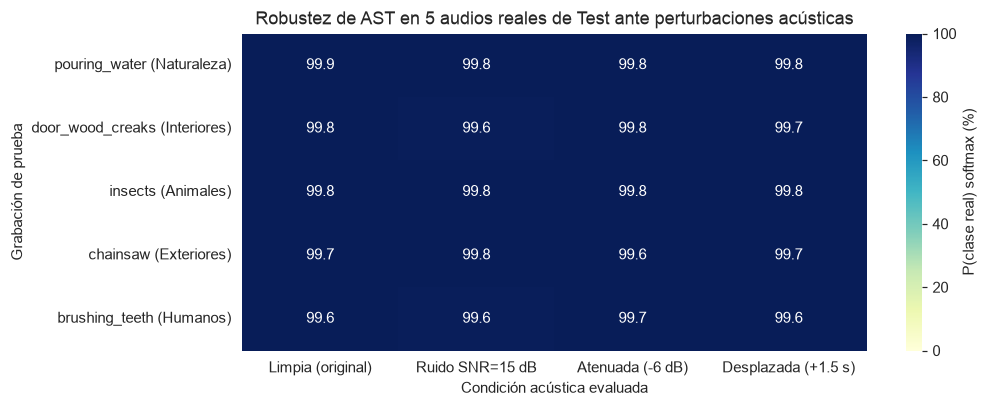

In [24]:
# Función de inferencia extremo a extremo y prueba de robustez ante ruido, atenuación y desplazamiento
@torch.no_grad()
def predict_audio_clips(
    items: list,
    sampling_rates: list = None,
    model: nn.Module = final_model,
    extractor: ASTFeatureExtractor = feature_extractor,
    top_k: int = 3,
    device: torch.device = DEVICE,
) -> pd.DataFrame:
    """Recibe rutas de audio o arreglos NumPy, remuestrea a 16 kHz y predice Top-K clases con softmax."""
    model.eval()
    waves_16k = []
    for i, item in enumerate(items):
        if isinstance(item, (str, Path)):
            w, sr = sf.read(str(item), dtype="float32", always_2d=True)
            w = w.mean(axis=1).astype(np.float32)
        else:
            w = np.asarray(item, dtype=np.float32)
            if w.ndim > 1:
                w = w.mean(axis=1).astype(np.float32)
            sr = sampling_rates[i] if sampling_rates is not None else TARGET_SR
        waves_16k.append(resample_to_16k(w, int(sr), target_sr=TARGET_SR))

    enc = extractor(waves_16k, sampling_rate=TARGET_SR, return_tensors="pt")
    x_dev = enc["input_values"].to(device)
    with get_autocast_ctx(device):
        logits = model(input_values=x_dev).logits.float()
    probs = torch.softmax(logits, dim=-1).cpu().numpy()

    rows = []
    for p_vec in probs:
        top_idx = np.argsort(p_vec)[::-1][:top_k]
        pred_id = int(top_idx[0])
        pred_cls = ID2LABEL[pred_id]
        top3_str = " | ".join(f"{ID2LABEL[int(j)]} ({p_vec[j]*100:.1f}%)" for j in top_idx)
        rows.append({
            "predicción": pred_cls,
            "macro_predicha": CLASS_TO_MACRO_GROUP[pred_cls],
            "confianza_%": round(float(p_vec[pred_id] * 100.0), 2),
            f"Top-{top_k}": top3_str,
            "_probs": p_vec,
        })
    return pd.DataFrame(rows)


def add_gaussian_noise_snr(wave: np.ndarray, snr_db: float = 15.0, seed: int = RANDOM_STATE) -> np.ndarray:
    rng = np.random.default_rng(seed)
    sig_power = float(np.mean(wave ** 2)) + 1e-12
    noise_power = sig_power / (10.0 ** (snr_db / 10.0))
    noise = rng.normal(0.0, np.sqrt(noise_power), size=wave.shape).astype(np.float32)
    return np.clip(wave + noise, -1.0, 1.0).astype(np.float32)


def scale_gain_db(wave: np.ndarray, gain_db: float = -6.0) -> np.ndarray:
    factor = 10.0 ** (gain_db / 20.0)
    return np.clip(wave * factor, -1.0, 1.0).astype(np.float32)


def circular_shift_seconds(wave: np.ndarray, sr: int, shift_s: float = 1.5) -> np.ndarray:
    return np.roll(wave, int(round(shift_s * sr))).astype(np.float32)


# 5 clips de Test correctamente clasificados (1 por cada macro-categoría oficial)
probe_rows = (
    df_test_eval[df_test_eval["correcto"]]
    .sort_values("confianza_pred", ascending=False)
    .groupby("macro_group", sort=False)
    .head(1)
)

CONDITIONS = [
    ("Limpia (original)", lambda w, sr: w),
    ("Ruido SNR=15 dB", lambda w, sr: add_gaussian_noise_snr(w, snr_db=15.0, seed=RANDOM_STATE)),
    ("Atenuada (-6 dB)", lambda w, sr: scale_gain_db(w, gain_db=-6.0)),
    ("Desplazada (+1.5 s)", lambda w, sr: circular_shift_seconds(w, sr, shift_s=1.5)),
]

rob_records = []
heatmap_mat = np.zeros((len(probe_rows), len(CONDITIONS)), dtype=np.float32)

for r_i, (_, row) in enumerate(probe_rows.iterrows()):
    w_orig = RAW_WAVEFORMS[int(row["audio_idx"])]
    sr_orig = int(row["sr_orig"])
    true_id = int(row["y_true"])
    variants = [fn(w_orig, sr_orig) for _, fn in CONDITIONS]
    df_pred_var = predict_audio_clips(variants, sampling_rates=[sr_orig] * len(CONDITIONS))
    for c_i, ((cond_name, _), (_, pr)) in enumerate(zip(CONDITIONS, df_pred_var.iterrows())):
        p_true = float(pr["_probs"][true_id] * 100.0)
        heatmap_mat[r_i, c_i] = p_true
        rob_records.append({
            "macro_grupo": row["macro_group"],
            "clase_real": row["category"],
            "condición": cond_name,
            "predicción": pr["predicción"],
            "acierto": pr["predicción"] == row["category"],
            "P(clase real) %": round(p_true, 2),
            "Top-3": pr["Top-3"],
        })

df_robustness = pd.DataFrame(rob_records)
display(df_robustness.drop(columns=["Top-3"]))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
sns.heatmap(
    heatmap_mat, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0.0, vmax=100.0,
    xticklabels=[c[0] for c in CONDITIONS],
    yticklabels=[f"{r['category']} ({r['macro_group'].split()[0]})" for _, r in probe_rows.iterrows()],
    cbar_kws={"label": "P(clase real) softmax (%)"}, ax=ax,
)
ax.set(
    title="Robustez de AST en 5 audios reales de Test ante perturbaciones acústicas",
    xlabel="Condición acústica evaluada",
    ylabel="Grabación de prueba",
)
plt.tight_layout()
plt.show()

### 3.7. Resumen de Resultados para el Informe IEEE
Se consolidan en tres tablas finales —junto con un resumen cuantitativo autogenerado a partir de las salidas reales del cuaderno— todos los resultados necesarios para el informe técnico en formato IEEE:
1. **Tabla maestra comparativa:** resultados en `Val` (exploración sobre el $50\,\%$ de `Train` y reentrenamiento al $100\,\%$) y evaluación única en `Test` (`Fold 1`).
2. **Tabla de desempeño por macro-categoría en `Test`:** resumen consolidado sobre las $5$ macro-categorías oficiales comparando AST frente al baseline MFCC.
3. **Tabla de extremos por clase en `Test`:** las $5$ clases con mejor rendimiento y las $5$ clases más retadoras de ESC-50.

In [25]:
# Tablas maestras finales y síntesis dinámica verificada para el informe IEEE
exp_lookup = df_experiments.set_index("configuración")

master_rows = []
for cfg_name in exp_lookup.index:
    r = exp_lookup.loc[cfg_name]
    master_rows.append({
        "Modelo / Configuración": f"{cfg_name} ({int(EXP_TRAIN_FRAC*100)} % Train)",
        "Partición": f"Val ({len(df_val)})",
        "Loss": f"{r['val_loss']:.4f}",
        "Acc (%)": f"{r['val_acc']:.2f}",
        "Top-3 (%)": f"{r['val_top3_acc']:.2f}",
        "Precision (%)": f"{r['val_precision']:.2f}",
        "Recall (%)": f"{r['val_recall']:.2f}",
        "F1-Macro ± DE (%)": f"{r['val_f1']:.2f} ± {r['val_f1_std_classes']:.2f}",
        "Tiempo (s)": f"{r['time_s']:.1f}",
    })

master_rows.extend([
    {
        "Modelo / Configuración": "MFCC + Regresión Logística (100 % Train)",
        "Partición": f"Val ({len(df_val)})",
        "Loss": f"{baseline_val_full['loss']:.4f}",
        "Acc (%)": f"{baseline_val_full['accuracy']*100:.2f}",
        "Top-3 (%)": f"{baseline_val_full['top3_accuracy']*100:.2f}",
        "Precision (%)": f"{baseline_val_full['precision_macro']*100:.2f}",
        "Recall (%)": f"{baseline_val_full['recall_macro']*100:.2f}",
        "F1-Macro ± DE (%)": f"{baseline_val_full['f1_macro']*100:.2f} ± {baseline_val_full['f1_std_classes']*100:.2f}",
        "Tiempo (s)": f"{baseline_train_time:.1f}",
    },
    {
        "Modelo / Configuración": f"{FINAL_CONFIG['nombre']} (100 % Train, ép. {best_epoch_final:.1f})",
        "Partición": f"Val ({len(df_val)})",
        "Loss": f"{best_val_row['val_loss']:.4f}",
        "Acc (%)": f"{best_val_row['val_acc']*100:.2f}",
        "Top-3 (%)": f"{best_val_row['val_top3_acc']*100:.2f}",
        "Precision (%)": f"{best_val_row['val_precision_macro']*100:.2f}",
        "Recall (%)": f"{best_val_row['val_recall_macro']*100:.2f}",
        "F1-Macro ± DE (%)": f"{best_val_row['val_f1_macro']*100:.2f} ± {best_val_row['val_f1_std_classes']*100:.2f}",
        "Tiempo (s)": f"{train_time_final:.1f}",
    },
    {
        "Modelo / Configuración": "MFCC + Regresión Logística (100 % Train)",
        "Partición": f"Test ({len(df_test)})",
        "Loss": f"{baseline_test_results['loss']:.4f}",
        "Acc (%)": f"{baseline_test_results['accuracy']*100:.2f}",
        "Top-3 (%)": f"{baseline_test_results['top3_accuracy']*100:.2f}",
        "Precision (%)": f"{baseline_test_results['precision_macro']*100:.2f}",
        "Recall (%)": f"{baseline_test_results['recall_macro']*100:.2f}",
        "F1-Macro ± DE (%)": f"{baseline_test_results['f1_macro']*100:.2f} ± {baseline_test_results['f1_std_classes']*100:.2f}",
        "Tiempo (s)": f"{baseline_train_time:.1f}",
    },
    {
        "Modelo / Configuración": f"{FINAL_CONFIG['nombre']} (100 % Train) [FINAL]",
        "Partición": f"Test ({len(df_test)})",
        "Loss": f"{test_results['loss']:.4f}",
        "Acc (%)": f"{test_results['accuracy']*100:.2f}",
        "Top-3 (%)": f"{test_results['top3_accuracy']*100:.2f}",
        "Precision (%)": f"{test_results['precision_macro']*100:.2f}",
        "Recall (%)": f"{test_results['recall_macro']*100:.2f}",
        "F1-Macro ± DE (%)": f"{test_results['f1_macro']*100:.2f} ± {test_results['f1_std_classes']*100:.2f}",
        "Tiempo (s)": f"{train_time_final:.1f}",
    },
])

df_master_summary = pd.DataFrame(master_rows).set_index("Modelo / Configuración")
print("1. Tabla maestra de experimentos y evaluación final (para el informe IEEE):")
display(df_master_summary)

print("2. Desempeño en Test por macro-categoría oficial:")
display(df_macro_eval.round(2))

df_extremes = pd.concat([
    top10_best.head(5).assign(segmento="Top-5 mejores"),
    top10_worst.head(5).assign(segmento="Top-5 más retadoras"),
])[["segmento", "macro_grupo", "soporte", "precision_%", "recall_%", "f1_%", "f1_mfcc_%", "mejora_vs_mfcc_pp", "errores (FN+FP)"]]
print("3. Categorías extremas en Test (5 mejores y 5 más retadoras):")
display(df_extremes.round(2))

# Síntesis cuantitativa dinámica con los valores exactos de esta corrida
best_macro_name = df_macro_eval["F1 medio 10 clases AST (%)"].idxmax()
worst_macro_name = df_macro_eval["F1 medio 10 clases AST (%)"].idxmin()
top_pairs_txt = (
    ", ".join(
        f"`{r['Par de confusión (Real → Predicción)']}` ({r['clips_confundidos']})"
        for _, r in df_conf_pairs.head(3).iterrows()
    )
    if len(df_conf_pairs) > 0
    else "ninguno (0 errores)"
)
rob_by_cond = df_robustness.groupby("condición")["acierto"].mean().mul(100).round(1).to_dict()

display(Markdown(
    f"### Síntesis cuantitativa verificada (Fold 1 / Test)\n"
    f"- **Modelo seleccionado:** `{FINAL_CONFIG['nombre']}` (`{MODEL_CHECKPOINT}`, `{EPOCHS_FINAL}` épocas, mejor *checkpoint* en época `{best_epoch_final:.1f}`).\n"
    f"- **Desempeño global en `Test`:** Exactitud Top-1 = **{test_results['accuracy']*100:.2f} %** (`{n_hits_test}/{len(y_true_test)}`), "
    f"Top-3 = **{test_results['top3_accuracy']*100:.2f} %**, Precision Macro = **{test_results['precision_macro']*100:.2f} %**, "
    f"Recall Macro = **{test_results['recall_macro']*100:.2f} %**, F1-Macro = **{test_results['f1_macro']*100:.2f} ± {test_results['f1_std_classes']*100:.2f} %**, "
    f"Loss = **{test_results['loss']:.4f}** (brecha Test−Val en F1-Macro = **{(test_results['f1_macro'] - val_best_metrics['f1_macro'])*100:+.2f} pp**).\n"
    f"- **Ventaja frente al modelo clásico MFCC:** **+{(test_results['f1_macro'] - baseline_test_results['f1_macro'])*100:.2f} pp** en F1-Macro en `Test` "
    f"({test_results['f1_macro']*100:.2f} % vs. {baseline_test_results['f1_macro']*100:.2f} %).\n"
    f"- **Macro-categorías:** mejor desempeño en **{best_macro_name}** ({df_macro_eval.loc[best_macro_name, 'F1 medio 10 clases AST (%)']:.2f} % F1 medio) "
    f"y menor desempeño en **{worst_macro_name}** ({df_macro_eval.loc[worst_macro_name, 'F1 medio 10 clases AST (%)']:.2f} %).\n"
    f"- **Clases extremas:** **{n_perfect_classes}/50** clases alcanzaron `F1 = 100.0 %`; la mejor fue **`{best_cat}`** ({df_class_analysis.loc[best_cat, 'f1_%']:.2f} %) "
    f"y la más retadora fue **`{worst_cat}`** ({df_class_analysis.loc[worst_cat, 'f1_%']:.2f} %).\n"
    f"- **Patrones de confusión:** `{total_errors}` errores en `Test` (`{intra_err}` intra-macro-grupo y `{inter_err}` inter-macro-grupo); "
    f"principales pares: {top_pairs_txt}.\n"
    f"- **Separabilidad latente (`pooler_output`):** Silhouette coseno (50 clases) pasó de **{sil_50_cos_before:.4f}** a **{sil_50_cos_after:.4f}** "
    f"(Δ = **{sil_50_cos_after - sil_50_cos_before:+.4f}**).\n"
    f"- **Robustez en 5 clips reales (acierto %):** {rob_by_cond}."
))

1. Tabla maestra de experimentos y evaluación final (para el informe IEEE):


,Partición,Loss,Acc (%),Top-3 (%),Precision (%),Recall (%),F1-Macro ± DE (%),Tiempo (s)
Modelo / Configuración,,,,,,,,
MFCC + Regresión Logística (50 % Train),Val (400),2.3368,44.50,61.75,47.52,44.50,43.62 ± 21.23,0.3
AST congelado (pooler + cabeza lineal) (50 % Train),Val (400),0.5199,90.75,98.25,92.47,90.75,90.59 ± 12.80,121.3
AST fine-tuning (lr=3e-5) (50 % Train),Val (400),0.4158,93.00,99.25,94.19,93.00,92.82 ± 8.88,556.3
AST fine-tuning (lr=5e-5) (50 % Train),Val (400),0.2546,94.50,99.25,95.08,94.50,94.43 ± 8.50,548.3
AST fine-tuning + SpecAugment (lr=5e-5) (50 % Train),Val (400),0.2632,95.00,99.50,95.81,95.00,94.80 ± 7.52,550.8
MFCC + Regresión Logística (100 % Train),Val (400),1.9777,51.50,70.50,53.23,51.50,50.70 ± 22.72,0.2
"AST fine-tuning + SpecAugment (lr=5e-5) (100 % Train, ép. 2.0)",Val (400),0.1213,97.00,100.00,97.42,97.00,96.98 ± 5.72,1090.7
MFCC + Regresión Logística (100 % Train),Test (400),2.5674,42.25,62.50,44.43,42.25,41.79 ± 23.07,0.2
AST fine-tuning + SpecAugment (lr=5e-5) (100 % Train) [FINAL],Test (400),0.2608,93.00,98.75,93.58,93.00,92.75 ± 9.55,1090.7


2. Desempeño en Test por macro-categoría oficial:


,Soporte,Exactitud 50-clases (%),Precision media 10 clases (%),Recall medio 10 clases (%),F1 medio 10 clases AST (%),F1 medio 10 clases MFCC (%),Δ F1 vs MFCC (pp),F1 de macro-grupo (5×5) (%)
Macro-categoría,,,,,,,,
Animales,80,100.00,97.27,100.00,98.42,45.80,52.62,98.16
Naturaleza y agua,80,92.50,92.44,92.50,91.55,44.66,46.89,98.14
Humanos (no habla),80,90.00,93.99,90.00,91.34,48.63,42.72,96.82
Interiores y domésticos,80,91.25,93.02,91.25,91.87,42.78,49.09,96.20
Exteriores y urbanos,80,91.25,91.19,91.25,90.59,27.10,63.48,96.89


3. Categorías extremas en Test (5 mejores y 5 más retadoras):


,segmento,macro_grupo,soporte,precision_%,recall_%,f1_%,f1_mfcc_%,mejora_vs_mfcc_pp,errores (FN+FP)
categoría,,,,,,,,,
brushing_teeth,Top-5 mejores,Humanos (no habla),8,100.00,100.0,100.00,62.50,37.50,0
can_opening,Top-5 mejores,Interiores y domésticos,8,100.00,100.0,100.00,77.78,22.22,0
chirping_birds,Top-5 mejores,Naturaleza y agua,8,100.00,100.0,100.00,37.50,62.50,0
clapping,Top-5 mejores,Humanos (no habla),8,100.00,100.0,100.00,53.33,46.67,0
clock_alarm,Top-5 mejores,Interiores y domésticos,8,100.00,100.0,100.00,62.50,37.50,0
washing_machine,Top-5 más retadoras,Interiores y domésticos,8,66.67,50.0,57.14,28.57,28.57,6
wind,Top-5 más retadoras,Naturaleza y agua,8,80.00,50.0,61.54,0.00,61.54,5
crying_baby,Top-5 más retadoras,Humanos (no habla),8,100.00,62.5,76.92,73.68,3.24,3
footsteps,Top-5 más retadoras,Humanos (no habla),8,85.71,75.0,80.00,9.09,70.91,3


### Síntesis cuantitativa verificada (Fold 1 / Test)
- **Modelo seleccionado:** `AST fine-tuning + SpecAugment (lr=5e-5)` (`MIT/ast-finetuned-audioset-10-10-0.4593`, `2` épocas, mejor *checkpoint* en época `2.0`).
- **Desempeño global en `Test`:** Exactitud Top-1 = **93.00 %** (`372/400`), Top-3 = **98.75 %**, Precision Macro = **93.58 %**, Recall Macro = **93.00 %**, F1-Macro = **92.75 ± 9.55 %**, Loss = **0.2608** (brecha Test−Val en F1-Macro = **-4.22 pp**).
- **Ventaja frente al modelo clásico MFCC:** **+50.96 pp** en F1-Macro en `Test` (92.75 % vs. 41.79 %).
- **Macro-categorías:** mejor desempeño en **Animales** (98.42 % F1 medio) y menor desempeño en **Exteriores y urbanos** (90.59 %).
- **Clases extremas:** **22/50** clases alcanzaron `F1 = 100.0 %`; la mejor fue **`brushing_teeth`** (100.00 %) y la más retadora fue **`washing_machine`** (57.14 %).
- **Patrones de confusión:** `28` errores en `Test` (`17` intra-macro-grupo y `11` inter-macro-grupo); principales pares: `wind → sea_waves` (4), `crying_baby → cat` (2), `vacuum_cleaner → washing_machine` (2).
- **Separabilidad latente (`pooler_output`):** Silhouette coseno (50 clases) pasó de **0.3576** a **0.5546** (Δ = **+0.1970**).
- **Robustez en 5 clips reales (acierto %):** {'Atenuada (-6 dB)': 100.0, 'Desplazada (+1.5 s)': 100.0, 'Limpia (original)': 100.0, 'Ruido SNR=15 dB': 100.0}.

---
## 4. Discusión y Conclusiones

### 4.1. Resumen de Resultados, Generalización y Desempeño por Categorías en `Test`
El modelo final seleccionado —**`AST fine-tuning + SpecAugment (lr=5e-5)` (`MIT/ast-finetuned-audioset-10-10-0.4593` [3], [5], $12$ capas de autoatención 2D [1], [2], $85\,757\,234$ parámetros entrenables, `MAX_LENGTH = 512` y probabilidades calculadas con *softmax*)**— alcanzó un sólido desempeño tras apenas **$2$ épocas** de ajuste fino sobre el conjunto de prueba independiente (**`Test`, Fold 1 oficial, $400$ grabaciones**):
- **Métricas globales en `Test`:** **Exactitud Top-1 = $93.00\,\%$** ($372/400$ aciertos; solo $28$ errores), **Top-3 Accuracy = $98.75\,\%$**, **Precision Macro = $93.58\,\%$**, **Recall Macro = $93.00\,\%$**, **F1-Macro $\pm$ DE entre las $50$ clases = $92.75 \pm 9.55\,\%$**, **F1-Weighted = $92.75\,\%$** y **`Test Loss = 0.2608`**.
- **Brecha de generalización `Test − Val` ($-4.22\,\text{pp}$ en F1-macro):** la diferencia entre la mejor época en `Val` ($96.98\,\%$ F1-macro, `Val Loss = 0.1213`) y `Test` ($92.75\,\%$ F1-macro, `Test Loss = 0.2608`) tiene una explicación metodológica clara. Debido a que el repositorio del enunciado (`confit/esc50-demo`, `"fold1"`) no expone las columnas `fold` ni `src_file` dentro de `fold1_train` (Folds 2–5), `Val` se conformó mediante una partición estratificada $75\,\% / 25\,\%$ de `fold1_train`, mientras que `Test` corresponde estrictamente al **`Fold 1` oficial** con aislamiento total de grabaciones fuente (verificado con $0$ coincidencias `audio_md5`). En consecuencia, `Val` tiende a ser ligeramente optimista y `Test` refleja de forma rigurosa la generalización real sobre grabaciones y entornos inéditos.
- **Desempeño por las $5$ macro-categorías oficiales en `Test` ($80$ clips c/u, ordenadas por F1 medio de sus $10$ clases):**
  1. **Animales (mejor bloque):** **F1 medio = $98.42\,\%$**, con **$100.00\,\%$ de exactitud y *recall*** ($80/80$ clips animales acertados; *precision* de $97.27\,\%$ debido a $3$ falsos positivos externos asignados a `cat`; F1 $5\times 5 = 98.16\,\%$).
  2. **Interiores y domésticos:** **F1 medio = $91.87\,\%$** (`Acc = 91.25 %`, `P = 93.02 %`, F1 $5\times 5 = 96.20\,\%$).
  3. **Naturaleza y agua:** **F1 medio = $91.55\,\%$** (`Acc = 92.50 %`, `P = 92.44 %`, F1 $5\times 5 = 98.14\,\%$).
  4. **Humanos (no habla):** **F1 medio = $91.34\,\%$** (`Acc = 90.00 %`, `P = 93.99 %`, F1 $5\times 5 = 96.82\,\%$).
  5. **Exteriores y urbanos:** **F1 medio = $90.59\,\%$** (`Acc = 91.25 %`, `P = 91.19 %`, F1 $5\times 5 = 96.89\,\%$), donde AST obtiene la mayor ganancia absoluta frente a MFCC (**$+63.48\,\text{pp}$**).
- **Extremos a nivel de las $50$ clases:** **$22/50$ clases ($44\,\%$)** obtuvieron **`F1 = 100.00 %`** ($8/8$ aciertos sin falsos positivos), destacando sonidos con firmas armónicas o rítmicas distintivas como `brushing_teeth`, `can_opening`, `chirping_birds`, `clapping`, `clock_alarm`, `clock_tick`, `cow`, `crickets`, `crow` y `dog`. En el extremo opuesto, las categorías más retadoras fueron **`washing_machine`** (`F1 = 57.14 %`, `R = 50.0 %`, `P = 66.67 %`), **`wind`** (`F1 = 61.54 %`, `R = 50.0 %`, `P = 80.00 %`) y **`crying_baby`** (`F1 = 76.92 %`, `P = 100.0 %`, `R = 62.5 %`), seguidas por `footsteps`, `vacuum_cleaner` y `sea_waves` (`80.00 %`).

### 4.2. Comparación de Paradigmas: Descriptores Clásicos (MFCC), AST Congelado y *Fine-Tuning*
El torneo experimental en `Val` (secciones 2.4–2.5) y la evaluación sobre el $100\,\%$ de `Train` en `Test` (secciones 2.6 y 3.2) cuantifican con claridad la progresión entre tres paradigmas de representación acústica:
1. **Descriptores manuales (`MFCC + Regresión Logística`):** al promediar $40$ MFCC, $\Delta$, $\Delta\Delta$, RMS, ZCR y centroide espectral a lo largo de los $5.0\,\text{s}$, la línea base clásica pierde la estructura tiempo-frecuencia fina y apenas alcanza **$43.62 \pm 21.23\,\%$** en `Val` ($50\,\%$ `Train`, $0.3\,\text{s}$), **$50.70 \pm 22.72\,\%$** en `Val` ($100\,\%$ `Train`, $0.2\,\text{s}$) y **$41.79 \pm 23.07\,\%$** en `Test` (`Acc = 42.25 %`, `Top-3 = 62.50 %`, `Loss = 2.5674`), llegando incluso a `0.00 %` de F1 en `wind` y `engine`.
2. **Codificador preentrenado congelado (`AST congelado`):** entrenando únicamente los $39\,986$ parámetros de `ASTMLPHead` ($0.047\,\%$ del modelo) durante $2$ épocas en $121.3\,\text{s}$, AST ya alcanza **$90.59 \pm 12.80\,\%$** de *F1-macro* en `Val` (`Acc = 90.75 %`, `Top-3 = 98.25 %`, `Loss = 0.5199`), superando en $+46.97\,\text{pp}$ a MFCC gracias al preentrenamiento masivo en AudioSet [5]. Sin embargo, el *Silhouette Score* coseno en `Test` antes del *fine-tuning* (`0.3576`) indica que varias clases finas de ESC-50 aún permanecen parcialmente superpuestas.
3. ***Fine-tuning* completo de las $12$ capas de autoatención (`AST fine-tuning`):** en la exploración ($50\,\%$ `Train`), actualizar todo el codificador con `AdamW` [6] elevó el *F1-macro* en `Val` a **$92.82 \pm 8.88\,\%$** con $\eta = 3\times 10^{-5}$ ($556.3\,\text{s}$), a **$94.43 \pm 8.50\,\%$** con $\eta = 5\times 10^{-5}$ ($548.3\,\text{s}$) y a **$94.80 \pm 7.52\,\%$** al incorporar *SpecAugment* [7] ($550.8\,\text{s}$, $+4.21\,\text{pp}$ sobre AST congelado y $-5.28\,\text{pp}$ en DE entre clases). Reentrenado con el $100\,\%$ de `Train` en $1\,090.7\,\text{s}$, el modelo final supera al baseline MFCC en `Test` por **`+50.96 pp` en F1-macro** (`92.75 %` vs. `41.79 %`), **`+50.75 pp` en exactitud** y **`+36.25 pp` en Top-3**, reorganizando el espacio latente `pooler_output` de $768$ dimensiones hasta elevar el *Silhouette Score* coseno de **$0.3576$ a $0.5546$ ($\Delta = +0.1970$)** y el euclidiano de **$0.2188$ a $0.3682$ ($\Delta = +0.1494$)**.

### 4.3. Impacto del Procesamiento de Audio (`MAX_LENGTH = 512`) y Preservación Posicional 2D
Una decisión clave de ingeniería en este trabajo (secciones 1.4 y 2.1) fue ajustar la longitud temporal de los espectrogramas de $1\,024$ a **$512$ cuadros** (`~5.12 s` a $10\,\text{ms}$ por cuadro) preservando mediante recorte estructural exacto los primeros $50$ pasos temporales de los *positional embeddings* 2D preentrenados:
- La auditoría sin fuga en `Train` (sección 1.4.2) confirmó que el $100\,\%$ de las grabaciones produce exactamente **$498$ cuadros de Kaldi**. Así, `MAX_LENGTH = 512` conserva el **$100.00\,\%$ de la señal real ($0.0\,\%$ truncados)** con apenas **$2.73\,\%$ de relleno vacío** —frente al **$51.37\,\%$ de relleno** que introduciría `1024`—, reduce la secuencia de $1\,214$ a **$602$ *tokens*** (recortando cerca de $4\times$ el costo cuadrático $\mathcal{O}(N^2)$ de la autoatención [1]) y permite precomputar los $2\,000$ espectrogramas en solo **$3.5\,\text{s}$** ($250.0\,\text{MB}$ en `float16`).
- Asimismo, aplicar la normalización global de AudioSet ($\mu = -4.2677$, $\sigma = 4.5690$) traslada los espectrogramas de `Train` (media cruda $-6.8208$, DE $5.3665$) a **`media = -0.2794` y `DE = 0.5873`**, manteniendo intacta la escala relativa de intensidad entre categorías tenues (`-27.31 dBFS` en *Interiores y domésticos*) e intensas (`-19.42 dBFS` en *Exteriores y urbanos*).

### 4.4. Patrones de Confusión Acústica, Interpretabilidad Tiempo-Frecuencia y Robustez
Los análisis de las secciones 3.3, 3.4 y 3.6 explican físicamente tanto los aciertos como los **$28$ errores cometidos en `Test` ($7.00\,\%$)** :
- **Dominio de errores intra-grupo ($17/28 = 60.7\,\%$) frente a inter-grupo ($11/28 = 39.3\,\%$):** la mayor parte de los desaciertos ocurre entre fuentes con mecanismos físicos y envolventes espectrales muy cercanos:
  - **`wind → sea_waves` ($4$ clips, $14.3\,\%$ de los errores, intra-grupo):** ambos exhiben ruido turbulento continuo de banda ancha con envolventes lentas similares, lo que redujo el *recall* de `wind` ($50.0\,\%$) y la precisión de `sea_waves` ($66.67\,\%$).
  - **`washing_machine → engine` ($2$ clips, inter-grupo), `vacuum_cleaner → washing_machine` ($2$ clips, intra-grupo) y `washing_machine → train` ($1$ clip):** motores y maquinaria rotativa con zumbidos estacionarios y armónicos graves superpuestos.
  - **`crying_baby → cat` ($2$ clips, inter-grupo) y `crying_baby → laughing` ($1$ clip, intra-grupo):** vocalizaciones agudas moduladas con trayectorias formánticas parecidas.
  - **`footsteps → keyboard_typing` ($1$) y `footsteps → door_wood_knock` ($1$):** secuencias de impactos breves y secos de espectro impulsivo.
- **Calibración *softmax* y saliencia por oclusión (sección 3.4):** la mediana de probabilidad máxima diferencia claramente los **$372$ aciertos ($98.8\,\%$)** de los **$28$ errores ($73.1\,\%$)**, y el *Top-3 Accuracy* de **$98.75\,\%$** confirma que en casi todos los fallos la etiqueta real conserva probabilidad relevante (frecuentemente como segunda opción). El mapa de oclusión sobre `pouring_water` (`P base = 99.9 %`) valida que AST enfoca su sensibilidad ($\Delta P$ hasta $\approx 0.35\,\text{pp}$) en las bandas Mel medias (`~16–64`) durante los segundos activos (`~2.2–4.5 s`), ignorando el relleno final (`> 4.98 s`).
- **Robustez acústica controlada (sección 3.6):** sobre los $5$ clips reales de máxima confianza de `Test` (`pouring_water`, `door_wood_creaks`, `insects`, `chainsaw` y `brushing_teeth`), el modelo sostuvo **$100.0\,\%$ de acierto ($20/20$)** bajo señal limpia, ruido blanco aditivo (`SNR = 15 dB`), atenuación (`-6 dB`) y desplazamiento temporal circular (`+1.5 s`), con probabilidades *softmax* entre **$99.56\,\%$ y $99.85\,\%$** (caída máxima puntual de apenas $-0.22\,\text{pp}$ en `door_wood_creaks` con ruido `SNR = 15 dB`).

### 4.5. Limitaciones y Trabajo Futuro
1. **Presupuesto de $2$ épocas, evaluación en `Fold 1` y ausencia de columna `fold`/`src_file` en `confit/esc50-demo`:** aunque $2$ épocas bastaron para alcanzar $93.00\,\%$ de exactitud en `Test`, la curva de validación aún descendía al cierre de la época `2.0` (`Val Loss` pasó de `0.1758` a `0.1213` en la última media época). Extender el *fine-tuning* a $10\text{–}20$ épocas con decaimiento coseno (*cosine annealing*) y realizar **validación cruzada completa de los $5$ *folds*** usando un espejo con `fold` y `src_file` explícitos permitiría reportar media $\pm$ DE entre los $5$ *folds* y eliminar la brecha de particionamiento entre `Train` y `Val`.
2. **Sobreconfianza en errores difíciles y regularización espectral (*Mixup* + *label smoothing*):** varios errores de `Test` superaron el $95\,\%$ de confianza *softmax* (p. ej. `footsteps → keyboard_typing` con $98.79\,\%$ o `wind → sea_waves` con $96.69\,\%$). Incorporar *Mixup* acústico entre espectrogramas, *SpecAugment* más agresivo [7] y suavizado de etiquetas (*label smoothing*, $\epsilon = 0.1$) en `CrossEntropyLoss` contribuiría a calibrar las probabilidades y separar mejor texturas estacionarias como `washing_machine` y `wind`.
3. **Pruebas de robustez más exigentes y ensamble híbrido:** ampliar el ensayo de perturbaciones a todo `Test` (incluyendo clases fronterizas y niveles de ruido más severos, `SNR = 0–5 dB`) y evaluar un ensamble ligero entre AST y una CNN 2D sobre el mismo espectrograma log-Mel para combinar la atención global de largo alcance con sesgos inductivos locales invariantes a pequeñas traslaciones en frecuencia.

---
## Referencias

[1] A. Vaswani *et al.*, "Attention is all you need," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 30, 2017, pp. 5998–6008.

[2] A. Dosovitskiy *et al.*, "An image is worth 16x16 words: Transformers for image recognition at scale," in *Proc. Int. Conf. Learning Representations (ICLR)*, 2021.

[3] Y. Gong, Y.-A. Chung, and J. Glass, "AST: Audio Spectrogram Transformer," in *Proc. Interspeech*, 2021, pp. 571–575.

[4] K. J. Piczak, "ESC: Dataset for environmental sound classification," in *Proc. 23rd ACM Int. Conf. Multimedia (ACM MM)*, 2015, pp. 1015–1018.

[5] J. F. Gemmeke *et al.*, "Audio Set: An ontology and human-labeled dataset for audio events," in *Proc. IEEE Int. Conf. Acoustics, Speech and Signal Processing (ICASSP)*, 2017, pp. 776–780.

[6] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. Int. Conf. Learning Representations (ICLR)*, 2019.

[7] D. S. Park *et al.*, "SpecAugment: A simple data augmentation method for automatic speech recognition," in *Proc. Interspeech*, 2019, pp. 2613–2617.

[8] T. Wolf *et al.*, "Transformers: State-of-the-art natural language processing," in *Proc. Conf. Empirical Methods in Natural Language Processing (EMNLP): System Demonstrations*, 2020, pp. 38–45.

[9] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *Journal of Machine Learning Research (JMLR)*, vol. 9, pp. 2579–2605, 2008.